# From Forecasts to Policies: Inventory Planning with Lead Times

In the first post, ["From Forecasts to Decisions: Inventory Planning with Probabilistic Programming"](https://juanitorduz.github.io/forecast_to_decision/), we sold one product and decided today how many units to order for each of the next $15$ days. We turned the posterior predictive draws of a demand model into demand scenarios and ran an inventory simulator on them. Then we chose the orders that minimize a loss with two unit costs: a holding cost per unit left over and a lost margin per unit of demand that we cannot serve.

That problem had three simplifications, which the first post lists among its limitations. In this notebook we remove them:

- **Lead time.** In the first post every order arrived on the day for which we planned it. Here an order placed on day $t$ arrives at the start of day $t + L$, where $L$ is the **lead time** in days.
- **Policies.** In the first post we fixed all $15$ orders on day one. Here the order of each day is a function of what we have observed up to that day. We call such a function a **policy**, and we call a vector of orders fixed in advance a **plan**.
- **Weekly forecast.** In the first post we ran the forecast once, on day one. Here we run it again after the first week: on day $8$ we update it with the demand of days $1$ to $7$. A second update on day $15$ would only change the last order, so we leave it out for simplicity.

These changes bring the problem closer to practice, where a delivery takes time and a retailer looks at the stock before it orders. How often a retailer orders and runs its forecast depends on the product and the supplier. Some stores order every day, and many order once or twice a week, since every order and every delivery takes work. For example, in the VN2 challenge described by [Szabłowski (2026)](https://arxiv.org/abs/2601.18919), which motivated the first post, a delivery takes two weeks and the decisions follow a weekly cycle. In this notebook we place an order every day, as in the first post, and we run the forecast every week. It is easy to adapt the techniques below to a longer order cycle.

We compare five ways of placing the orders. The first one is the plan of the first post, a vector of orders that we fix on day one. It is our baseline, and each of the other four ways adds one idea to the one before it. Let's see the reason for each idea first.

The first idea is to look at the stock. A plan cannot react to the demand, because all its orders are fixed before the first sale. If the first days sell more than we expected, the plan still sends the same orders and the shelf runs empty, and if they sell less, the same orders pile up. A **base-stock policy** looks at the stock every day instead. It has a target level for the stock on the shelf plus the orders on their way, and it orders the difference.

The second idea is to train the target levels. The first post gives a candidate for them: a high quantile of the demand that the order has to cover, under the forecast. This quantile is the best level when the customers wait for the next delivery. When the sale is lost instead and the order takes time to arrive, it is not, because a sale that we lose takes no stock away, so the stock lasts longer than the quantile assumes. There is no simple formula for the best level in this case. So we add one number per day to the quantile, an **offset**, and we look for the offsets with the lowest average loss in the simulator. We call this search **training**. It leaves the forecast as it is and fits only the rule that turns the forecast into orders.

The third idea is to update the forecast. The two base-stock policies above use the forecast of day one for the whole horizon. So the target level of day $10$ is the same number after a strong first week and after a slow one, although the first week tells us about the demand of the next days. With the **weekly forecast**, the levels from day $8$ on come from a forecast that has seen the first week.

The fourth idea is to give the policy more to read. A base-stock policy reads the stock through one number, the stock on the shelf plus the orders on their way. It cannot tell a full shelf from a large order that arrives tomorrow, and between two forecast updates its target level does not move with the latest sales. A **neural network** can read each of these quantities. We let it add a correction to the target level and train it in the same simulator, to see how much a more flexible rule can still gain.

These are the five ways of placing the orders, in the order in which they add the ideas. A plan is a policy too, one that ignores what it observes, so from here on we call all five of them policies:

- **Fixed plan.** This is the expected cost plan of the first post, now with a lead time. It uses the forecast of day one and nothing that happens after day one.
- **Base-stock (day-one forecast).** On every day it orders the difference between a target level and the stock that is on the shelf or on its way. The target level of a day is a quantile of the demand that the order has to cover, under the forecast of day one.
- **Base-stock (day-one forecast, trained).** It uses the same target levels plus one trained offset per day.
- **Base-stock (weekly forecast, trained).** It is the same rule with the target levels of the weekly forecast, so from day $8$ on the levels use the demand of the first week. It has its own trained offsets.
- **Neural.** A small neural network adds a correction to the target level of `Base-stock (weekly forecast, trained)`.

All five place their orders with the same lead time $L$. We solve the fixed plan on a simulator that delivers every order $L$ days after we place it. The base-stock and neural policies count the orders on their way as stock, and their target level covers the demand of the $L + 1$ days until the order of the next day arrives.

The simulator of the first post is a `jax.lax.scan` over the days, and JAX differentiates through it. So we can train a policy in the same way we solved for the plan: we write the order of each day as `policy(params, observation)` inside the scan and run gradient descent on the parameters over the demand scenarios. [Alvo et al. (2023)](https://arxiv.org/abs/2306.11246) call this approach hindsight differentiable policy optimization and test it on a range of inventory problems.

We want to answer four questions, for lead times of $0$ to $3$ days:

1. How much of the expected loss of the fixed plan do we remove when the order of each day depends on the stock that we observe?
2. Does training the target levels through the simulator lower the loss further?
3. With trained levels, how much does the update of the forecast after the first week lower the loss?
4. Does a neural network on top of `Base-stock (weekly forecast, trained)` lower the loss further?

We keep the data generating process, the forecasting model with its priors, the costs and the initial stock of the first post. A policy needs an objective to train on, and of the four decision rules of the first post the expected cost rule and the conditional value at risk (CVaR) rule provide one. We use the first one everywhere and the second one in the *Tail Risk* section.

We also make three assumptions, and we come back to them in the *Model Limitations* section. The last two favor the policies:

- **Daily orders.** We place an order every day, and an order has no fixed cost.
- **Observed demand.** We observe the demand of a day even when the shelf was empty, while in practice we only see the sales.
- **One forecast origin.** Every scenario starts from the same history and the same stock, so we train the policies for these $15$ days only.

We assume that you have read the first post. We recall its terms when we use them, and we do not repeat the derivation of the loss, the forecasting model or its diagnostics.

Here is the outline:

1. **Prepare Notebook.** Imports and plotting defaults.
2. **The Decision Problem.** The lead time and the days on which we count the cost.
3. **Policies.** What a policy observes, what training means, and the five policies with a worked example.
4. **Demand Scenarios.** The demand model of the first post written as components, the data, the fit, and the scenario sets for training, validation and testing.
5. **Forecast Updates.** A fast update of the forecast with the demand of the first week, which stands in for a refit of the model, and the weekly forecast of every scenario.
6. **Inventory Simulator.** The simulator with a lead time, in which a policy places the order of each day.
7. **Policy Training.** The fixed plan, the base-stock policies and the neural policy, which we train by gradient descent through the simulator.
8. **Out of Sample Evaluation.** The expected loss by lead time, the paired differences, the gain by expected demand, the demand since the update, the stock and the stockouts, the cost ratio and the tail risk.
9. **Conclusion.** What we learned.
10. **Next Steps.** Extensions.
11. **Appendix.** The forecast update against a refit of the forecasting model.

## Prepare Notebook

In [1]:
import numpyro

# `dynestyx` starts JAX when we import it, so we set the number of devices first
numpyro.set_host_device_count(4)

In [2]:
import math
from collections.abc import Callable
from enum import StrEnum
from typing import Final, NamedTuple

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpyro.distributions as dist
import optax
import polars as pl
import preliz as pz
import seaborn as sns
import xarray as xr
from dynestyx import DiscreteTimeSimulator, DynamicalModel, Filter
from dynestyx.configs import EKFConfig
from flax import nnx
from jax import random
from jaxtyping import (
    Array,
    Bool,
    Float,
    Int,
    PRNGKeyArray,
    PyTree,
    ScalarLike,
    UInt32,
)
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, PercentFormatter
from numpyro import handlers
from numpyro.handlers import do
from numpyro.infer import MCMC, NUTS, Predictive
from numpyro.infer.reparam import LocScaleReparam
from numpyro_forecast import Horizon, forecast, innovations, predict, to_datatree
from numpyro_forecast.contrib.dynestyx import end_state, start_state, state_space
from numpyro_forecast.features import fourier_features
from numpyro_forecast.metrics import crps_empirical
from numpyro_forecast.typing import ForecastModel

seed: int = 42
rng_key: PRNGKeyArray = random.PRNGKey(seed)

CI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "eti"
az.rcParams["stats.ci_prob"] = CI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"
pl.Config(float_precision=1, tbl_width_chars=160)

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

## The Decision Problem

Let's start with the setting of the first post. Let $H = 15$ be the **number of days on which we order**, the planning horizon of the first post, and let $D_t$ be the **demand on day** $t$. We start with $I_0$ units on the shelf. Customers buy what is there and go elsewhere for the rest, so the demand that we cannot serve is lost.

Two unit costs define the loss. A unit that sits on the shelf at the end of a day costs the **holding cost** $h$, and a unit of demand that we cannot serve costs the **lost margin** $p$. As in the first post we take $h = 0.1$, $p = 2$ and $I_0 = 50$.

### Lead Time

Let $L \geq 0$ be the **lead time** in days and let $a_t \geq 0$ be the **order placed on day** $t$. The order arrives at the start of day $t + L$. The orders that we have placed and that have not arrived yet are the **pipeline**. Note that in the first post the letter $L$ was the loss. Here $L$ is the lead time, as is usual in inventory theory, and we write $C$ for the loss and $J$ for the expected loss.

A day $t$ has five steps:

1. **Receive.** For $L \geq 1$ the order placed on day $t - L$ arrives.
2. **Observe.** We look at the stock, the pipeline, the demand of the last days and the latest forecast.
3. **Order.** If $t \leq H$ we place the order $a_t$. For $L = 0$ it arrives at once.
4. **Sell.** The demand $D_t$ arrives and we sell what the shelf allows.
5. **Pay.** We pay the holding cost on the units left over and the lost margin on the demand that we could not serve.

Let $I_{t-1}$ be the **stock on hand** at the end of day $t - 1$. The **stock available** for sale on day $t$ is $y_t = I_{t-1} + a_{t-L}$, the stock on hand plus the order that arrives. With $L = 0$ this is $y_t = I_{t-1} + a_t$, the setting of the first post. The **lost sales** $U_t$ and the stock on hand at the end of the day are

$$
U_t = (D_t - y_t)^{+}, \qquad I_t = (y_t - D_t)^{+},
$$

where $(u)^{+} = \max(u, 0)$, and the cost of the day is $h \, I_t + p \, U_t$.

For $L \geq 1$ the orders $a_{1-L}, \dots, a_0$ were placed before day one. They are the **initial pipeline**. We fix each of them at the median forecast of the demand of the day on which it arrives, and we use the same initial pipeline for every policy.

The **inventory position** is the stock on hand plus the pipeline when we decide the order of day $t$, after the arrival of step $1$:

$$
\text{IP}_t = I_{t-1} + \sum_{s=t-L}^{t-1} a_s.
$$

With $L = 0$ the sum is empty and the inventory position is the stock on hand. With $L \geq 1$ the order $a_{t-L}$ arrives in step $1$ of day $t$, so the inventory position is the stock available $y_t$ plus the $L - 1$ orders that are still on their way.

The inventory position is the right quantity to compare with a target, for two reasons:

- **No double orders.** The orders in the pipeline are stock that we have already bought. A rule that looks only at the shelf would order the same missing units again on every day until they arrive.
- **Coverage.** The order of day $t + 1$ arrives after day $t + L$. So the inventory position after the order of day $t$, $\text{IP}_t + a_t$, is the only stock that can serve the demand of the $L + 1$ days $t, \dots, t + L$.

### Cost Window

An order placed on day $t$ cannot change anything before day $t + L$. This has two consequences.

- **First days.** The stock of days $1$ to $L$ depends only on the initial stock, the initial pipeline and the demand. No order can change it, so the cost of these days is the same for every policy.
- **Last orders.** The orders of the last $L$ ordering days arrive after day $H$. If we stopped counting on day $H$, these orders would cost nothing and serve nothing.

So we count the cost on the days $L + 1, \dots, H + L$, the **cost window**. It has $H$ days for every lead time, and every order arrives inside it. The **loss** $C$ of a demand path is the sum of the daily costs over the cost window,

$$
C = \sum_{t=L+1}^{H+L} \left[ h \, I_t + p \, U_t \right].
$$

As in the first post, we report the loss as a plain number, in the currency of $h$ and $p$.

We store the lengths, the lead times and the day of the forecast update in the `Setup` tuple of the first post, which gets three new fields, and the costs and the initial stock in the `InventoryConfig` tuple.

In [3]:
class Setup(NamedTuple):
    """Lengths of the history and the horizon, promotion settings and lead times."""

    t_obs: int = 364  # one year of daily history
    horizon: int = 15  # days on which we place an order
    discount: float = 0.3  # price cut in a promotion week
    promo_prob: float = 0.1  # chance that a given week of the history is a promotion
    lead_times: tuple[int, ...] = (0, 1, 2, 3)  # days between an order and its arrival
    history_window: int = 7  # days of past demand that a policy observes
    update_after: int = 7  # days of demand that the forecast update on day 8 uses

    @property
    def max_days(self) -> int:
        """Days that we simulate for the longest lead time."""
        return self.horizon + max(self.lead_times)

    @property
    def num_future(self) -> int:
        """Days after the history with covariates.

        The forecast of the last simulated day covers its own lead time.
        """
        return self.max_days + max(self.lead_times)


class InventoryConfig(NamedTuple):
    """Costs and initial stock of the inventory problem."""

    holding_cost: float
    lost_sales_cost: float
    initial_inventory: float


setup = Setup()
config = InventoryConfig(holding_cost=0.1, lost_sales_cost=2.0, initial_inventory=50.0)

The next figure shows, for each lead time, the days on which we order and the days on which we count the cost.

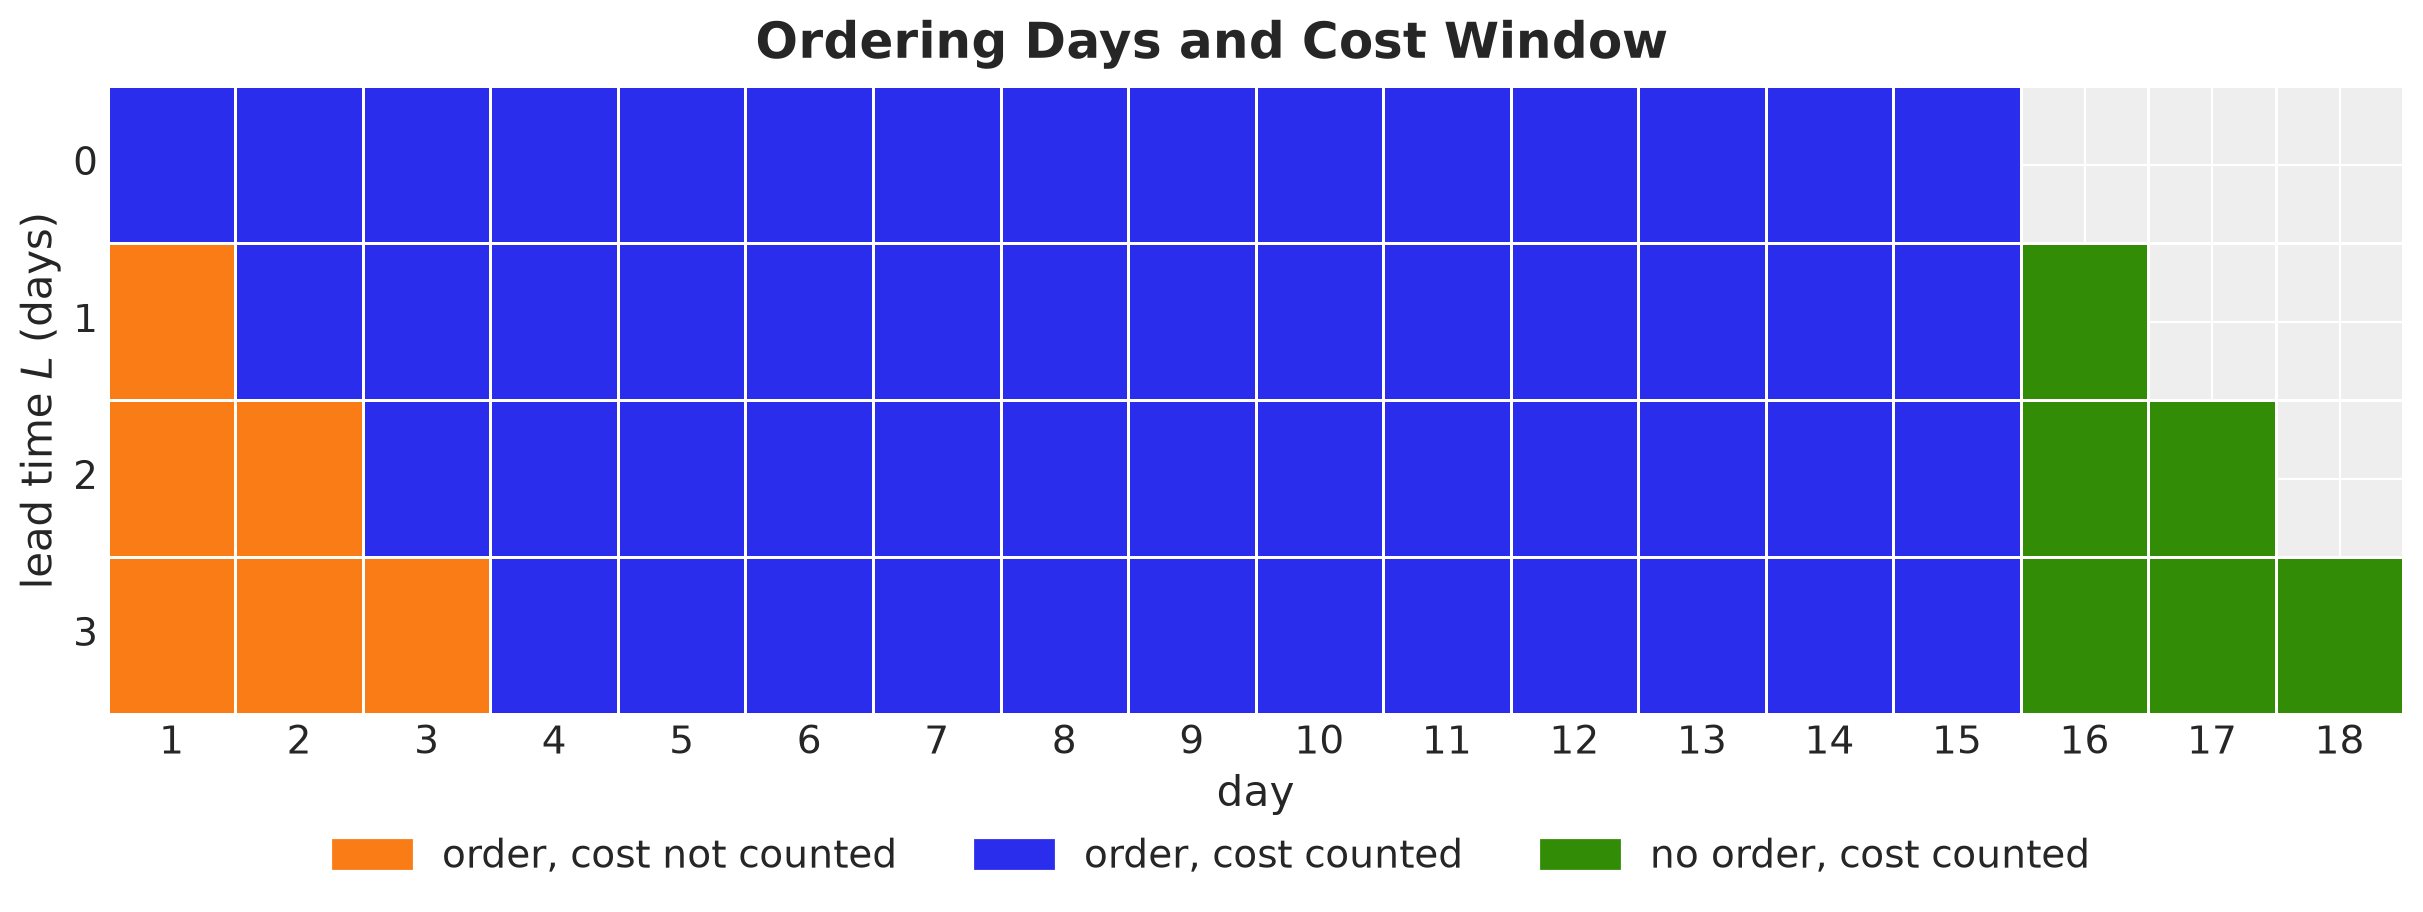

In [4]:
horizon_days = jnp.arange(1, setup.max_days + 1)
lead_times = jnp.asarray(setup.lead_times)[:, None]
is_ordering_day = jnp.broadcast_to(
    horizon_days <= setup.horizon, (lead_times.shape[0], setup.max_days)
)
is_cost_day = (horizon_days > lead_times) & (horizon_days <= setup.horizon + lead_times)
DAY_KINDS = {
    "order, cost not counted": is_ordering_day & ~is_cost_day,
    "order, cost counted": is_ordering_day & is_cost_day,
    "no order, cost counted": ~is_ordering_day & is_cost_day,
}
# one code per kind of day, and the days that we do not simulate stay empty
day_kind = jnp.select(
    list(DAY_KINDS.values()),
    [float(code) for code in range(len(DAY_KINDS))],
    default=jnp.nan,
)

kind_colors = ["C1", "C0", "C2"]

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(
    day_kind,
    cmap=kind_colors,
    cbar=False,
    linewidths=1,
    linecolor="white",
    xticklabels=horizon_days.tolist(),
    yticklabels=setup.lead_times,
    ax=ax,
)
ax.tick_params(axis="y", rotation=0)
ax.set(xlabel="day", ylabel="lead time $L$ (days)")
fig.legend(
    handles=[
        Patch(color=color, label=label)
        for color, label in zip(kind_colors, DAY_KINDS, strict=True)
    ],
    loc="outside lower center",
    ncol=3,
)
fig.suptitle("Ordering Days and Cost Window", fontsize=18, fontweight="bold");

Every row has $15$ ordering days and $15$ days in the cost window, and the cost window starts $L$ days after the first order. The empty cells are days that we do not simulate. The cost window moves with the lead time, so it covers different days for different lead times. For this reason we compare the policies within a lead time, and we do not compare the loss of one policy across lead times.

Now that we know when an order arrives and which days we pay for, let's define the policies that place the orders.

## Policies

On day $t$ a policy sees the **observation** $o_t$, which collects what we know when we order:

- **Day.** The day $t$ of the horizon.
- **Stock available.** The units on the shelf after the arrival of step $1$, $y_t$.
- **Pipeline.** Each order that is still on its way.
- **Recent demand.** The demand of the last $K$ days. We fix the window of the recent demand at $K = 7$ days since we assume one forecast update per week.
- **Forecast.** The latest forecast of the demand of the next days.

A **policy** is a function $\pi_\theta$ that maps the observation to the order of the day,

$$
a_t = \pi_\theta(o_t),
$$

where $\theta$ collects the parameters of the policy (not of the demand model). The observation contains only what we know when we order. In particular, it does not contain the demand $D_t$ of the day or of any later day.

The loss now depends on the policy and on the demand path $D = (D_1, \dots, D_{H+L})$, so we write it as $C(\theta, D)$. As in the first post, we estimate its expected value with scenarios. Let $D^{(1)}, \dots, D^{(N)}$ be $N$ **scenarios**, joint draws of the demand path from the forecast. The **expected loss** of a policy is

$$
J(\theta) = \text{E}[C(\theta, D)] \approx \frac{1}{N} \sum_{n=1}^{N} C(\theta, D^{(n)}).
$$

**Training** a policy means looking for the parameters $\theta$ with the lowest expected loss. Training leaves the demand model and the forecast as they are. It fits the parameters of the policy to the scenarios of the forecast, with the simulated loss in place of a likelihood. A common training method is gradient descent, the one we used in the first post.

We do not want a policy to overfit its training scenarios. For this reason we score every policy on test scenarios that the training does not use. The neural policy has the most parameters, so among the parameters that its training visits we keep the ones with the lowest loss on a separate validation set.

Now that we have the notation in place, let's define the five policies that we want to compare.

### Fixed Plan

The first policy is `Fixed plan`. It sets all the $H$ orders on day one, and they cannot change afterwards. As a policy, it reads only the day from the observation, so the order of day $t$ is one number,

$$
\pi_\theta(o_t) = \theta_t, \qquad \theta_t \geq 0,
$$

and the parameters are the $H$ orders. For $L = 0$ this is the expected cost plan of the first post.

The plan is our baseline because it shows what the forecast of day one gives when the orders do not react to the stock or to the demand. Training chooses its $H$ orders once, from the scenarios of the forecast. After that the plan places these orders whatever happens: day $5$ gets the same order after four strong days as after four slow ones. So the shelf runs empty when the demand is higher than the forecast expected, and the stock piles up when it is lower.

### Base-Stock (Day-One Forecast)

The second policy is `Base-stock (day-one forecast)`. It looks at the stock every day and orders up to a target level that comes from the forecast of day one. We define the level first and then work an example.

#### Target Level

A base-stock policy answers one question on every day: how much stock, on the shelf and on its way, do we want to have after the order of today? This number is the **target level** of the day, and the policy orders the difference between the level and the inventory position. If the position is already above the level, it orders nothing.

The quality of a base-stock policy depends on its levels. To choose them, recall the newsvendor problem of the first post. For a single day, the stock that minimizes the expected cost is the $p / (p + h)$ quantile of the demand. The ratio $p / (p + h)$ is the **critical fractile**, $0.952$ for our costs. The quantile is high because a lost sale costs $20$ times as much as a unit left over.

With a lead time the level has to cover more than one day. Recall from the *Lead Time* section that the order of day $t + 1$ arrives after day $t + L$. So the inventory position after the order of day $t$ is the only stock that can serve the demand of the $L + 1$ days $t, \dots, t + L$, and the level of day $t$ has to cover the total demand of these days.

Let the **newsvendor level** $\hat{q}_t$ be the $p / (p + h)$ quantile of the total demand $D_t + \dots + D_{t+L}$ under a forecast. `Base-stock (day-one forecast)` orders up to the newsvendor level of the forecast of day one,

$$
\pi(o_t) = (\hat{q}_t - \text{IP}_t)^{+}.
$$

It has no parameters, so it needs no training.

How does this policy react to the demand? The inventory position of day $t$ is the position after the order of the day before, minus what we sold on that day,

$$
\text{IP}_t = \text{IP}_{t-1} + a_{t-1} - (D_{t-1} - U_{t-1}).
$$

If the order of the day before reached its level, $\text{IP}_{t-1} + a_{t-1} = \hat{q}_{t-1}$, the order of day $t$ is

$$
a_t = \left( (D_{t-1} - U_{t-1}) + (\hat{q}_t - \hat{q}_{t-1}) \right)^{+}.
$$

In other words, the policy orders what we sold the day before, plus the change of the level from one day to the next.

#### Worked Example

Let's work a simple example with made-up numbers. We take $L = 2$, so an order has to cover three days. As the forecast of the total demand of these three days we take a Gamma distribution with a mean of $160$ units and a standard deviation of $23$ units. The next figure shows its density and its newsvendor level.

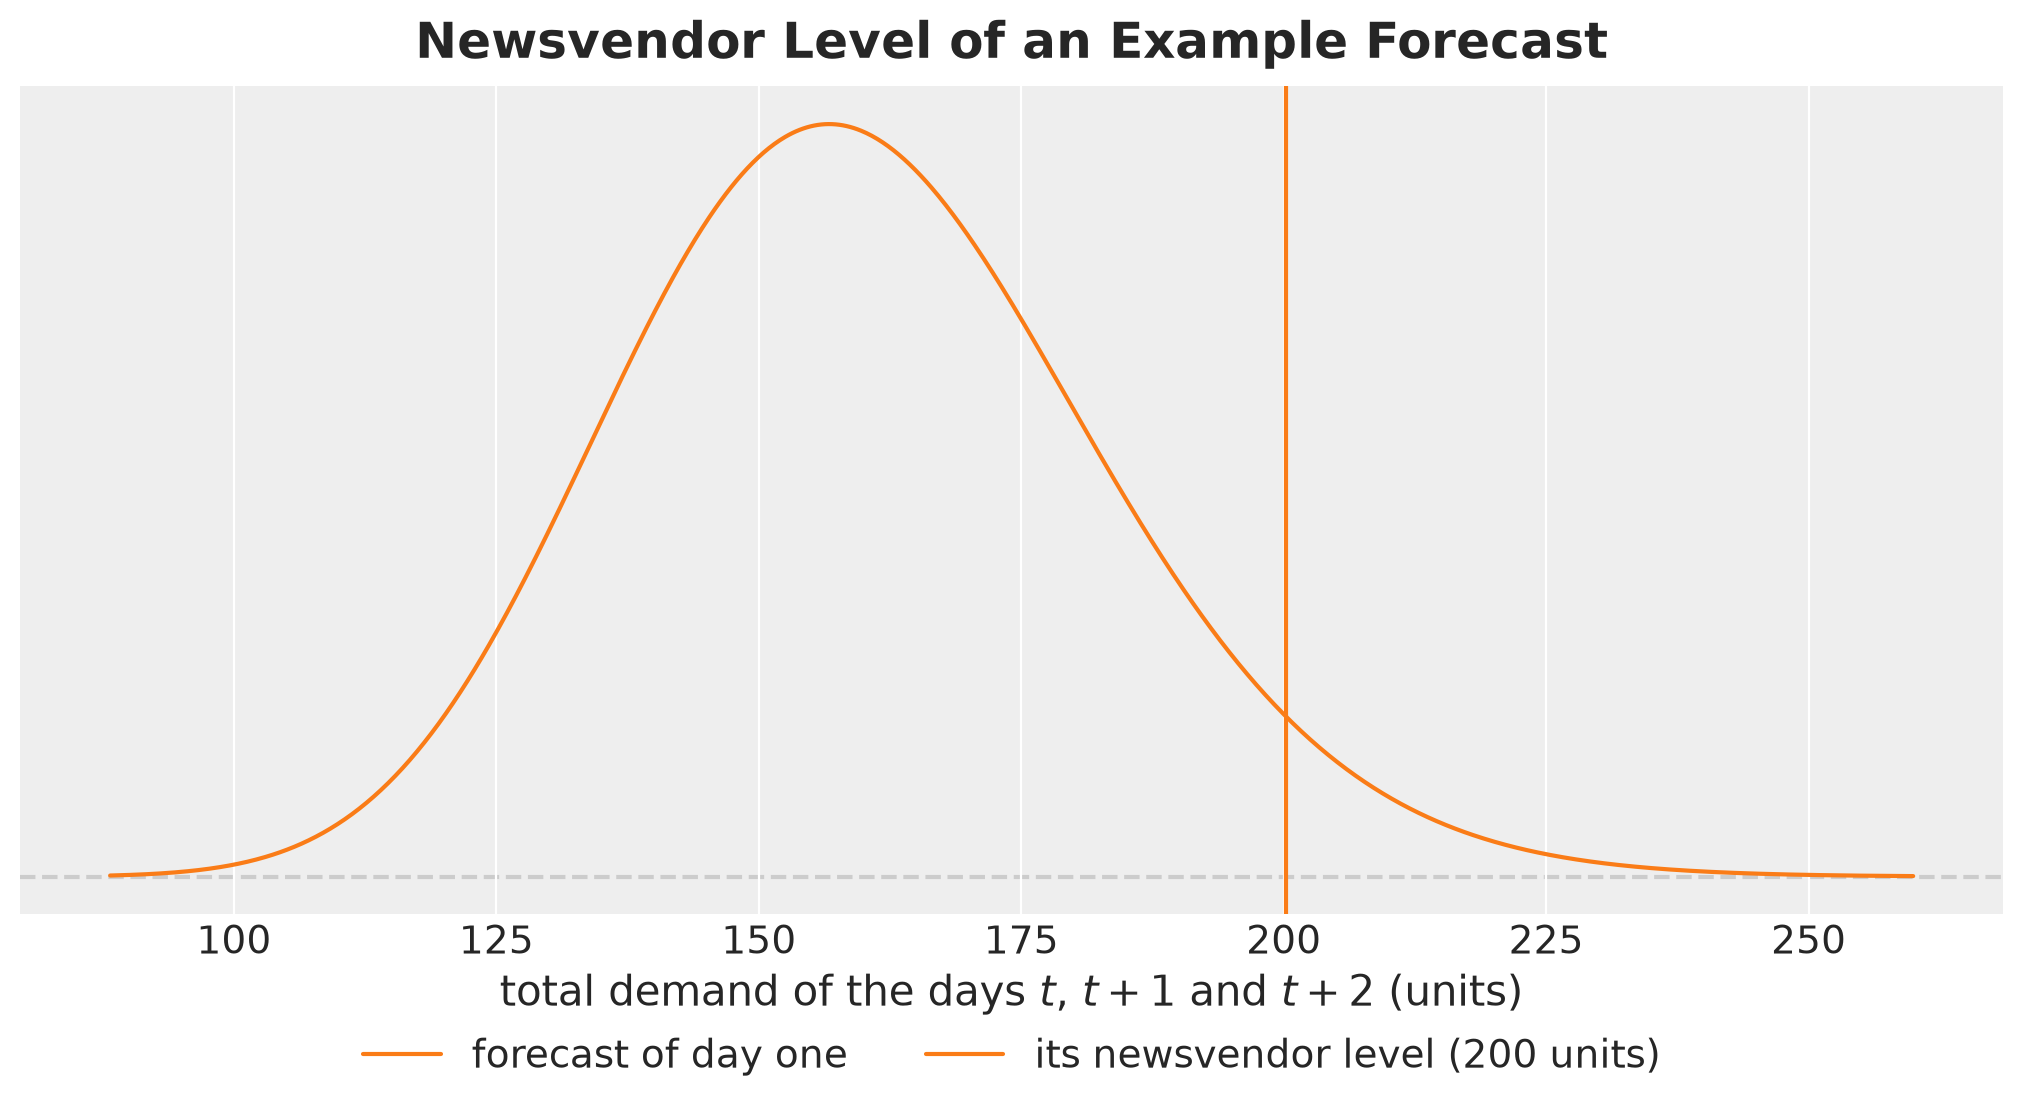

In [5]:
class PolicyName(StrEnum):
    """Names of the ways of placing the orders."""

    FIXED_PLAN = "Fixed plan"
    DAY_ONE = "Base-stock (day-one forecast)"
    DAY_ONE_TRAINED = "Base-stock (day-one forecast, trained)"
    WEEKLY_TRAINED = "Base-stock (weekly forecast, trained)"
    NEURAL = "Neural"


# one color per policy in every figure that follows
POLICY_COLORS = {
    PolicyName.FIXED_PLAN: "C0",
    PolicyName.DAY_ONE: "C1",
    PolicyName.DAY_ONE_TRAINED: "C2",
    PolicyName.WEEKLY_TRAINED: "C3",
    PolicyName.NEURAL: "C4",
}


def critical_fractile(config: InventoryConfig) -> float:
    """The quantile of the newsvendor problem, p / (p + h)."""
    return config.lost_sales_cost / (config.lost_sales_cost + config.holding_cost)


class ExampleForecast(NamedTuple):
    """A made-up forecast of the total demand of the days that an order covers."""

    label: str
    total_demand: pz.distributions.distributions.Continuous
    color: str
    linestyle: str = "-"

    def newsvendor_level(self, config: InventoryConfig) -> float:
        """The p / (p + h) quantile of the total demand, for the costs of `config`."""
        return float(self.total_demand.ppf(critical_fractile(config)))


def plot_levels(examples: list[ExampleForecast], config: InventoryConfig) -> plt.Figure:
    """Densities of made-up forecasts and the newsvendor level of each one."""
    fig, ax = plt.subplots(figsize=(10, 5.5))

    for example in examples:
        example.total_demand.plot_pdf(ax=ax, legend=None, color=example.color)
        ax.get_lines()[-1].set(label=example.label, linestyle=example.linestyle)

    for example in examples:
        level = example.newsvendor_level(config)
        ax.axvline(
            level,
            color=example.color,
            linestyle=example.linestyle,
            label=f"its newsvendor level ({level:,.0f} units)",
        )

    ax.set(xlabel="total demand of the days $t$, $t + 1$ and $t + 2$ (units)")
    fig.legend(loc="outside lower center", ncol=2)
    return fig


day_one_example = ExampleForecast(
    "forecast of day one",
    pz.Gamma(mu=160, sigma=23),
    POLICY_COLORS[PolicyName.DAY_ONE],
)
fig = plot_levels([day_one_example], config)
fig.suptitle("Newsvendor Level of an Example Forecast", fontsize=18, fontweight="bold");

The newsvendor level is $200$ units. The critical fractile leaves a share $1 - p / (p + h) = h / (p + h) = 0.1 / 2.1 \approx 4.8\%$ of the probability above the level. So under this forecast the demand of the three days is above the level with a probability of $4.8\%$.

Now we look at one ordering day in two cases, one after slow sales and one after strong sales. In both cases an order of $60$ units is on its way and arrives tomorrow. After slow sales the shelf holds $105$ units, the arrival of this morning included, and after strong sales it holds $60$ units. The next figure shows the order of `Base-stock (day-one forecast)` in each case, next to a fixed plan that chose an order of $55$ units for this day on day one.

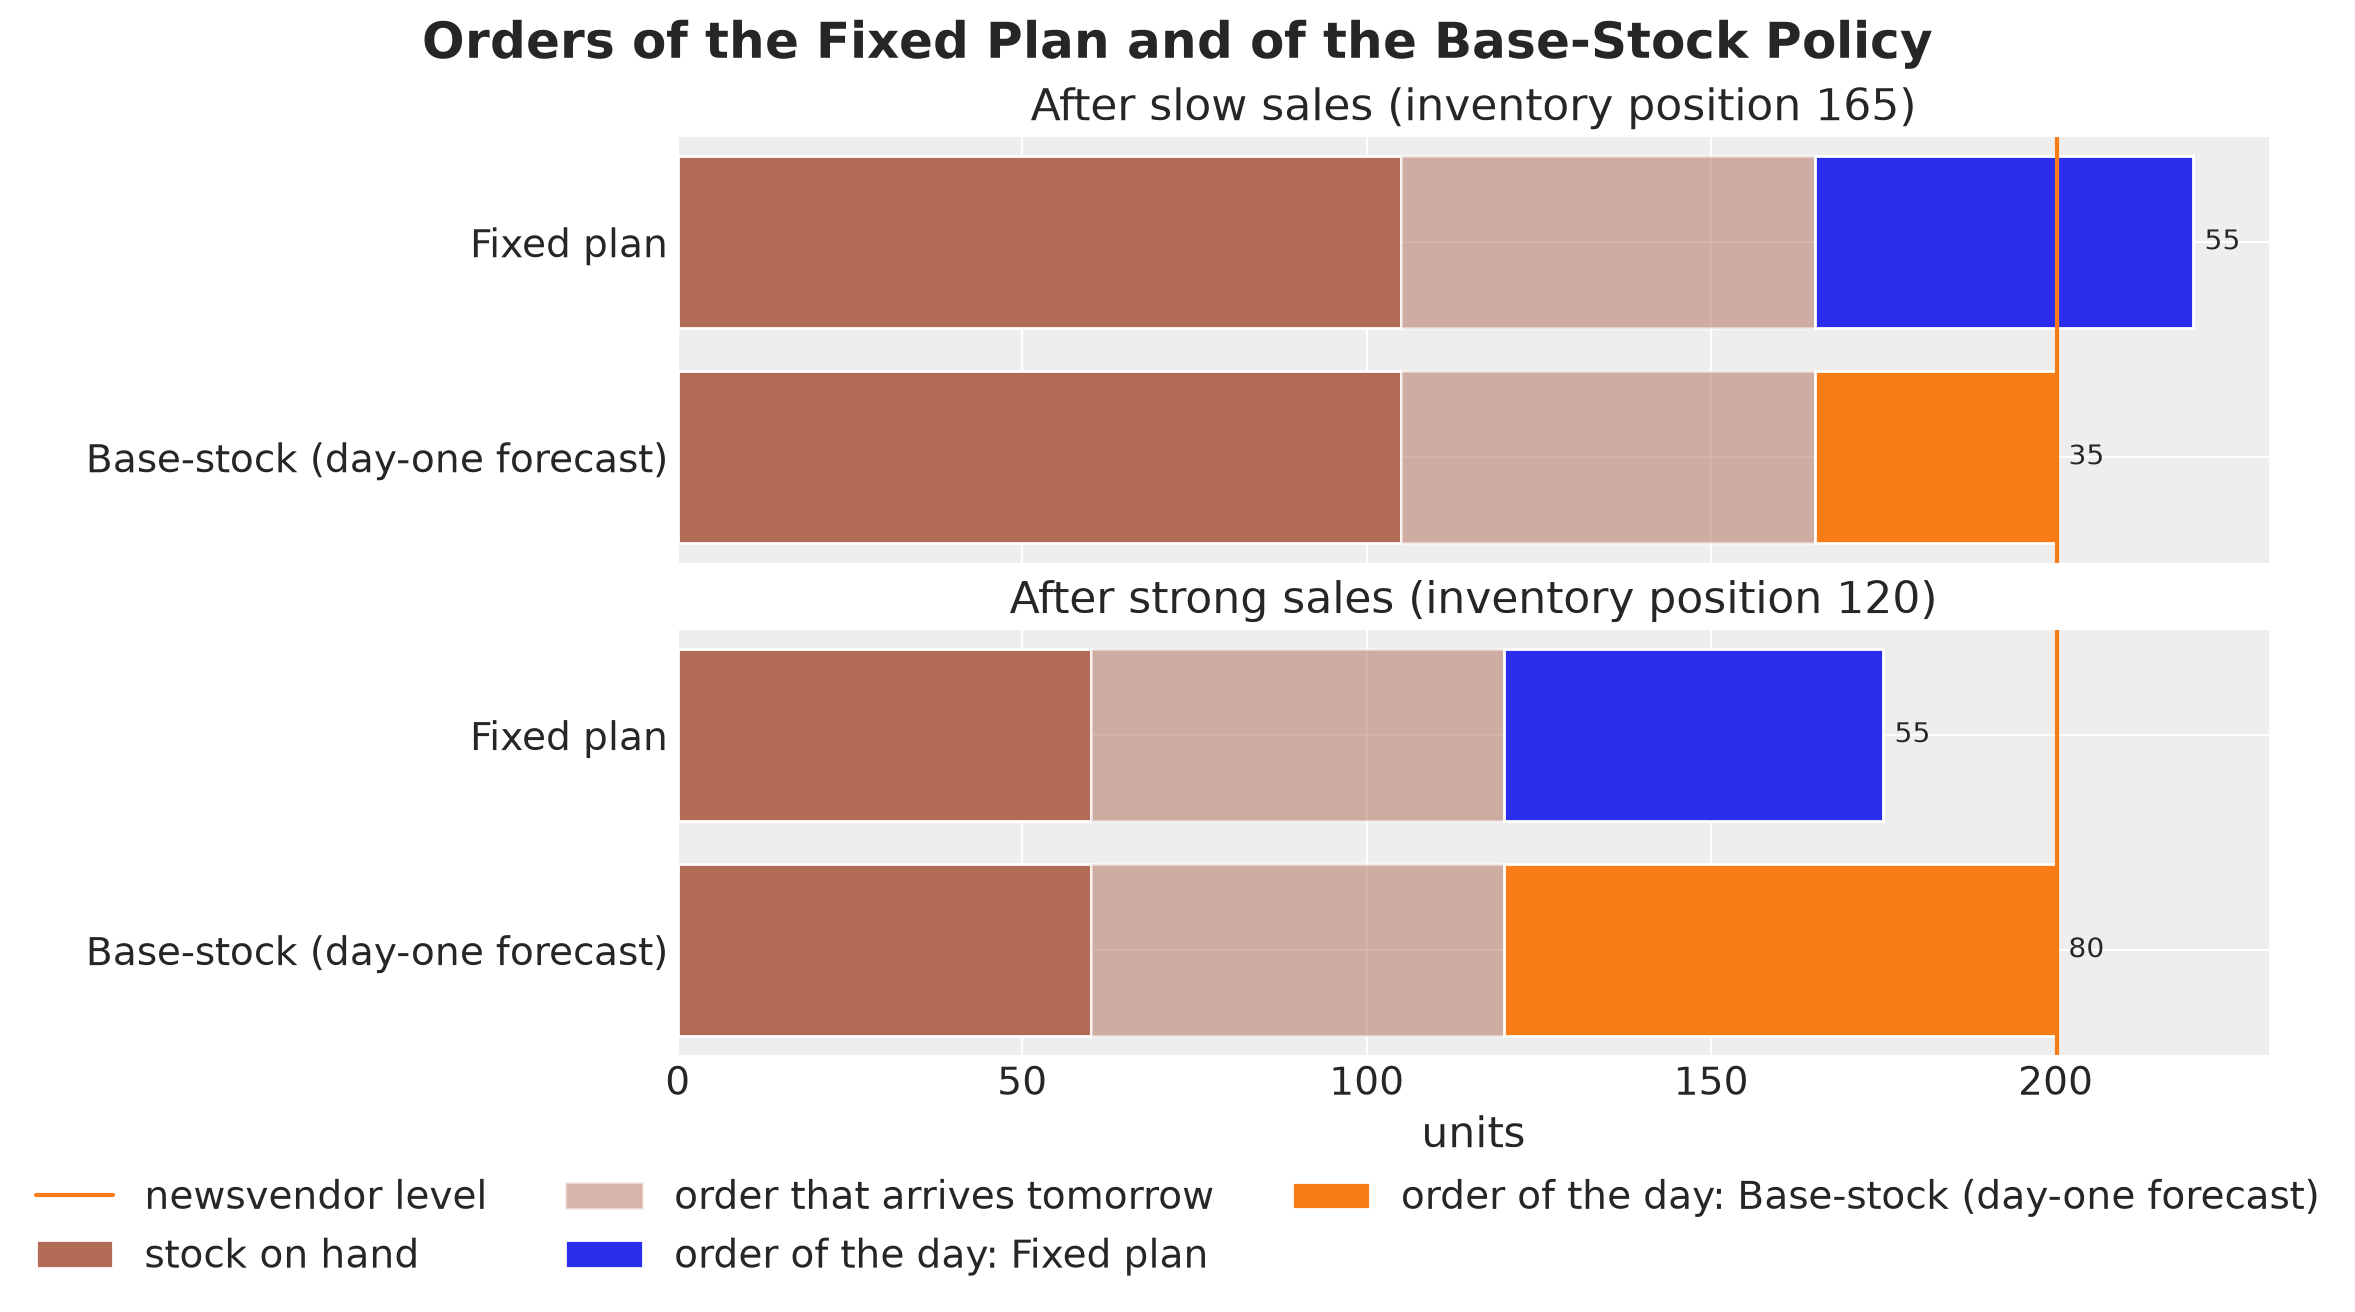

In [6]:
class ExampleDay(NamedTuple):
    """Stock on a made-up ordering day with a lead time of two days."""

    title: str
    on_hand: float  # after the arrival of the day
    on_the_way: float  # the order that arrives tomorrow

    @property
    def position(self) -> float:
        """Inventory position: the stock on hand plus the order on its way."""
        return self.on_hand + self.on_the_way


def plot_orders(ax: plt.Axes, day: ExampleDay, orders: dict[PolicyName, float]) -> None:
    """Stacked bars of the stock of a day and the order of each policy."""
    stock = {
        "stock on hand": (day.on_hand, 1.0),
        "order that arrives tomorrow": (day.on_the_way, 0.5),
    }

    for row, (name, order) in enumerate(orders.items()):
        left = 0.0

        for label, (units, alpha) in stock.items():
            ax.barh(
                row,
                units,
                left=left,
                color="C9",
                alpha=alpha,
                edgecolor="white",
                label=label if row == 0 else None,
            )
            left += units

        bars = ax.barh(
            row,
            order,
            left=left,
            color=POLICY_COLORS[name],
            edgecolor="white",
            label=f"order of the day: {name}",
        )
        ax.bar_label(bars, fmt="{:,.0f}", padding=4)

    ax.set(
        title=f"{day.title} (inventory position {day.position:,.0f})",
        yticks=range(len(orders)),
        yticklabels=list(orders),
    )
    ax.invert_yaxis()


PLAN_ORDER_EXAMPLE = 55.0  # the order of this day that the plan chose on day one
example_days = [
    ExampleDay("After slow sales", on_hand=105.0, on_the_way=60.0),
    ExampleDay("After strong sales", on_hand=60.0, on_the_way=60.0),
]
level_example = day_one_example.newsvendor_level(config)
example_orders = {
    day.title: {
        PolicyName.FIXED_PLAN: PLAN_ORDER_EXAMPLE,
        PolicyName.DAY_ONE: max(level_example - day.position, 0.0),
    }
    for day in example_days
}

fig, axes = plt.subplots(nrows=2, figsize=(11, 6.5), sharex=True, layout="constrained")

for ax, day in zip(axes, example_days, strict=True):
    plot_orders(ax, day, example_orders[day.title])
    ax.axvline(
        level_example,
        color=POLICY_COLORS[PolicyName.DAY_ONE],
        label="newsvendor level",
    )

axes[-1].set(xlabel="units")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle(
    "Orders of the Fixed Plan and of the Base-Stock Policy",
    fontsize=18,
    fontweight="bold",
);

The base-stock policy fills the gap to the level. It orders $35$ units after slow sales and $80$ units after strong sales, and in both cases it ends at the level of $200$ units. The plan places the same order of $55$ units in both cases, so it ends above the level after slow sales and below it after strong sales.

### Base-Stock (Day-One Forecast, Trained)

The third policy is `Base-stock (day-one forecast, trained)`. It is the base-stock policy above with one more number per day, a trained correction of the newsvendor level. It answers the following question: is the newsvendor level the best target level when a sale that we cannot serve is lost and an order takes $L$ days to arrive?

We answer in three steps. First, we follow the example for three days and see that a lost sale leaves more stock than the newsvendor level assumes. Next, we define the correction and say what it can fix and what it cannot. Finally, we recall what the literature says about its size.

#### Stock After Lost Sales

Let's follow the two cases of the example after the order of `Base-stock (day-one forecast)`. In both cases the inventory position after the order is the level of $200$ units. We let the three covered days, $t$, $t + 1$ and $t + 2$, have a demand of $80$, $70$ and $60$ units. Their total of $210$ units is above the level, which happens with probability $h / (p + h) = 4.8\%$ under the forecast. The next figure shows the stock available and the demand on each of the three days, for both cases.

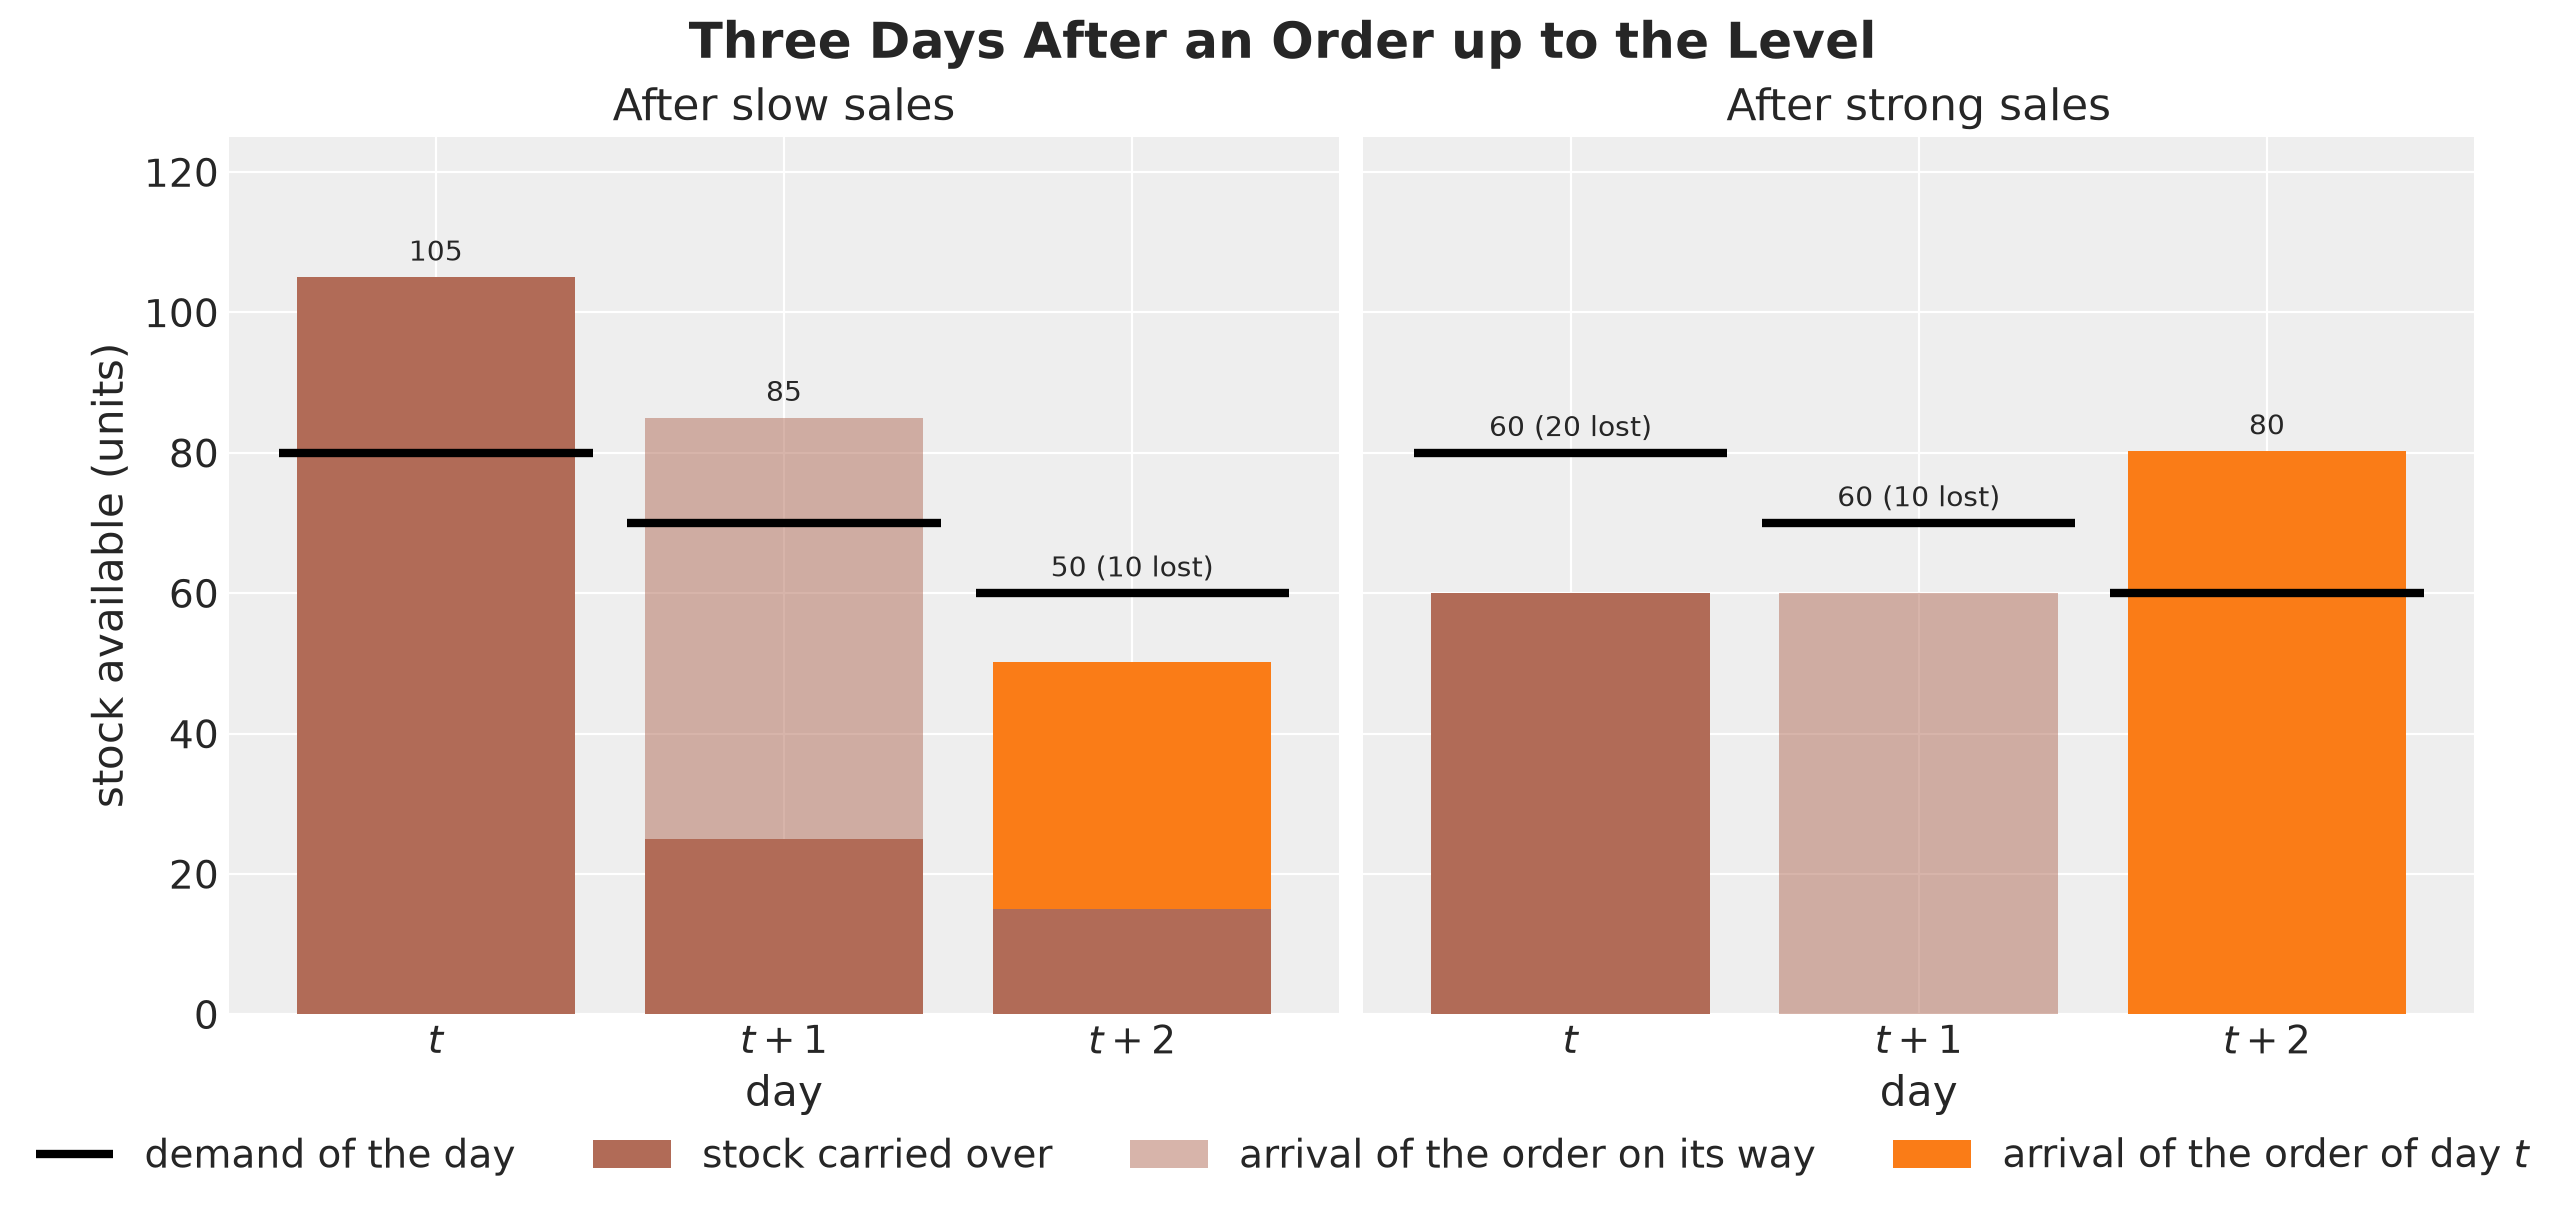

In [7]:
DEMAND_EXAMPLE = (80.0, 70.0, 60.0)  # demand of the days t, t + 1 and t + 2
DAY_LABELS = ("$t$", "$t + 1$", "$t + 2$")


class ExampleStep(NamedTuple):
    """One day after an order: stock carried over, arrival and lost sales."""

    carried: float
    arrival: float
    lost_sales: float


def follow_order(day: ExampleDay, order: float) -> list[ExampleStep]:
    """The days t, t + 1 and t + 2 after the order of day t, with lost sales."""
    carried, steps = day.on_hand, []
    # the stock on hand of day t already contains the arrival of that day
    arrivals = (0.0, day.on_the_way, order)

    for arrival, demand in zip(arrivals, DEMAND_EXAMPLE, strict=True):
        available = carried + arrival
        steps.append(ExampleStep(carried, arrival, max(demand - available, 0.0)))
        carried = max(available - demand, 0.0)

    return steps


def plot_stock(ax: plt.Axes, steps: list[ExampleStep]) -> None:
    """Stacked bars of the stock available on each day, next to its demand."""
    arrival_styles = [
        ("C9", 0.5, None),
        ("C9", 0.5, "arrival of the order on its way"),
        (POLICY_COLORS[PolicyName.DAY_ONE], 1.0, "arrival of the order of day $t$"),
    ]

    for x, (step, (color, alpha, label)) in enumerate(
        zip(steps, arrival_styles, strict=True)
    ):
        ax.bar(
            x, step.carried, color="C9", label="stock carried over" if x == 0 else None
        )
        ax.bar(
            x, step.arrival, bottom=step.carried, color=color, alpha=alpha, label=label
        )
        ax.annotate(
            f"{step.carried + step.arrival:,.0f}"
            + (f" ({step.lost_sales:,.0f} lost)" if step.lost_sales > 0 else ""),
            (x, max(step.carried + step.arrival, DEMAND_EXAMPLE[x])),
            textcoords="offset points",
            xytext=(0, 6),
            ha="center",
        )

    ax.hlines(
        DEMAND_EXAMPLE,
        [x - 0.45 for x in range(len(DEMAND_EXAMPLE))],
        [x + 0.45 for x in range(len(DEMAND_EXAMPLE))],
        color="black",
        linewidth=3,
        label="demand of the day",
    )
    ax.set(xlabel="day", xticks=range(len(DAY_LABELS)), xticklabels=DAY_LABELS)


fig, axes = plt.subplots(
    ncols=2, figsize=(12, 6), sharex=True, sharey=True, layout="constrained"
)

for ax, day in zip(axes, example_days, strict=True):
    plot_stock(ax, follow_order(day, example_orders[day.title][PolicyName.DAY_ONE]))
    ax.set(title=day.title)

# room for the labels above the bars
axes[0].set(ylabel="stock available (units)", ylim=(0, 125))
fig.legend(*axes[1].get_legend_handles_labels(), loc="outside lower center", ncol=4)
fig.suptitle(
    "Three Days After an Order up to the Level", fontsize=18, fontweight="bold"
);

The number above each day is the stock available on that day. Both cases start from the same position of $200$ units after the order, and they end differently:

- **After slow sales.** The shelf serves the first two days, so we sell the whole demand of $80 + 70 = 150$ units of days $t$ and $t + 1$. On day $t + 2$ we have $200 - 150 = 50$ units for a demand of $60$ units, and we lose $10$ units. This is the case that the newsvendor level counts on, because it subtracts the whole demand of the first two days from the position.
- **After strong sales.** The shelf runs out on day $t$ and again on day $t + 1$. We sell only $60 + 60 = 120$ units on these two days, and we lose the other $30$ units of demand. So on day $t + 2$ we have $200 - 120 = 80$ units, which is $30$ units more than the $50$ units that the level counts on.

So a sale that we lose takes no stock away. The orders on their way arrive in full, and the $30$ units that the lost demand did not take are still on the shelf on day $t + 2$.

We can write this for any lead time. After the order the inventory position is at least the level, $\text{IP}_t + a_t \geq \hat{q}_t$, with equality when the order is positive. All of this stock has arrived by day $t + L$, and no later order has. What we sell on a day $s$ is $D_s - U_s$, the demand minus the lost sales. So for a positive order the stock available on day $t + L$ is

$$
y_{t+L} = \hat{q}_t - \sum_{s=t}^{t+L-1} (D_s - U_s).
$$

The newsvendor level counts the whole demand of the days before $t + L$ against the stock, and every sale that we lose on those days leaves one more unit for day $t + L$. For $L = 0$ the sum is empty and nothing is left out. So with a lead time the policy has at least as much stock on day $t + L$ as its level assumes, and a lower level can be cheaper.

#### Offset Definition

There is no simple formula for the best level, so we look for it with the simulator. `Base-stock (day-one forecast, trained)` adds an **offset** $\theta_t$ to the newsvendor level of every ordering day,

$$
\pi_\theta(o_t) = (\hat{q}_t + \theta_t - \text{IP}_t)^{+}.
$$

The parameters are the $H$ offsets, and the training starts them at zero, that is, at the newsvendor level. The day-one levels are the same in every scenario, so this policy has one free level per day.

Here is an important observation. The offsets do not repair the forecast. We train them on scenarios drawn from the forecast that gives the levels, so the levels are the right quantiles of these scenarios. The offsets correct the rule that turns a quantile into an order. We check this in the *Base-Stock Training* section: the demand is above the level about as often as the forecast says, at every lead time, and with a lead time the policy still runs out less often.

For the same reason the offsets cannot see where the forecast is wrong. They move the levels in one direction, which helps when the true demand lies on that side of the forecast and costs when it lies on the other. We see both cases in the *Gain by Expected Demand* section.

#### Evidence From the Literature

The question of whether the newsvendor level is the best level under lost sales is a classical one. [Huh et al. (2009)](https://www.columbia.edu/~th2113/files/MS_LostSales_Asymptotic_09.pdf) recall the answer for a demand that is independent from day to day with the same distribution. When the customers wait for the next delivery, at a cost per unit and day of waiting, a base-stock policy is optimal and its best level is the newsvendor level. When the sale is lost and the lead time is positive, a base-stock policy is no longer optimal.

[Zipkin (2008)](https://ideas.repec.org/a/inm/oropre/v56y2008i5p1256-1263.html) tests several rules on this problem and reports in the abstract:

> We find that several perform reasonably well, although none is perfect. However, the standard base-stock policy (a direct analogue of the optimal policy for a backlog system) performs badly.

Note that the base-stock policy of Zipkin already has the best level, so his verdict is about the rule and not about the level, and it is relative to the other rules of his test. Huh et al. (2009) compute how far this policy is from the optimal one, and we use their numbers below. For more details, see the review of [Bijvank and Vis (2011)](https://research.rug.nl/en/publications/lost-sales-inventory-theory-a-review).

The size of the correction depends on the cost ratio $p / h$. Huh et al. (2009) show, for a large class of demand distributions, that when the ratio grows the cost of the best base-stock policy approaches the cost of the optimal policy. The same holds for the base-stock policy with the newsvendor level of the larger margin $p + L h$. Their experiments use a stationary demand, ratios from $1$ to $199$ and lead times of $1$ to $4$ periods. For a ratio of $19$, the closest to our $p / h = 20$, and lead times of $1$ to $3$ periods, their Tables $2$ and $3$ show the following:

- **Newsvendor level against the best level.** Their newsvendor level uses the margin $p + L h$, so it is at least as high as the $p / (p + h)$ quantile that we use. The base-stock policy with this level costs $2.1\%$ to $12.7\%$ more than the one with the best level, and the difference grows with the lead time.
- **Best level against the optimal policy.** The base-stock policy with the best level costs $0.7\%$ to $3.0\%$ more than the optimal policy.
- **Direction.** The best level is below their newsvendor level in every case, and their Theorem $4$ shows that it is never above it.

Our ratio is in the middle of their range, well below the ratio of at least $100$ of their retail example. For a problem like theirs we would expect the newsvendor level to leave a gap that the training can close, and little room above a base-stock policy with the best levels. We compare these numbers with ours in the *Paired Differences* and *Cost Ratio* sections.

### Base-Stock (Weekly Forecast, Trained)

The fourth policy is `Base-stock (weekly forecast, trained)`. The levels of the forecast of day one are fixed before the horizon starts: the level of day $10$ is one number, whatever the first week shows. But the forecast is uncertain about how high the demand currently is, and the first week tells us about it.

This policy takes its levels from the **weekly forecast**: the forecast of day one up to day $7$, and from day $8$ on the forecast updated with the demand of the first week. The rule is the same,

$$
\pi_\theta(o_t) = (\hat{q}_t + \theta_t - \text{IP}_t)^{+},
$$

where $\hat{q}_t$ is now the newsvendor level of the weekly forecast in the observation, and the policy has its own $H$ offsets.

We update once per week, as a retailer that runs its forecast every week does. With $15$ ordering days the updates fall on days $8$ and $15$, and we keep only the first one, since the second would change only the last order. A daily update would give the policy more recent forecasts, and we come back to it in the *Model Limitations* section.

Let's go back to the example and suppose that its three days come after the update. The next figure shows the forecast of day one next to two weekly forecasts of the same three days, one after a slow first week and one after a strong first week, each with its newsvendor level. We made up the sizes of the changes. Relative to the level, they are close to the largest changes of the *Weekly Forecast* section, at the edges of its $94\%$ interval. For half of the paths the level moves less than half as much.

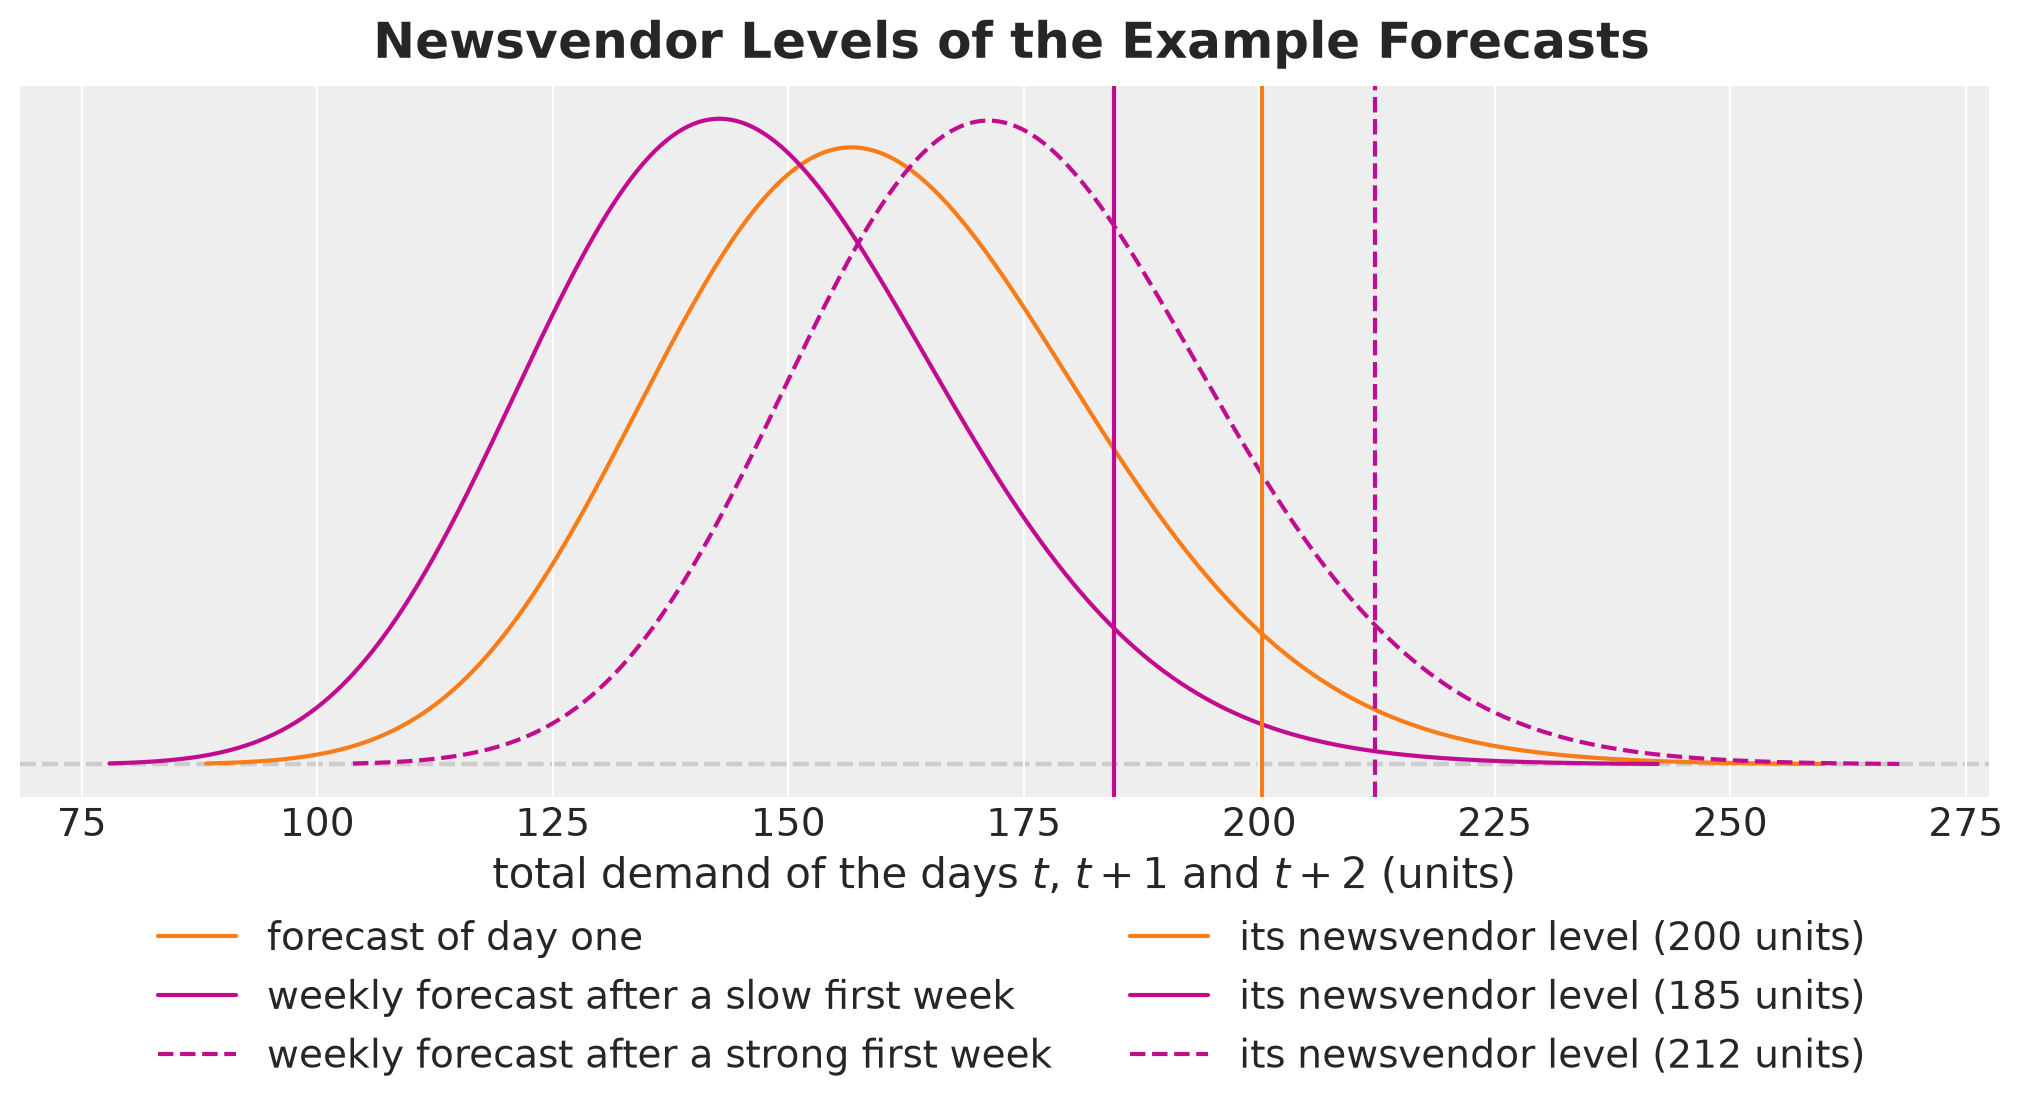

In [8]:
weekly_examples = [
    ExampleForecast(
        "weekly forecast after a slow first week",
        pz.Gamma(mu=146, sigma=22),
        POLICY_COLORS[PolicyName.WEEKLY_TRAINED],
    ),
    ExampleForecast(
        "weekly forecast after a strong first week",
        pz.Gamma(mu=174, sigma=22),
        POLICY_COLORS[PolicyName.WEEKLY_TRAINED],
        linestyle="--",
    ),
]
fig = plot_levels([day_one_example, *weekly_examples], config)
fig.suptitle(
    "Newsvendor Levels of the Example Forecasts", fontsize=18, fontweight="bold"
);

After a slow first week the weekly forecast moves down and its level is $185$ units. After a strong first week it moves up and its level is $212$ units. The weekly forecast gives every demand path its own level, while the forecast of day one has one level of $200$ units for all of them.

Note that the weekly forecast comes after the offsets in our list. The updated forecast has seen one more week of demand, so it is less uncertain about the level, which can lower its high quantile. With lost sales the newsvendor levels can be too high, so a comparison of the two forecasts without offsets would also credit the update for this lower level. With trained offsets on both sides, the difference between the two policies is the gain of levels that use the demand of the first week. Our update is an approximation, which we build in the *Forecast Updates* section, so the offsets of this policy can also absorb part of its error.

### Neural

The fifth policy is `Neural`. It starts from two limits of a base-stock policy that no level removes:

- **One number for the stock.** The policy sees the stock on hand and the pipeline only through their sum. The two cases of the example of the *Stock After Lost Sales* section have the same inventory position after the order, and their stock differs by $30$ units on the day on which the order arrives. One offset per day cannot tell them apart.
- **No recent demand.** Between two forecast updates the levels do not use the latest sales. On day $14$ the weekly forecast is $6$ days old.

A neural network can read the whole observation. Recall from the first post that the product has price promotions, which the retailer plans in advance. The network also reads which of the days that the order covers are promotion days. `Neural` adds the output of a network $g_\theta$ to the level of `Base-stock (weekly forecast, trained)`,

$$
\pi_\theta(o_t) = (\hat{q}_t + \theta_t + \bar{d} \, g_\theta(o_t) - \text{IP}_t)^{+},
$$

where $\bar{d}$ is the mean daily demand of the history. The last layer of the network starts at zero, so the training starts at `Base-stock (weekly forecast, trained)`.

The factor $\bar{d}$ sets the scale. The stock, the forecast and the demand are tens to hundreds of units. We divide these inputs by $\bar{d}$ and multiply the output by $\bar{d}$, so that the network reads and returns numbers of order one, which is the usual practice for training a network. An output of $1$ moves the level by one day of mean demand. As a consequence, the policy does not depend on the unit in which we count the product.

The neural policy tells us how much a rule that reads the whole observation gains over the base-stock policy in our problem. The room for it grows with the lead time, since from $L = 2$ on one or more orders are still in the pipeline when we decide, and the network sees each of them. Still, we do not expect a large gain. Recall from the *Evidence From the Literature* section that in the stationary experiments of Huh et al. (2009), at a cost ratio like ours, the best base-stock policy is within a few percent of the optimal policy. Our demand is not stationary, so this is only a guide.

**Remark (Reinforcement Learning).** [Gijsbrechts et al. (2022)](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=3302881) train neural policies for this lost-sales problem with a model-free method of reinforcement learning (A3C), which estimates the gradient of the loss from the outcomes of sampled orders. We take the exact gradient through the simulator instead, and [Alvo et al. (2023)](https://arxiv.org/abs/2306.11246) report that this is more robust than variants of the REINFORCE algorithm. Three properties of our problem allow it:

- **Joint paths.** The forecast is a generative model, so it gives joint demand paths. A forecast that gives only a quantile per day does not.
- **Exogenous demand.** The demand does not depend on our orders, so we can replay a path under any policy.
- **Known dynamics.** The five steps of a day are a known and differentiable function of the order.

A model-free method only needs to try orders and see the cost, in a simulator or in the store. So it also applies when the orders come in whole pallets, or when we cannot write the dynamics down, for example when the demand reacts to our stockouts. Its drawback is a noisy estimate of the gradient.

The next table summarizes the five policies.

| Policy | Order of day $t$ | Reads | Parameters |
|---|---|---|---|
| `Fixed plan` | $\theta_t$ | the day | $H$ orders |
| `Base-stock (day-one forecast)` | $(\hat{q}_t - \text{IP}_t)^{+}$ | the day, the inventory position, the forecast of day one | none |
| `Base-stock (day-one forecast, trained)` | $(\hat{q}_t + \theta_t - \text{IP}_t)^{+}$ | the same as the policy above | $H$ offsets |
| `Base-stock (weekly forecast, trained)` | $(\hat{q}_t + \theta_t - \text{IP}_t)^{+}$ | the day, the inventory position, the weekly forecast | $H$ offsets |
| `Neural` | $(\hat{q}_t + \theta_t + \bar{d} \, g_\theta(o_t) - \text{IP}_t)^{+}$ | the whole observation and the promotion calendar | $H$ offsets and the weights of the network |

Now that we have the five policies, let's build the demand scenarios that all of them use.

## Demand Scenarios

### Demand Model

We use the data generating process and the forecasting model of the first post. The demand has a level that drifts as a random walk on the log scale, a weekly pattern, a price promotion with an elasticity, and negative binomial noise. A promotion cuts the price by $30\%$ for a week, and the second week of the horizon, days $8$ to $14$, is a promotion week. The first post explains the model, the prior elicitation with PreliZ and the diagnostics in its sections *Generate Data* to *Model Fitting*.

Here we write the model from small components, and we use the same model to generate the data, to fit it and to draw the demand scenarios. Let's start with the priors, which are the priors of the first post. We elicit three of them with PreliZ: `pz.maxent` returns the member of a family with the largest entropy among those with $94\%$ of their mass between two bounds. We state the other two directly.

- **`intercept`**: a Normal on the log of the demand per day at the start of the history at the list price, with $94\%$ of its mass between $\log 10$ and $\log 300$.
- **`drift_scale`**: a LogNormal on the standard deviation of the daily increments of the log level, with $94\%$ of its mass between $\log(1.04) / \sqrt{T}$ and $\log(2) / \sqrt{T}$, where $T = 364$ is the length of the history. So over one year the level moves by a factor between $1.04$ and $2$.
- **`concentration`**: a Gamma on the concentration $\phi$ of the negative binomial, with $94\%$ of its mass between $4$ and $100$. So the extra noise is between a tenth and a half of the level.
- **`beta`**: a $\text{Normal}(0, 0.3)$ for each Fourier coefficient of the weekly pattern.
- **`elasticity`**: a $\text{Normal}(-1, 1)$ for the price elasticity.

The model and the checks refer to the sample sites by name, so we keep the names in the `Site` class. Every model component gets its own small tuple of priors, and the `Priors` tuple collects them.

In [9]:
class Site:
    """Names of the sample sites of the demand model."""

    INTERCEPT: Final = "intercept"
    DRIFT_SCALE: Final = "drift_scale"
    DRIFT: Final = "drift"
    BETA: Final = "beta"
    ELASTICITY: Final = "elasticity"
    CONCENTRATION: Final = "concentration"
    # the expected demand of every day, a deterministic site
    MEAN: Final = "mean"
    # the demand, the site that `predict` registers
    OBS: Final = "obs"
    # the increments and the demand of the days after the history, the sites that
    # `innovations` and `predict` add when the covariates are longer than the data
    DRIFT_FUTURE: Final = "drift_future"
    FORECAST: Final = "forecast"
    # the global parameters of the model
    PARAMETERS: Final = (INTERCEPT, DRIFT_SCALE, BETA, ELASTICITY, CONCENTRATION)


class LevelPriors(NamedTuple):
    """Priors of the random walk level."""

    intercept: dist.Distribution
    drift_scale: dist.Distribution


class SeasonalityPriors(NamedTuple):
    """Prior of the weekly seasonality."""

    beta: dist.Distribution


class PricePriors(NamedTuple):
    """Prior of the price effect."""

    elasticity: dist.Distribution


class DispersionPriors(NamedTuple):
    """Prior of the dispersion of the likelihood."""

    concentration: dist.Distribution


class Priors(NamedTuple):
    """Priors of the demand model, one tuple per component."""

    level: LevelPriors
    seasonality: SeasonalityPriors
    price: PricePriors
    dispersion: DispersionPriors


intercept_bounds = (math.log(10), math.log(300))
drift_bounds = (
    math.log(1.04) / math.sqrt(setup.t_obs),
    math.log(2) / math.sqrt(setup.t_obs),
)
concentration_bounds = (4.0, 100.0)


def elicit(
    family: pz.distributions.distributions.Continuous,
    bounds: tuple[float, float],
    mass: float = 0.94,
) -> pz.distributions.distributions.Continuous:
    """Maximum entropy member of `family` with `mass` between the bounds."""
    return pz.maxent(family, *bounds, mass=mass, plot=False)


# the three elicited priors and the two that we state directly
intercept_prior = elicit(pz.Normal(), intercept_bounds)
drift_prior = elicit(pz.LogNormal(), drift_bounds)
concentration_prior = elicit(pz.Gamma(), concentration_bounds)
beta_prior = pz.Normal(0.0, 0.3)
elasticity_prior = pz.Normal(-1.0, 1.0)

priors = Priors(
    level=LevelPriors(
        intercept=dist.Normal(intercept_prior.mu, intercept_prior.sigma),
        drift_scale=dist.LogNormal(drift_prior.mu, drift_prior.sigma),
    ),
    seasonality=SeasonalityPriors(beta=dist.Normal(beta_prior.mu, beta_prior.sigma)),
    price=PricePriors(
        elasticity=dist.Normal(elasticity_prior.mu, elasticity_prior.sigma)
    ),
    dispersion=DispersionPriors(
        concentration=dist.Gamma(concentration_prior.alpha, concentration_prior.beta)
    ),
)

Next, we write the components of the model. Each component samples its own sites. The first three return a term of the log of the expected demand with shape `(days, 1)`, one column because we have one series, and the last one returns the concentration of the likelihood.

- `local_level`: the log level $\ell_t$, the initial level `intercept` plus the summed daily increments `drift`.
- `weekly_seasonality`: the Fourier term with the coefficients `beta`.
- `price_effect`: the `elasticity` times the log of the price relative to the list price.
- `dispersion`: the `concentration` of the negative binomial.

The function `make_demand_model` adds the three terms, records the expected demand of every day in the deterministic site `mean`, and registers the likelihood with `predict` of [`numpyro_forecast`](https://juanitorduz.github.io/numpyro_forecast/). The model has the signature `(covariates, data=None)` of `numpyro_forecast`. The covariates are the Fourier features of the weekly cycle and the log price of every day, so the model runs on any window of consecutive days.

In [10]:
def local_level(h: Horizon, priors: LevelPriors) -> Float[Array, "days 1"]:
    """Random walk level: the initial level plus the summed daily increments."""
    intercept = numpyro.sample(Site.INTERCEPT, priors.intercept)
    drift_scale = numpyro.sample(Site.DRIFT_SCALE, priors.drift_scale)
    drift = innovations(h, Site.DRIFT, dist.Normal(0.0, drift_scale))
    return intercept + jnp.cumsum(drift, axis=-2)


def weekly_seasonality(
    fourier: Float[Array, "days n_fourier"], priors: SeasonalityPriors
) -> Float[Array, "days 1"]:
    """Weekly Fourier seasonality."""
    beta = numpyro.sample(
        Site.BETA, priors.beta.expand([fourier.shape[-1]]).to_event(1)
    )
    return (fourier @ beta)[:, None]


def price_effect(
    log_price: Float[Array, " days"], priors: PricePriors
) -> Float[Array, "days 1"]:
    """Price elasticity times the log price relative to the list price."""
    elasticity = numpyro.sample(Site.ELASTICITY, priors.elasticity)
    return (elasticity * log_price)[:, None]


def dispersion(priors: DispersionPriors) -> Float[Array, ""]:
    """Concentration of the negative binomial."""
    return numpyro.sample(Site.CONCENTRATION, priors.concentration)


def make_demand_model(priors: Priors) -> ForecastModel:
    """Build the demand model as a plain `(covariates, data=None)` function."""

    def demand_model(
        covariates: Float[Array, "days features"],
        data: Int[Array, "t_obs 1"] | None = None,
    ) -> None:
        h = Horizon.from_data(covariates, data)
        # the Fourier features in the first columns and the log price in the last one
        fourier, log_price = covariates[:, :-1], covariates[:, -1]
        log_mean = (
            local_level(h, priors.level)
            + weekly_seasonality(fourier, priors.seasonality)
            + price_effect(log_price, priors.price)
        )
        concentration = dispersion(priors.dispersion)
        numpyro.deterministic(Site.MEAN, jnp.exp(log_mean))

        def likelihood(log_mean: Float[Array, "days 1"]) -> dist.Distribution:
            """Negative binomial with a log link."""
            return dist.NegativeBinomial2(jnp.exp(log_mean), concentration)

        predict(h, likelihood, log_mean)

    return demand_model


demand_model = make_demand_model(priors)

Before we fit the model, we generate the data. Besides the parameters and the demand, the calendar of the promotions is the only random input. We draw it from a small generative model: one Bernoulli per week of the history, repeated over its seven days, followed by the plan of the retailer for the days after the history. The deterministic `log_price` site is the log of the price relative to the list price, $\log(1 - 0.3)$ in a promotion week and zero otherwise.

We need covariates for more days than the horizon. The longest lead time adds $3$ days to the $15$ ordering days, and the forecast of each of these $18$ days covers its own lead time, up to $3$ more days. So the calendar covers the $364$ days of the history and $21$ days after it. The forecasts of the days after day $15$ never reach an order, but the simulator reads one on every day. Only the second week of the horizon is a promotion week.

Then we fix the true parameters of the first post with the `do` handler and draw the history from the demand model. We keep the daily increments of the level, because the true process test set continues the level from them. This history is a new draw from the process of the first post, so the numbers in this notebook are not the ones of the first post.

In [11]:
def calendar_generator(setup: Setup, promo_future: Float[Array, " num_future"]) -> None:
    """Promotion weeks of the history, followed by the planned future days."""
    # one Bernoulli per week of history, repeated over its seven days
    with numpyro.plate("week", setup.t_obs // 7):
        promo_week = numpyro.sample("promo_week", dist.Bernoulli(setup.promo_prob))

    promo = jnp.concatenate([jnp.repeat(promo_week, 7), promo_future])
    numpyro.deterministic("log_price", promo * jnp.log(1.0 - setup.discount))


# the retailer's plan: a promotion in the second week of the horizon and none after it
promo_future = jnp.zeros(setup.num_future).at[7:14].set(1.0)
rng_key, key_calendar = random.split(rng_key)
calendar = Predictive(calendar_generator, num_samples=1)(
    key_calendar, setup, promo_future
)

# three harmonics of the weekly cycle, and the log price in the last column
fourier = fourier_features(setup.t_obs + setup.num_future, period=7.0, num_terms=3)
covariates = jnp.concatenate([fourier, calendar["log_price"][0][:, None]], axis=1)
covariates_history = covariates[: setup.t_obs]

true_params: dict[str, Array] = {
    Site.INTERCEPT: jnp.log(60.0),
    Site.DRIFT_SCALE: jnp.array(0.01),
    Site.BETA: jnp.array([0.15, 0.05, -0.08, 0.10, 0.03, -0.02]),
    Site.ELASTICITY: jnp.array(-1.5),
    Site.CONCENTRATION: jnp.array(30.0),
}

rng_key, key_data = random.split(rng_key)
history = Predictive(
    do(demand_model, data=true_params),
    num_samples=1,
    return_sites=[Site.OBS, Site.DRIFT],
)(key_data, covariates_history)

data = history[Site.OBS][0].astype(jnp.int32)
assert data.shape == (setup.t_obs, 1)
# the daily increments of the true level over the history
true_increments = history[Site.DRIFT][0]

Now we fit the model to the history with NUTS. As in the first post, the sampler works with standardized increments of the level, the non-centered parameterization. The `handlers.reparam` handler applies it from the outside, so the data generator and the scenarios below use the model as it is. Let's look at the graph of the model that the sampler works with.

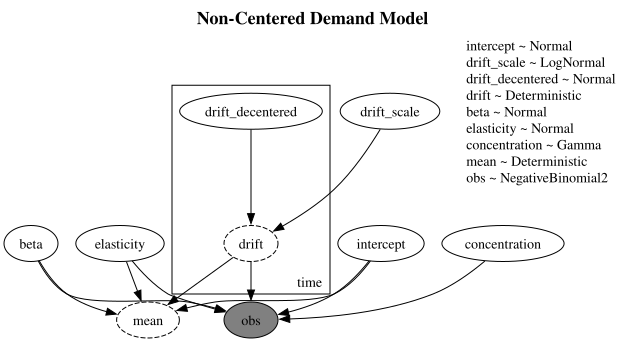

In [12]:
non_centered_model = handlers.reparam(
    demand_model, config={Site.DRIFT: LocScaleReparam(0)}
)
graph = numpyro.render_model(
    non_centered_model,
    model_args=(covariates_history, data),
    render_distributions=True,
)
graph.attr(label="<<b>Non-Centered Demand Model</b>>", labelloc="t", fontsize="18")
graph

The plate `time` holds the daily increments of the history. The sampler draws the standardized increments `drift_decentered`, and `drift` is their product with `drift_scale`. Together with the `intercept`, the weekly coefficients `beta` and the `elasticity`, the increments give the expected demand `mean`, and the `concentration` sets the noise of the observed demand `obs` around it.

Now we run the sampler.

In [13]:
%%time

TARGET_ACCEPT_PROB = 0.95
rng_key, key_fit = random.split(rng_key)
mcmc = MCMC(
    NUTS(non_centered_model, target_accept_prob=TARGET_ACCEPT_PROB),
    num_warmup=1_000,
    num_samples=1_000,
    num_chains=4,
)
mcmc.run(key_fit, covariates_history, data)

posterior = mcmc.get_samples()
rng_key, key_tree = random.split(rng_key)
idata = to_datatree(
    key_tree,
    non_centered_model,
    posterior,
    data,
    covariates_history,
    num_chains=4,
)

CPU times: user 1min 18s, sys: 17.4 s, total: 1min 35s
Wall time: 28.8 s


As in the first post, we look at the $\hat{R}$ values and the effective sample sizes of the global parameters. The assertion checks the $\hat{R}$ values, because the scenario sets and the forecast updates come from this fit.

In [14]:
summary = az.summary(idata, var_names=list(Site.PARAMETERS))
assert float(summary["r_hat"].max()) <= 1.01
summary

,mean,sd,eti94_lb,eti94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,4.015,0.054,3.9,4.1,3543,2649,1.00,0.00091,0.00095
drift_scale,0.0126,0.0046,0.0052,0.023,1307,2065,1.00,0.00013,7.4e-05
beta[0],0.1206,0.0174,0.088,0.15,6710,2587,1.00,0.00021,0.00033
beta[1],0.0249,0.0174,-0.0086,0.059,7375,2454,1.01,0.0002,0.00032
beta[2],-0.1227,0.0173,-0.16,-0.09,7886,2746,1.00,0.0002,0.0003
beta[3],0.133,0.0172,0.1,0.17,6802,2761,1.00,0.00021,0.00033
beta[4],0.0459,0.0175,0.013,0.079,9097,2785,1.00,0.00018,0.00032
beta[5],-0.0478,0.0172,-0.08,-0.016,7587,2830,1.00,0.0002,0.00033
elasticity,-1.688,0.1,-1.9,-1.5,6422,3103,1.00,0.0012,0.0016
concentration,27.79,3.2,22,34,4865,2973,1.00,0.046,0.054


The $\hat{R}$ values are at most $1.01$ and the effective sample sizes are above $1{,}000$ for every parameter, which is good!

### Scenario Sets

In the first post a scenario was a posterior predictive draw of the $15$ days. We shuffled the $4{,}000$ draws and used $1{,}000$ of them to build the plans, the **optimization set**, and the other $3{,}000$ to score them, the **test set**. Here we keep this split and make three changes.

- **Longer paths.** The longest lead time needs $15 + 3 = 18$ days of demand. The $3$ extra days have no promotion.
- **A validation set.** The neural policy has many parameters, so we choose its parameters on scenarios that it does not train on.
- **A split by posterior draw.** Every scenario comes from one posterior draw of the parameters and the level, and we split the draws. The training set, the validation set and the forecast updates use the $1{,}000$ optimization draws, and the test scenarios come from the other $3{,}000$ draws. So no policy sees the parameters behind a test scenario.

A scenario is still a posterior predictive draw. We take the parameters and the daily increments of a posterior draw, and we run the demand model on the history and the next $18$ days with these values fixed. The model then draws the increments and the demand of the new days, so every scenario continues the level of its own posterior draw. The function `forecast` of `numpyro_forecast` does this for a batch of posterior draws. It runs `Predictive`, which fixes the sites of each draw with the [effect handlers](https://num.pyro.ai/en/stable/tutorials/effect_handlers.html) of NumPyro and records what the model samples.

First, we shuffle the posterior draws and split them as above. Of the $1{,}000$ optimization draws, $800$ go to the training set and $200$ to the validation set, and each of them gives $5$ scenarios. The assertions check that no test draw is an optimization draw, and that the $5$ scenarios of a training draw sit in $5$ blocks with the same order of the draws.

In [15]:
class ScenarioSet(StrEnum):
    """Names of the scenario sets."""

    TRAINING = "training set"
    VALIDATION = "validation set"
    FORECAST = "forecast test set"
    TRUE_PROCESS = "true process test set"


NUM_DRAWS_OPT = 1_000
NUM_DRAWS_TRAIN = 800
PATHS_PER_DRAW = 5

rng_key, key_split = random.split(rng_key)
draw_order = random.permutation(key_split, posterior[Site.INTERCEPT].shape[0])
draws_opt, draws_test = draw_order[:NUM_DRAWS_OPT], draw_order[NUM_DRAWS_OPT:]
assert not jnp.isin(draws_opt, draws_test).any()

# the posterior draw behind every scenario, with 5 scenarios for each training and
# validation draw
draws_by_set: dict[ScenarioSet, Int[Array, " scenarios"]] = {
    ScenarioSet.TRAINING: jnp.tile(draws_opt[:NUM_DRAWS_TRAIN], PATHS_PER_DRAW),
    ScenarioSet.VALIDATION: jnp.tile(draws_opt[NUM_DRAWS_TRAIN:], PATHS_PER_DRAW),
    ScenarioSet.FORECAST: draws_test,
}
# the training scenarios are 5 blocks with the same order of the draws
draw_blocks = draws_by_set[ScenarioSet.TRAINING].reshape(PATHS_PER_DRAW, -1)
assert (draw_blocks == draws_opt[:NUM_DRAWS_TRAIN]).all()

pl.DataFrame(
    {
        "scenario set": [str(name) for name in draws_by_set],
        "posterior draws": [
            jnp.unique(draws).shape[0] for draws in draws_by_set.values()
        ],
        "scenarios": [draws.shape[0] for draws in draws_by_set.values()],
    }
)

scenario set,posterior draws,scenarios
str,i64,i64
"""training set""",800,4000
"""validation set""",200,1000
"""forecast test set""",3000,3000


The training set has $4{,}000$ scenarios, the validation set $1{,}000$ and the **forecast test set** $3{,}000$, one from each test draw. The split is by draw, so the validation set also has parameter values that the training set does not have.

Next, we draw the scenarios: $18$ days for every entry of the three sets. The function `posterior_of` returns the posterior samples of a batch of draws, and `draw_scenarios` passes them to `forecast`.

In [16]:
# the history and the days that we simulate for the longest lead time
covariates_sim = covariates[: setup.t_obs + setup.max_days]


def posterior_of(draws: Int[Array, " num"]) -> dict[str, Array]:
    """The posterior samples of the draws `draws`, one row per draw."""
    return jax.tree.map(lambda site: site[draws], posterior)


def draw_scenarios(
    key: PRNGKeyArray, draws: Int[Array, " scenarios"]
) -> Float[Array, "scenarios days"]:
    """One demand path of the simulated days for every posterior draw in `draws`."""
    paths = forecast(key, demand_model, posterior_of(draws), data, covariates_sim)
    return paths[..., 0].astype(jnp.float32)


rng_key, key_sets = random.split(rng_key)
demand_by_set: dict[ScenarioSet, Float[Array, "scenarios days"]] = {
    scenario_set: draw_scenarios(key, draws)
    for key, (scenario_set, draws) in zip(
        random.split(key_sets, len(draws_by_set)), draws_by_set.items(), strict=True
    )
}

Because the data are synthetic, we can also draw paths from the process that generated them. As in the data generation, the `do` handler fixes the true parameters, and now also the true increments of the history, so the model continues the true level. The **true process test set** has $3{,}000$ such paths. These scenarios tell us how a policy that was trained on the forecast does when the demand comes from the true process.

In [17]:
true_process = do(demand_model, data={**true_params, Site.DRIFT: true_increments})
rng_key, key_true = random.split(rng_key)
demand_true = Predictive(
    true_process, num_samples=draws_test.shape[0], return_sites=[Site.FORECAST]
)(key_true, covariates_sim, data)[Site.FORECAST]
demand_by_set[ScenarioSet.TRUE_PROCESS] = demand_true[..., 0].astype(jnp.float32)

Let's look at the forecast test set over the $18$ days, next to the last $4$ weeks of the history. We want to see whether the $3$ extra days look reasonable and where the true process lies inside the forecast. The bands are the $50\%$ and $94\%$ equal-tailed intervals (ETI) of the forecast test set, that is, the ranges between two percentiles.

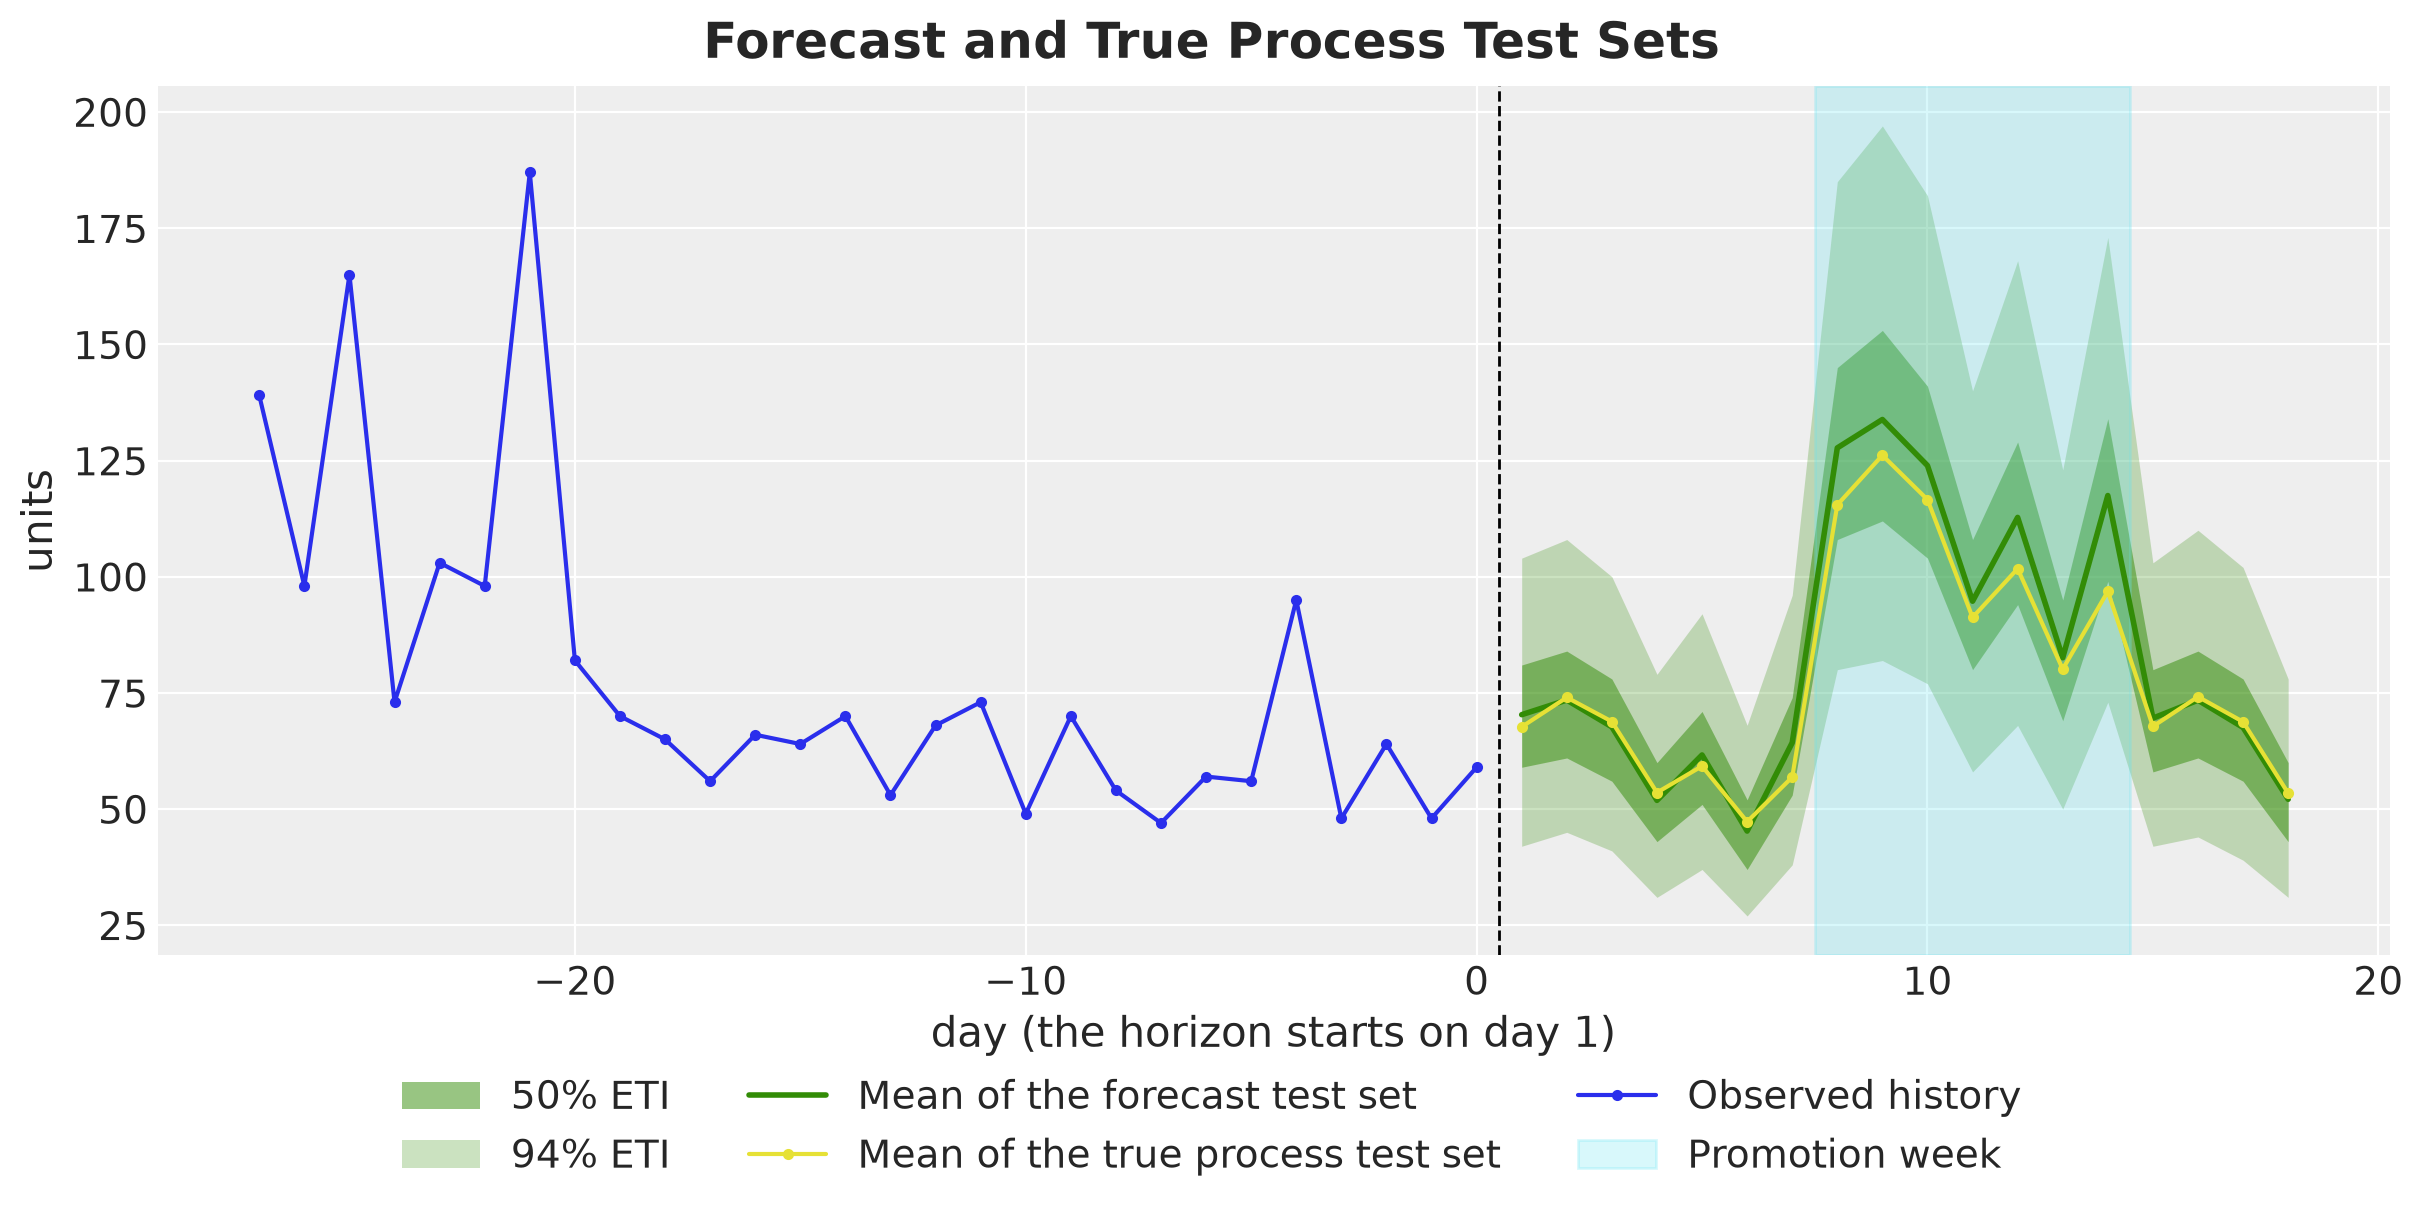

In [18]:
def lighten_bands(pc: az.PlotCollection, x: str) -> None:
    """Set the alpha of the 50% and 94% credible bands of a `plot_lm` collection."""
    bands = pc.viz["ci_band"][x]

    for prob, alpha in [(0.5, 0.5), (CI_PROB, 0.25)]:
        for band in bands.sel(prob=prob).values.flat:
            band.set_alpha(alpha)


def shade_promotion(ax: plt.Axes) -> None:
    """Shade the promotion week of the horizon."""
    promoted = jnp.flatnonzero(promo_future) + 1
    ax.axvspan(
        promoted[0] - 0.5,
        promoted[-1] + 0.5,
        color="C5",
        alpha=0.25,
        label="Promotion week",
    )


forecast_tree = az.from_dict(
    {
        "posterior_predictive": {"demand": demand_by_set[ScenarioSet.FORECAST][None]},
        "observed_data": {
            "demand": demand_by_set[ScenarioSet.TRUE_PROCESS].mean(axis=0)
        },
        # ArviZ sorts the x values in place, which a JAX array does not allow
        "constant_data": {"day": jax.device_get(horizon_days)},
    },
    coords={"time": horizon_days.tolist()},
    dims={"demand": ["time"], "day": ["time"]},
)

pc = az.plot_lm(
    forecast_tree,
    x="day",
    y="demand",
    y_obs="demand",
    smooth=False,
    ci_prob=(0.5, CI_PROB),
    point_estimate="mean",
    visuals={
        "ci_band": {"color": "C2"},
        "pe_line": {"color": "C2", "alpha": 1.0, "linewidth": 2},
        "observed_scatter": False,
    },
    figure_kwargs={"figsize": (12, 6)},
)
lighten_bands(pc, "day")
ax = pc.viz["plot"]["day"].item()
pc.viz["ci_band"]["day"].sel(prob=CI_PROB).item().set_label(f"{CI_PROB:.0%} ETI")
pc.viz["ci_band"]["day"].sel(prob=0.5).item().set_label("50% ETI")
pc.viz["pe_line"]["day"].item().set_label(f"Mean of the {ScenarioSet.FORECAST}")
ax.plot(
    horizon_days,
    demand_by_set[ScenarioSet.TRUE_PROCESS].mean(axis=0),
    "o-",
    markersize=3,
    color="C6",
    label=f"Mean of the {ScenarioSet.TRUE_PROCESS}",
)
# the two means are within 20% of each other on every day
assert jnp.allclose(
    demand_by_set[ScenarioSet.TRUE_PROCESS].mean(axis=0),
    demand_by_set[ScenarioSet.FORECAST].mean(axis=0),
    rtol=0.2,
)
history_days = jnp.arange(-27, 1)
ax.plot(
    history_days,
    data[-len(history_days) :, 0],
    "o-",
    markersize=3,
    color="C0",
    label="Observed history",
)
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
shade_promotion(ax)
ax.set(xlabel="day (the horizon starts on day $1$)", ylabel="units", title="")
fig = pc.viz["figure"].item()
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Forecast and True Process Test Sets", fontsize=18, fontweight="bold");

The forecast follows the weekly pattern and rises in the promotion week (the shaded days), as in the first post, and the $3$ extra days look like the first days of the horizon. The mean of the true process test set stays close to the mean of the forecast test set before and after the promotion week, except on day $7$. In the promotion week it is below it.

The posterior is not centered on every true parameter. For example, the posterior mean of the `elasticity` is $-1.69$ with a standard deviation of $0.10$, against a true value of $-1.5$. Some of the weekly coefficients `beta` are also about two standard deviations away from their true values. So the forecast expects more demand than the true process in the promotion week, and on some days of the week. Keep this in mind for the evaluation.

## Forecast Updates

In practice we do not keep the forecast of day one for the whole horizon. When new demand comes in, we run the forecasting model again. A retailer that runs its forecast every week updates it after the first week, and so do we: on day $8$ we update the forecast with the demand of the first week.

The direct way to update the forecast is to fit the model again with NUTS, on the history plus the first week. For a retailer this is fine. Our fit took about $30$ seconds, and a forecasting job that runs once per week usually runs overnight.

In this notebook the situation is different, because we train and test the policies on simulated scenarios. Each of the $11{,}000$ scenarios ($4{,}000 + 1{,}000 + 3{,}000 + 3{,}000$) has its own first week and needs its own update, and $11{,}000$ refits of $30$ seconds take about $90$ hours. So we look for an alternative that is much cheaper than a refit.

### State Space Model

The alternative uses the structure of the demand model. Recall its components from the *Demand Model* section. Let $\ell_t$ be the **log level** of the demand on day $t$, where $t$ now runs over the days of the history and of the horizon. The level moves from one day to the next by an increment $\varepsilon_t$ with scale $\sigma$ (`drift_scale`). Let $z_t$ be the covariates of day $t$ (the Fourier features and the log price), $\gamma$ their coefficients (`beta` and `elasticity`) and $\phi$ the `concentration`. Then the model of the demand $D_t$ is

$$
\begin{align*}
\ell_t &= \ell_{t-1} + \varepsilon_t, \qquad \varepsilon_t \sim \text{Normal}(0, \sigma), \\
D_t \mid \ell_t &\sim \text{NegativeBinomial}\left(\exp(\ell_t + z_t^{\top} \gamma), \phi\right),
\end{align*}
$$

where $\exp(\ell_t + z_t^{\top} \gamma)$ is the mean of the negative binomial, and the level before the first day of the history is the `intercept`. The level is a hidden **state** that moves as a random walk, and the demand of a day depends on the past only through the level of that day. A model with this structure is a **state space model**.

For a state space model with fixed parameters, a **filter** computes the distribution of the state of a day given the demand up to that day. It works one day at a time: the distribution of day $t$ follows from the distribution of day $t - 1$ and the demand of day $t$. So an update with one more week takes $7$ steps of the filter, and not a new fit. See [Särkkä and Svensson (2023)](https://users.aalto.fi/~ssarkka/pub/bfs_book_2023_online.pdf) for an introduction to filtering.

We do not write the filter ourselves. We use `dynestyx` and a module of `numpyro_forecast` that connects it with our model functions:

- **`dynestyx`.** It is a [library for state space models](https://basisresearch.github.io/dynestyx/stable/) built on NumPyro. We describe the model as a `DynamicalModel`, with an initial condition, a state evolution and an observation model, and the library provides the filters and a simulator. Handlers around the call that runs the model choose the filter and the simulator.
- **`numpyro_forecast.contrib.dynestyx`.** The block `state_space` runs a `DynamicalModel` inside a model function with the signature `(covariates, data=None)`, so `Predictive` and `forecast` work with it as with the demand model. The functions `end_state` and `start_state` carry the filtered level from one window of days to the next, so we filter the history only once.

These functions are in the development version of `numpyro_forecast`, which we install from GitHub. For more details, see the section ["Reusing a Filtered History"](https://juanitorduz.github.io/numpyro_forecast/v/dev/docs/examples/dynestyx_getting_started.html#reusing-a-filtered-history) of the getting started example and the example ["State Space Models with `dynestyx` and `numpyro_forecast`"](https://juanitorduz.github.io/numpyro_forecast/v/dev/docs/examples/dynestyx_integration.html), both in the development version of the documentation.

The best-known filter is the Kalman filter, which is exact for a linear model with Normal noise. Our demand is a count with a negative binomial distribution, so we use the **extended Kalman filter** of `dynestyx`, which is an approximation. It keeps a Normal approximation of the distribution of the level.

Let $m_t$ and $P_t$ be the mean and the variance of this Normal approximation for the level of day $t$, given the demand up to day $t$. Before we see the demand of day $t + 1$, its level is one step of the random walk away:

$$
\ell_{t+1} \mid D_1, \dots, D_t \sim \text{Normal}\left(m_t, \sqrt{P_t + \sigma^2}\right).
$$

The demand of day $t + 1$ then updates this distribution to the mean $m_{t+1}$ and the variance $P_{t+1}$.

A filter needs fixed parameters, and the fit gives us posterior draws of them. So we run one filter for every parameter draw, and the update has three steps:

1. **History.** For every posterior draw of the parameters, we filter the $364$ days of the history. This gives the distribution of the level on the last day of the history. We do this only once, and `end_state` returns the result as two sites.
2. **First week.** For a scenario, we continue the filter of every draw with the demand of days $1$ to $7$, from the level on the last day of the history.
3. **Simulation.** From the level of day $7$, we simulate the demand of the remaining days, one path for every draw.

Here is an important remark. The update keeps the parameter draws of the fit and moves only the level, so it ignores what the first week tells us about the parameters. We expect one week to add little to what a year of history says about them. In the *Appendix* we compare the update with a NUTS refit on $6$ scenarios. The two forecasts are close, except after the highest first week of the test set, where the refit moves the forecast further up.

Let's write the model. The function `make_state_space_model` writes the demand model in the form above, with the log level as the state. It has four parts:

- **Control.** The sum $z_t^{\top} \gamma$ of the weekly term and the price term is the **control** of day $t$, an input that the observation model adds to the level. The components `weekly_seasonality` and `price_effect` of the *Demand Model* section compute it.
- **Parameters.** The model reuses the component `dispersion` and the prior of `drift_scale` from the same section.
- **Start.** In place of the `intercept`, `start_state` reads two sites, the mean and the variance of the level on the day before the first day. The initial condition is one step of the random walk from there, as in the formula above.
- **Demand.** The block `state_space` reads the observed demand from `data`.

In [19]:
LEVEL: Final = "level"  # the name of the state space block


def make_state_space_model(priors: Priors) -> ForecastModel:
    """The demand model as a state space model, with the log level as the state."""

    def state_space_model(
        covariates: Float[Array, "days features"],
        data: Float[Array, "t_obs 1"] | None = None,
    ) -> None:
        h = Horizon.from_data(covariates, data)
        # the Fourier features in the first columns and the log price in the last one
        fourier, log_price = covariates[:, :-1], covariates[:, -1]
        drift_scale = numpyro.sample(Site.DRIFT_SCALE, priors.level.drift_scale)
        control = weekly_seasonality(fourier, priors.seasonality) + price_effect(
            log_price, priors.price
        )
        concentration = dispersion(priors.dispersion)
        # the mean and the variance of the level on the day before the first day
        mean, cov = start_state(LEVEL, 1)
        # dynestyx calls the functions by keyword, so the argument names are fixed
        dynamics = DynamicalModel(
            # the level of the first day is one step of the random walk away
            initial_condition=dist.MultivariateNormal(
                mean, cov + drift_scale**2 * jnp.eye(1)
            ),
            state_evolution=lambda x, u, t_now, t_next: dist.Normal(
                x, drift_scale
            ).to_event(1),
            observation_model=lambda x, u, t: dist.NegativeBinomial2(
                jnp.exp(x + u), concentration
            ).to_event(1),
            control_dim=1,
        )
        state_space(h, LEVEL, data, dynamics, controls=control)

    return state_space_model


state_space_model = make_state_space_model(priors)

Now we run the first step. Before the history starts, the level of a draw is its `intercept`, a known number, so its variance is zero. We give these values to the two sites of `start_state`, together with the $1{,}000$ optimization draws, and run `Predictive` under the extended Kalman filter `extended_kalman`. Recall from the *Scenario Sets* section that `Predictive` fixes the sites of each draw.

`dynestyx` records the mean and the variance of the filtered level of every day. The function `end_state` takes those of the last day of the history and returns them under the names of the two sites. So `posterior_resumed` holds, for every draw, the parameters and the mean and the variance of the level at the end of the history.

The fit gives us a check of the filter. For every draw it has a level on the last day of the history, the `intercept` plus the sum of the daily increments, and this level should be a draw from the Normal distribution that the filter gives for the same parameters. So we standardize the levels of the fit with the mean and the standard deviation of their filter, and the assertions check that the result has mean zero and standard deviation one within $0.1$.

In [20]:
def last_level(samples: dict[str, Array]) -> Float[Array, " draws"]:
    """Log level on the last day of the history: the intercept plus the increments."""
    return samples[Site.INTERCEPT] + samples[Site.DRIFT].sum(axis=(1, 2))


posterior_opt = posterior_of(draws_opt)
# the parameters of the optimization draws, without the increments of the level
params_opt = {site: posterior_opt[site] for site in Site.PARAMETERS}
START_MEAN: Final = f"{LEVEL}_start_mean"
START_COV: Final = f"{LEVEL}_start_cov"
# before the history the level of a draw is its intercept, a known number
start_history = {
    START_MEAN: params_opt[Site.INTERCEPT][:, None],
    START_COV: jnp.zeros((NUM_DRAWS_OPT, 1, 1)),
}
rng_key, key_history = random.split(rng_key)
extended_kalman = Filter(filter_config=EKFConfig())

with extended_kalman:
    filtered_history = Predictive(
        state_space_model, posterior_samples=params_opt | start_history
    )(key_history, covariates_history, data.astype(jnp.float32))

posterior_resumed = params_opt | end_state(filtered_history, LEVEL)

# the level of every draw on the last day of the history, from the fit
level_fit = last_level(posterior_opt)
filtered_mean = posterior_resumed[START_MEAN][:, 0]
filtered_scale = jnp.sqrt(posterior_resumed[START_COV][:, 0, 0])
standardized = (level_fit - filtered_mean) / filtered_scale
assert jnp.abs(standardized.mean()) < 0.1
assert jnp.abs(standardized.std() - 1.0) < 0.1

The assertions pass, which is good! Next, we write steps $2$ and $3$ for one scenario. The function `update_forecast` calls `forecast` with `posterior_resumed` and the demand of the observed days, so the model of every draw starts from its level at the end of the history.

The handlers around the call decide what the block does with the days. Under `extended_kalman` it filters the observed days, and under `DiscreteTimeSimulator` it simulates the remaining days from the last filtered level, one path for every draw. So `update_forecast` returns $1{,}000$ paths.

In [21]:
covariates_future = covariates[setup.t_obs :]


def update_forecast(
    key: PRNGKeyArray, observed: Float[Array, " observed"]
) -> Float[Array, "draws days"]:
    """Forecast paths of the days after `observed`, one for every parameter draw."""
    with DiscreteTimeSimulator(n_simulations=1), extended_kalman:
        paths = forecast(
            key,
            state_space_model,
            posterior_resumed,
            observed[:, None],
            covariates_future,
        )

    return paths[..., 0].astype(jnp.float32)

Now that we have the update, we can compute the forecast that the policies read.

### Weekly Forecast

A policy does not need the whole forecast. Recall from the *Policies* section that on day $t$ the base-stock policy needs the newsvendor level $\hat{q}_t$ of the latest forecast: the $p / (p + h)$ quantile of the total demand $D_t + \dots + D_{t+L}$ of the days that the order of day $t$ has to cover. The neural policy also reads the mean of the same total. So for every day and lead time we keep these two numbers in a `Forecast` tuple.

The function `summarize_forecast` computes them from forecast paths, for every lead time and for a given quantile. We start with the forecast of day one, which needs no filter. As for the scenario sets, the function `forecast` of `numpyro_forecast` draws its paths: $4{,}000$ paths of $21$ days from the optimization draws, four for every draw. We take the quantile $p / (p + h) = 2 / 2.1 \approx 0.952$, and the table shows the newsvendor levels of the first $3$ days.

In [22]:
class Forecast(NamedTuple):
    """Newsvendor level and mean of the total demand of the days t, ..., t + L."""

    level: Float[Array, "*batch"]
    mean: Float[Array, "*batch"]


def summarize_forecast(
    paths: Float[Array, "paths days_ahead"], num_days: int, fractile: float
) -> Forecast:
    """Levels and means of the totals over the days t, ..., t + L of the paths.

    Both have shape `(num_days, lead_times)`, one column per lead time.
    """
    cumulative = jnp.cumsum(jnp.pad(paths, ((0, 0), (1, 0))), axis=1)
    first = jnp.arange(num_days)[:, None]
    last = first + jnp.asarray(setup.lead_times)[None, :]
    # total demand of the days t, ..., t + L: shape (paths, num_days, lead_times)
    totals = cumulative[:, last + 1] - cumulative[:, first]
    return Forecast(jnp.quantile(totals, fractile, axis=0), totals.mean(axis=0))


DAY_ONE_PATHS_PER_DRAW = 4
rng_key, key_day_one = random.split(rng_key)
# on all the days with covariates: the simulated days and the lead time of the last one
paths_day_one = forecast(
    key_day_one,
    demand_model,
    posterior_of(jnp.tile(draws_opt, DAY_ONE_PATHS_PER_DRAW)),
    data,
    covariates,
)[..., 0].astype(jnp.float32)
assert paths_day_one.shape[1] == setup.num_future
forecast_day_one = summarize_forecast(
    paths_day_one, setup.max_days, critical_fractile(config)
)
pl.DataFrame(
    {
        "day": [1, 2, 3],
        **{
            f"L = {lead_time}": forecast_day_one.level[:3, k].tolist()
            for k, lead_time in enumerate(setup.lead_times)
        },
    }
)

day,L = 0,L = 1,L = 2,L = 3
i64,f64,f64,f64,f64
1,98.0,185.0,264.0,321.0
2,104.0,182.0,242.0,310.0
3,96.0,155.0,227.0,278.0


The level grows with the lead time, since the order of day $t$ covers $L + 1$ days.

Now we compute the weekly forecast of a path with the function `weekly_forecast`. Up to day $7$ it is the forecast of day one. From day $8$ on it summarizes the $1{,}000$ paths of `update_forecast`. These paths cover days $8$ to $18$, the rest of the simulated days, plus $3$ days for the lead time of the last day. Let's compare the levels of the first test scenario at $L = 2$ with the levels of day one.

In [23]:
NUM_OBSERVED = setup.update_after  # the days that the update sees, the first week
num_remaining = setup.max_days - NUM_OBSERVED


def weekly_forecast(
    key: PRNGKeyArray, path: Float[Array, " days"], fractile: float
) -> Forecast:
    """The forecast of day one for the first week and the update for the other days."""
    paths = update_forecast(key, path[:NUM_OBSERVED])
    first_week = jax.tree.map(lambda leaf: leaf[:NUM_OBSERVED], forecast_day_one)
    return jax.tree.map(
        lambda before, after: jnp.concatenate([before, after]),
        first_week,
        summarize_forecast(paths, num_remaining, fractile),
    )


LEAD_TIME_DETAIL = 2  # the lead time that we look at in detail
lead_index_detail = setup.lead_times.index(LEAD_TIME_DETAIL)
path_example = demand_by_set[ScenarioSet.FORECAST][0]
days_example = jnp.array([0, 6, 7, 13, 14])
rng_key, key_example = random.split(rng_key)
forecast_example = jax.jit(
    lambda key, path: weekly_forecast(key, path, critical_fractile(config))
)(key_example, path_example)
pl.DataFrame(
    {
        "day": (days_example + 1).tolist(),
        "day-one level": forecast_day_one.level[
            days_example, lead_index_detail
        ].tolist(),
        "weekly level": forecast_example.level[
            days_example, lead_index_detail
        ].tolist(),
    }
)

day,day-one level,weekly level
i64,f64,f64
1,264.0,264.0
7,406.0,406.0
8,479.0,466.4
14,327.0,312.4
15,266.0,255.0


Up to day $7$ the two levels are the same, since the weekly forecast is the forecast of day one. On days $8$, $14$ and $15$ the levels of this scenario are lower, by $13$, $15$ and $11$ units.

Here is an important observation. We observe the demand and not the sales, so the forecast of a day depends on the demand of the earlier days and not on the orders. The orders cannot change it. So we can compute the weekly forecast of every scenario once, before we train any policy, and give it to the simulator as an input.

We do this for the four scenario sets, in batches of $500$ scenarios. We keep the random key of every scenario, so that we can repeat the computation with the same random numbers. We also check the result. The scenarios of the forecast test set have the same distribution as the paths of the forecast of day one. So the mean of their weekly forecasts over the scenarios should give back the mean of the forecast of day one, up to the approximation of the update and the Monte Carlo error. The assertion checks this within $2\%$ for every day from day $8$ on and every lead time.

In [24]:
%%time

forecast_scenarios = jax.jit(
    lambda keys, paths: jax.lax.map(
        lambda inputs: weekly_forecast(*inputs, critical_fractile(config)),
        (keys, paths),
        batch_size=500,
    )
)
forecast_keys: dict[ScenarioSet, UInt32[Array, "scenarios 2"]] = {}
forecast_by_set: dict[ScenarioSet, Forecast] = {}

for scenario_set, paths in demand_by_set.items():
    rng_key, key_set = random.split(rng_key)
    forecast_keys[scenario_set] = random.split(key_set, paths.shape[0])
    forecast_by_set[scenario_set] = forecast_scenarios(
        forecast_keys[scenario_set], paths
    )

forecast_by_set = jax.block_until_ready(forecast_by_set)
# the weekly forecasts of the forecast test set average to the forecast of day one
assert jnp.allclose(
    forecast_by_set[ScenarioSet.FORECAST].mean[:, NUM_OBSERVED:].mean(axis=0),
    forecast_day_one.mean[NUM_OBSERVED:],
    rtol=0.02,
)
{str(name): forecast.level.shape for name, forecast in forecast_by_set.items()}

CPU times: user 24min 5s, sys: 11min 14s, total: 35min 19s
Wall time: 8min 22s


{'training set': (4000, 18, 4),
 'validation set': (1000, 18, 4),
 'forecast test set': (3000, 18, 4),
 'true process test set': (3000, 18, 4)}

Every set now has a level and a mean for every scenario, day and lead time, and the assertion passes. The next figure shows the weekly levels at $L = 2$ on the two test sets: the median and the $50\%$ and $94\%$ intervals over the scenarios, with the levels of day one as a black line. On the panel of the true process test set we add the newsvendor level of the true process itself, the same quantile of the demand of that set.

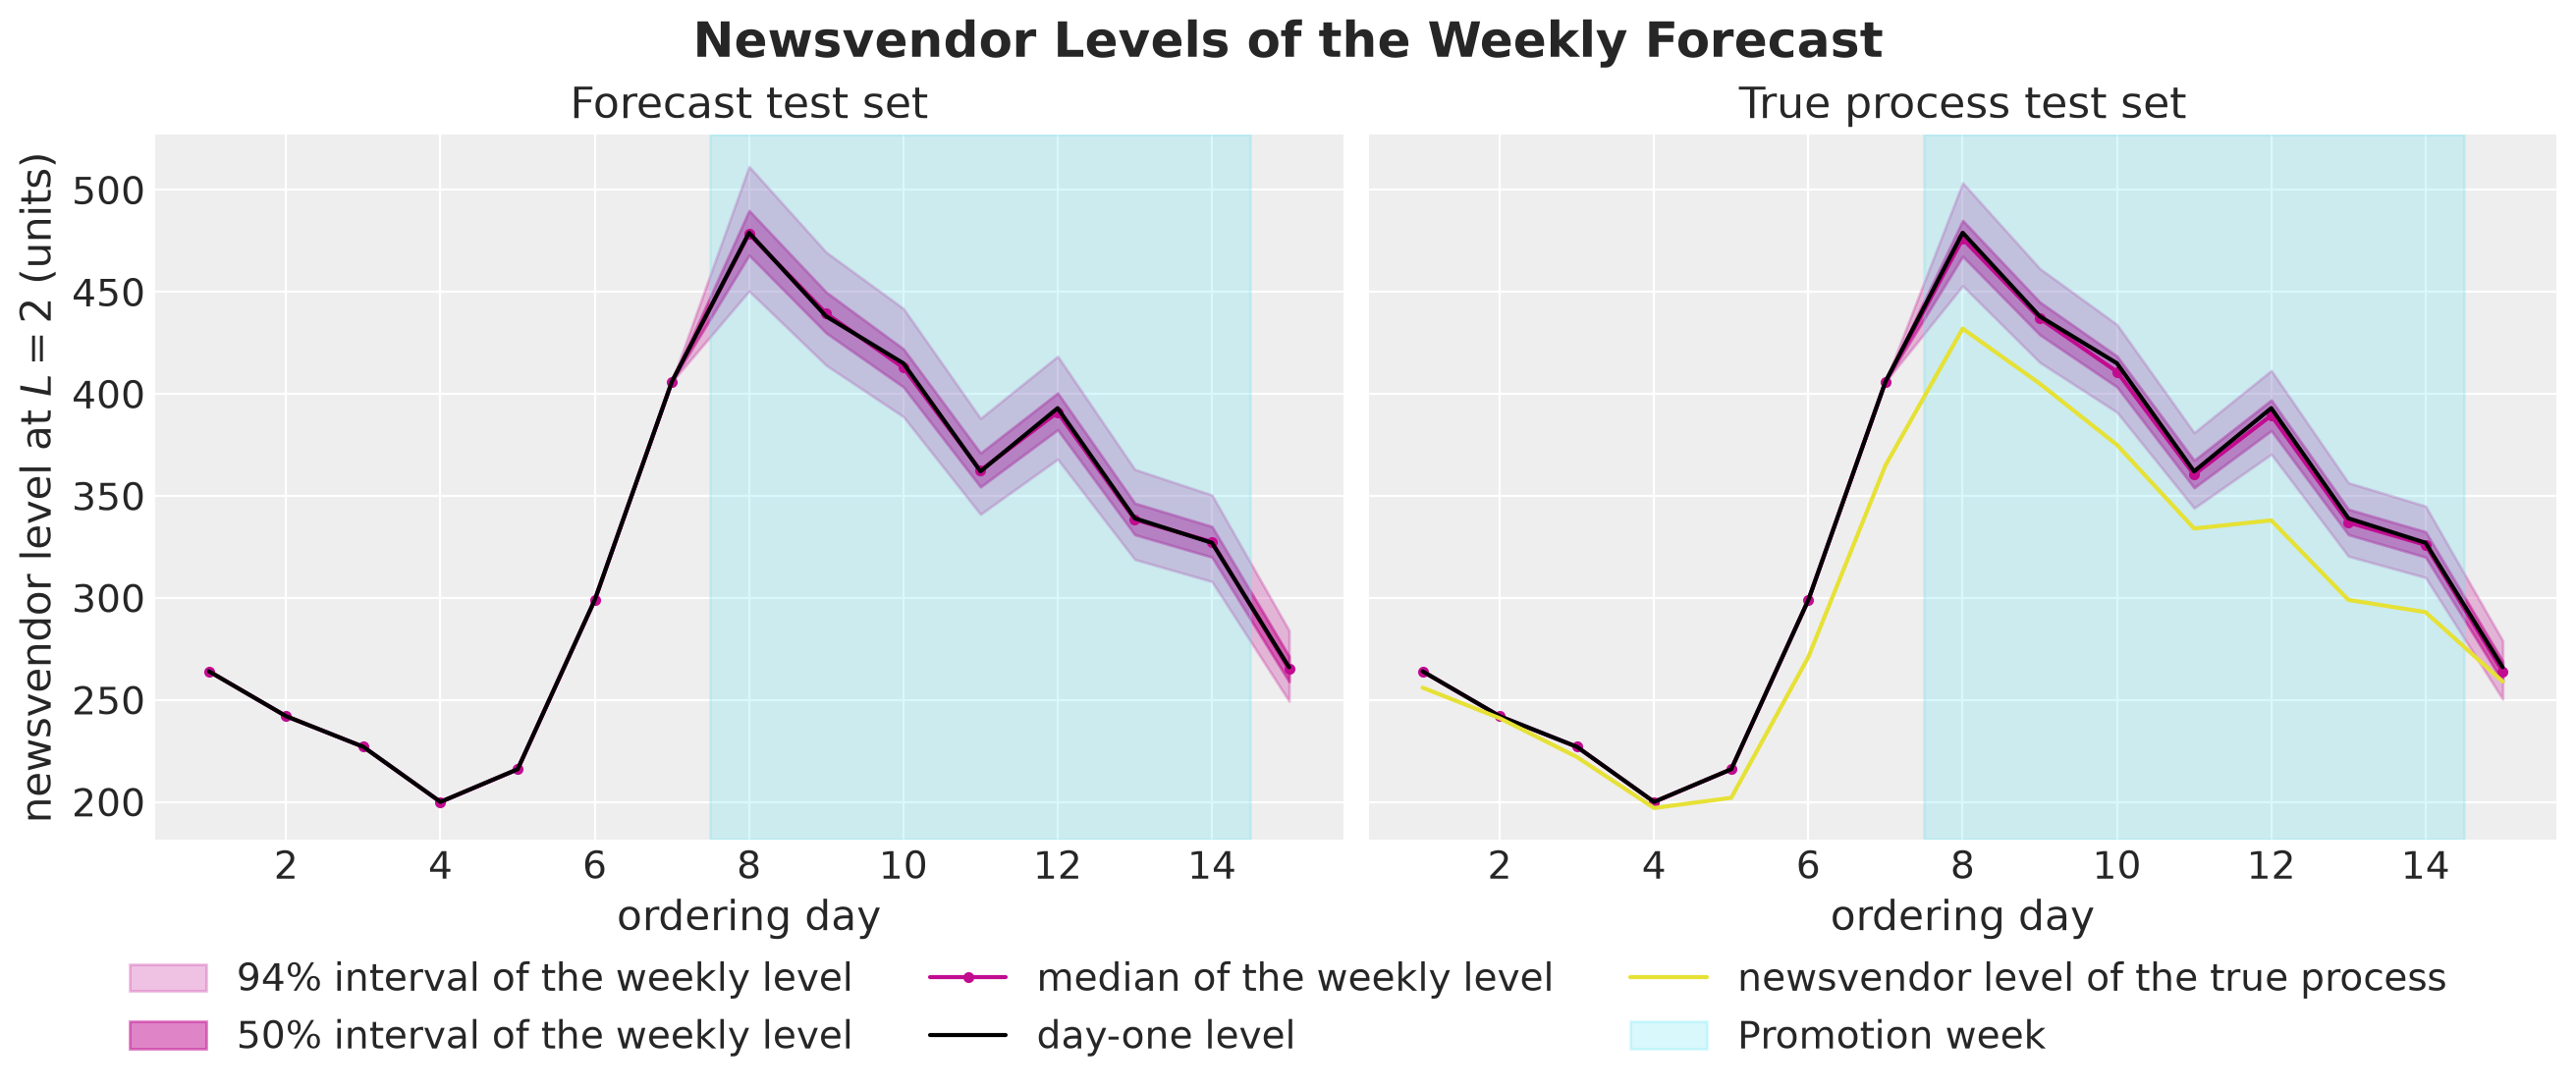

In [25]:
TEST_SETS = [ScenarioSet.FORECAST, ScenarioSet.TRUE_PROCESS]

fig, axes = plt.subplots(
    ncols=2, figsize=(13, 5.5), sharex=True, sharey=True, layout="constrained"
)
ordering_days = jnp.arange(1, setup.horizon + 1)

for ax, scenario_set in zip(axes, TEST_SETS, strict=True):
    levels = forecast_by_set[scenario_set].level[:, : setup.horizon, lead_index_detail]

    for prob, alpha in [(CI_PROB, 0.25), (0.5, 0.5)]:
        ax.fill_between(
            ordering_days,
            jnp.quantile(levels, (1 - prob) / 2, axis=0),
            jnp.quantile(levels, (1 + prob) / 2, axis=0),
            color="C3",
            alpha=alpha,
            label=f"{prob:.0%} interval of the weekly level",
        )

    ax.plot(
        ordering_days,
        jnp.median(levels, axis=0),
        "o-",
        markersize=3,
        color="C3",
        label="median of the weekly level",
    )
    ax.plot(
        ordering_days,
        forecast_day_one.level[: setup.horizon, lead_index_detail],
        color="black",
        label="day-one level",
    )

    if scenario_set == ScenarioSet.TRUE_PROCESS:
        level_true_process = summarize_forecast(
            demand_by_set[scenario_set], setup.horizon, critical_fractile(config)
        ).level[:, lead_index_detail]
        ax.plot(
            ordering_days,
            level_true_process,
            color="C6",
            label="newsvendor level of the true process",
        )
        # on the ordering days of the promotion week the level of the true process
        # is below the 94% interval of the weekly levels
        lower_edge = jnp.quantile(levels, (1 - CI_PROB) / 2, axis=0)
        is_promotion_day = promo_future[: setup.horizon] == 1.0
        assert (level_true_process < lower_edge)[is_promotion_day].all()

    shade_promotion(ax)
    ax.set(title=scenario_set.capitalize(), xlabel="ordering day")

axes[0].set(ylabel=f"newsvendor level at $L = {LEAD_TIME_DETAIL}$ (units)")
fig.legend(*axes[1].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle(
    "Newsvendor Levels of the Weekly Forecast", fontsize=18, fontweight="bold"
);

Up to day $7$ there is no band, since every scenario uses the forecast of day one. From day $8$ on the levels spread around the day-one levels, and the $94\%$ interval on day $8$ is about $60$ units wide on the forecast test set. The median stays within about $2$ units of the day-one level, so on this set the update moves the levels up in some scenarios and down in others, with no clear shift on average.

On the true process test set the weekly levels stay close to the day-one levels as well. But on every ordering day of the promotion week the newsvendor level of the true process lies below the whole $94\%$ interval of the weekly levels, which the assertion checks. The gap is small on days $1$ to $4$ and widens on days $5$ to $7$. The levels of days $6$ and $7$ at $L = 2$ cover the first promotion days, and the levels of all three cover day $7$, where the forecast is above the true process.

The update cannot close this gap. It comes from the parameters: the `elasticity`, which sets the size of the promotion, and the weekly coefficients. The update keeps the parameter draws of the fit. Recall from the *Scenario Sets* section that the posterior mean of the `elasticity` is $-1.69$ against a true value of $-1.5$. A refit would move it only a little, because the demand of a week without a promotion does not depend on the `elasticity`. In the $6$ refits of the *Appendix* its posterior mean stays between $-1.70$ and $-1.66$.

Finally, we check that the forecast of a day does not use the demand of that day or of a later day. We add $50$ units to the demand of every validation scenario from day $8$ on, the day of the update, and compute the weekly forecast again with the same keys. The update uses the first week only, so no level should change. As a control, we also add $50$ units to the demand of day $7$ alone. Then the level of every day from day $8$ on should change in some scenarios, and the levels of the first week should not change.

In [26]:
CHANGED_FROM = setup.update_after  # index of the first day whose demand we change

demand_val = demand_by_set[ScenarioSet.VALIDATION]
level_original = forecast_by_set[ScenarioSet.VALIDATION].level
forecast_changed, forecast_day_7 = (
    forecast_scenarios(forecast_keys[ScenarioSet.VALIDATION], paths)
    for paths in (
        demand_val.at[:, CHANGED_FROM:].add(50.0),
        demand_val.at[:, CHANGED_FROM - 1].add(50.0),
    )
)
assert jnp.array_equal(forecast_changed.level, level_original)
assert jnp.array_equal(
    forecast_day_7.level[:, :CHANGED_FROM], level_original[:, :CHANGED_FROM]
)
# every day from the update on changes in at least one scenario
assert (
    (forecast_day_7.level[:, CHANGED_FROM:] != level_original[:, CHANGED_FROM:])
    .any(axis=0)
    .all()
)

The three assertions pass: the forecast of a day only depends on the demand before the day of its update.

Now that every scenario has its weekly forecast, we can build the simulator in which the policies place their orders.

## Inventory Simulator

The simulator of the first post took a vector of orders and a demand path and returned the loss. The new simulator takes a policy and its parameters in place of the orders, and the forecast of every day as a second input. It is again a `jax.lax.scan` over the days, and every iteration runs the five steps of a day from the *Lead Time* section. We start with the state and the observation.

- **State.** The scan carries the `InventoryState` from one day to the next: the stock on hand, the pipeline as a vector of length $L$, and the last $K$ demands. The function `initial_state` returns the state before day one, the same for every policy: the initial stock, the initial pipeline and the demand of the last $7$ days of the history.
- **Observation.** The function `observe` receives the order that arrives and builds the `Observation` from the state, the day and the forecast of the day. It does not take the demand as an argument, so no policy can see the demand of the day on which it orders. A policy that reads no forecast gets `None`.

Let's look at the observation of day one for $L = 2$, without a forecast.

In [27]:
class InventoryState(NamedTuple):
    """What the simulator carries from one day to the next."""

    inventory: Float[Array, ""]  # stock on hand at the end of the day
    pipeline: Float[Array, " lead_time"]  # orders on their way, the first arrives next
    demand_history: Float[Array, " window"]  # the last demands, most recent last


class Observation(NamedTuple):
    """What a policy sees on a day, before the demand of that day."""

    day: Int[Array, ""]
    inventory: Float[Array, ""]  # stock on hand after the arrival of the day
    pipeline: Float[Array, " in_transit"]  # orders that arrive on later days
    position: Float[Array, ""]  # stock on hand plus pipeline
    demand_history: Float[Array, " window"]
    forecast: Forecast | None  # the latest forecast of the days t, ..., t + L


def initial_state(lead_time: int) -> InventoryState:
    """The state before day one, the same for every policy."""
    return InventoryState(
        inventory=jnp.asarray(config.initial_inventory),
        # each order in the pipeline is the median demand of the day on which it arrives
        pipeline=jnp.median(demand_by_set[ScenarioSet.TRAINING][:, :lead_time], axis=0),
        demand_history=data[-setup.history_window :, 0].astype(jnp.float32),
    )


def observe(
    state: InventoryState,
    day: Int[Array, ""],
    forecast: Forecast | None,
    lead_time: int,
) -> Observation:
    """Receive the order that arrives today and collect what a policy may see."""
    if lead_time > 0:
        inventory = state.inventory + state.pipeline[0]
        in_transit = state.pipeline[1:]
    else:
        inventory, in_transit = state.inventory, state.pipeline

    return Observation(
        day=day,
        inventory=inventory,
        pipeline=in_transit,
        position=inventory + in_transit.sum(),
        demand_history=state.demand_history,
        forecast=forecast,
    )


observe(initial_state(LEAD_TIME_DETAIL), jnp.asarray(0), None, LEAD_TIME_DETAIL)

Observation(day=Array(0, dtype=int32, weak_type=True), inventory=Array(119., dtype=float32), pipeline=Array([72.], dtype=float32), position=Array(191., dtype=float32), demand_history=Array([57., 56., 95., 48., 64., 48., 59.], dtype=float32), forecast=None)

On day one the first order of the initial pipeline has arrived, so the stock on hand is the initial stock of $50$ units plus that order. The second order of the initial pipeline arrives on day two, and the inventory position adds it.

Next, the function `inventory_step` asks the policy for the order, appends it to the pipeline, sells, and charges the cost if the day is in the cost window. It returns a `DayResult`: the state at the end of the day and the record of the day, a `Simulation` with the cost, the order, the stock and the lost sales.

The simplest policy is the fixed plan. Its order on day $t$ is the entry $\theta_t$ of a vector of orders, whatever the observation. As a plan we take the mean demand of the training scenarios on the day on which each order arrives, which the function `mean_demand_plan` computes. Let's follow the first scenario of the training set through its first five days at $L = 2$.

In [28]:
class Simulation(NamedTuple):
    """Daily cost, orders, stock and lost sales of a policy on demand paths."""

    daily_cost: Float[Array, "*scenarios days"]
    orders: Float[Array, "*scenarios days"]
    inventory: Float[Array, "*scenarios days"]
    lost_sales: Float[Array, "*scenarios days"]

    @property
    def loss(self) -> Float[Array, "*scenarios"]:
        """Sum of the daily costs, which are zero outside the cost window."""
        return self.daily_cost.sum(axis=-1)


class DayResult(NamedTuple):
    """The state at the end of a day and the record of that day."""

    state: InventoryState
    record: Simulation


type Policy = Callable[[PyTree, Observation], Float[Array, ""]]


def inventory_step(
    policy: Policy,
    params: PyTree,
    state: InventoryState,
    demand_t: Float[Array, ""],
    forecast_t: Forecast | None,
    day: Int[Array, ""],
    config: InventoryConfig,
    lead_time: int,
) -> DayResult:
    """One day of the inventory dynamics: receive, observe, order, sell, pay."""
    observation = observe(state, day, forecast_t, lead_time)
    # no orders after day H
    order = jnp.where(day < setup.horizon, policy(params, observation), 0.0)

    if lead_time > 0:
        inventory = observation.inventory
        pipeline = jnp.concatenate([observation.pipeline, order[None]])
    else:
        # without a lead time the order is on the shelf before the demand
        inventory = observation.inventory + order
        pipeline = observation.pipeline

    sales = jnp.minimum(inventory, demand_t)
    lost_sales = demand_t - sales
    inventory = inventory - sales
    in_cost_window = (day >= lead_time) & (day < setup.horizon + lead_time)
    daily_cost = jnp.where(
        in_cost_window,
        config.holding_cost * inventory + config.lost_sales_cost * lost_sales,
        0.0,
    )
    demand_history = jnp.concatenate([state.demand_history[1:], demand_t[None]])
    return DayResult(
        state=InventoryState(inventory, pipeline, demand_history),
        record=Simulation(daily_cost, order, inventory, lost_sales),
    )


def fixed_plan(params: Float[Array, " horizon"], obs: Observation) -> Float[Array, ""]:
    """The order of a day is one number per ordering day."""
    return params[obs.day]


def mean_demand_plan(lead_time: int) -> Float[Array, " horizon"]:
    """Mean demand of the training scenarios on the day on which each order arrives."""
    demand = demand_by_set[ScenarioSet.TRAINING]
    return demand[:, lead_time : lead_time + setup.horizon].mean(axis=0)


NUM_DEMO_DAYS = 5
state = initial_state(LEAD_TIME_DETAIL)
plan = mean_demand_plan(LEAD_TIME_DETAIL)
path = demand_by_set[ScenarioSet.TRAINING][0]
rows = []

for day in range(NUM_DEMO_DAYS):
    # the order that arrives at the start of the day
    arrival = state.pipeline[0]
    state, record = inventory_step(
        fixed_plan,
        plan,
        state,
        path[day],
        None,
        jnp.asarray(day),
        config,
        LEAD_TIME_DETAIL,
    )
    rows.append(
        {
            "day": day + 1,
            "arrival": float(arrival),
            "order": float(record.orders),
            "demand": float(path[day]),
            "lost sales": float(record.lost_sales),
            "stock at the end": float(record.inventory),
            "cost": float(record.daily_cost),
        }
    )

pl.DataFrame(rows)

day,arrival,order,demand,lost sales,stock at the end,cost
i64,f64,f64,f64,f64,f64,f64
1,69.0,67.6,89.0,0.0,30.0,0.0
2,72.0,51.1,62.0,0.0,40.0,0.0
3,67.6,61.1,60.0,0.0,47.6,4.8
4,51.1,44.7,64.0,0.0,34.7,3.5
5,61.1,64.1,35.0,0.0,60.8,6.1


The order of day $1$, $67.6$ units, arrives on day $3$, and the order of day $2$ arrives on day $4$. On days $1$ and $2$ the arrivals come from the initial pipeline, and the cost is zero because these days are not in the cost window. From day $3$ on we pay the holding cost of $0.1$ per unit left on the shelf at the end of the day. In this scenario no demand is lost in the first five days.

Next, the function `simulate` scans `inventory_step` over a demand path, and `simulate_scenarios` vectorizes it over the scenarios with `jax.vmap`. Both take a `Scenarios` tuple: the demand paths and the forecast of every day, or `None`. The function `scenarios_for` builds this tuple for a scenario set, a lead time and the forecast that a policy reads, which the `ForecastSource` enumeration names: none, the forecast of day one or the weekly forecast. It keeps the $H + L$ days that we simulate for the lead time, and the forecast of that lead time.

The lead time changes the shape of the pipeline, so it is a static argument and JAX compiles the simulator once per lead time. The costs are ordinary arguments, so we can change them later without a new compilation. We run the mean demand plan of every lead time on the training set and check the result below.

In [29]:
class ForecastSource(StrEnum):
    """The forecast that a policy reads."""

    NONE = "no forecast"
    DAY_ONE = "day-one forecast"
    WEEKLY = "weekly forecast"


class Scenarios(NamedTuple):
    """Demand paths and the forecast of every day of every path."""

    demand: Float[Array, "*scenarios days"]
    forecast: Forecast | None


def scenarios_for(
    scenario_set: ScenarioSet,
    lead_time: int,
    source: ForecastSource,
    day_one: Forecast = forecast_day_one,
) -> Scenarios:
    """The days that we simulate for a lead time, with the forecast of a source."""
    num_days = setup.horizon + lead_time
    demand = demand_by_set[scenario_set][:, :num_days]
    column = setup.lead_times.index(lead_time)

    if source == ForecastSource.DAY_ONE:
        # the same forecast for every scenario
        forecast = jax.tree.map(
            lambda leaf: jnp.broadcast_to(
                leaf[:num_days, column], (demand.shape[0], num_days)
            ),
            day_one,
        )
    elif source == ForecastSource.WEEKLY:
        forecast = jax.tree.map(
            lambda leaf: leaf[:, :num_days, column], forecast_by_set[scenario_set]
        )
    else:
        forecast = None

    return Scenarios(demand, forecast)


def simulate(
    policy: Policy,
    params: PyTree,
    scenario: Scenarios,
    state: InventoryState,
    config: InventoryConfig,
    lead_time: int,
) -> Simulation:
    """Run a policy against one demand path from day one on."""

    def step(
        state: InventoryState,
        inputs: tuple[Float[Array, ""], Forecast | None, Int[Array, ""]],
    ) -> tuple[InventoryState, Simulation]:
        demand_t, forecast_t, day = inputs
        # `jax.lax.scan` needs a pair: the carry and the output of the day
        day_result = inventory_step(
            policy, params, state, demand_t, forecast_t, day, config, lead_time
        )
        return day_result.state, day_result.record

    days = jnp.arange(scenario.demand.shape[0])
    _, simulation = jax.lax.scan(
        step, state, (scenario.demand, scenario.forecast, days)
    )
    return simulation


def simulate_scenarios(
    policy: Policy,
    params: PyTree,
    scenarios: Scenarios,
    state: InventoryState,
    config: InventoryConfig,
    lead_time: int,
) -> Simulation:
    """Run a policy against a batch of demand paths from the same initial state."""
    return jax.vmap(
        lambda scenario: simulate(policy, params, scenario, state, config, lead_time)
    )(scenarios)


simulate_scenarios_jit = jax.jit(
    simulate_scenarios, static_argnames=("policy", "lead_time")
)

simulations_mean_plan = {
    lead_time: simulate_scenarios_jit(
        fixed_plan,
        mean_demand_plan(lead_time),
        scenarios_for(ScenarioSet.TRAINING, lead_time, ForecastSource.NONE),
        initial_state(lead_time),
        config,
        lead_time,
    )
    for lead_time in setup.lead_times
}
{lead_time: sim.loss.shape for lead_time, sim in simulations_mean_plan.items()}

{0: (4000,), 1: (4000,), 2: (4000,), 3: (4000,)}

Every lead time has one loss for each of the $4{,}000$ training scenarios. Given the orders that come out of the scan, we can write the dynamics of a whole path at once and compare them with the scan:

- **Arrivals.** The order that arrives on day $t$ is the initial pipeline for $t \leq L$ and the order of day $t - L$ afterwards.
- **Stock and lost sales.** The stock available on day $t$ is $y_t = I_{t-1}$ plus the arrival, and the scan has to return $I_t = (y_t - D_t)^{+}$ and $U_t = (D_t - y_t)^{+}$.

In [30]:
for lead_time, simulation in simulations_mean_plan.items():
    demand = scenarios_for(ScenarioSet.TRAINING, lead_time, ForecastSource.NONE).demand
    state = initial_state(lead_time)
    num_scenarios, num_days = demand.shape

    # arrivals: the initial pipeline, then the orders placed `lead_time` days before
    arrivals = jnp.concatenate(
        [
            jnp.broadcast_to(state.pipeline, (num_scenarios, lead_time)),
            simulation.orders,
        ],
        axis=1,
    )[:, :num_days]

    # stock available: the stock at the end of the day before plus the arrival
    stock_before = jnp.concatenate(
        [
            jnp.full((num_scenarios, 1), config.initial_inventory),
            simulation.inventory[:, :-1],
        ],
        axis=1,
    )
    available = stock_before + arrivals

    assert jnp.allclose(
        simulation.inventory, jnp.maximum(available - demand, 0.0), atol=1e-3
    )
    assert jnp.allclose(
        simulation.lost_sales, jnp.maximum(demand - available, 0.0), atol=1e-3
    )

The stock and the lost sales match for every lead time. Two more checks concern the days:

- **Cost window.** The daily cost is $h \, I_t + p \, U_t$ on the days $L + 1, \dots, H + L$ and zero on the others.
- **Orders.** There are no orders after day $H$.

In [31]:
for lead_time, simulation in simulations_mean_plan.items():
    # the days L + 1, ..., H + L are the indices L, ..., H + L - 1
    days = jnp.arange(setup.horizon + lead_time)
    in_cost_window = (days >= lead_time) & (days < setup.horizon + lead_time)
    daily_cost = (
        config.holding_cost * simulation.inventory
        + config.lost_sales_cost * simulation.lost_sales
    )
    assert jnp.allclose(
        simulation.daily_cost, jnp.where(in_cost_window, daily_cost, 0.0), atol=1e-3
    )
    assert (simulation.orders[:, setup.horizon :] == 0.0).all()

The four checks pass for every lead time, which is good!

## Policy Training

We train the fixed plan, the base-stock offsets and the neural policy with one function. First, we need its objective. As in the first post, we summarize the loss of a policy over the scenarios with two quantities:

- **Expected loss.** The mean of the loss over the scenarios, the estimate of $J(\theta)$.
- **Conditional value at risk (CVaR).** The mean of the worst $\alpha = 5\%$ of the scenario losses, the tail average. With $N$ scenarios it is the mean of the $k = \alpha N$ largest losses.

As an example, we compute both for the mean demand plans of the simulator checks. The training of the fixed plan starts from these plans.

In [32]:
ALPHA = 0.05  # tail probability of the CVaR


def tail_size(num_scenarios: int) -> int:
    """The integer k = ALPHA * N, static because top_k needs a Python integer."""
    return max(1, round(ALPHA * num_scenarios))


def cvar(losses: Float[Array, " scenarios"]) -> Float[Array, ""]:
    """Mean of the k largest losses."""
    worst, _ = jax.lax.top_k(losses, tail_size(losses.shape[0]))
    return worst.mean()


pl.DataFrame(
    [
        {
            "lead time": lead_time,
            "expected loss": float(simulation.loss.mean()),
            f"CVaR (worst {ALPHA:.0%})": float(cvar(simulation.loss)),
        }
        for lead_time, simulation in simulations_mean_plan.items()
    ]
)

lead time,expected loss,CVaR (worst 5%)
i64,f64,f64
0,152.1,417.3
1,158.9,435.7
2,165.4,452.3
3,170.6,462.1


The mean demand plans have an expected loss between $152$ and $171$ and a CVaR between $417$ and $462$. Recall that the cost window moves with the lead time, so we do not compare the rows with each other.

Before we train, we set up the bookkeeping, with the names and the colors of the *Policies* section. A `TrainedPolicy` holds a policy, its parameters and the forecast that it reads, and the function `evaluate` simulates it on a scenario set with that forecast. We keep the trained policies in a dictionary indexed by the lead time and the name of the policy. As a check, `evaluate` gives the losses of the mean demand plans of the table above.

In [33]:
class TrainedPolicy(NamedTuple):
    """A policy with its parameters and the forecast that it reads."""

    policy: Policy
    params: PyTree
    source: ForecastSource


def evaluate(
    trained: TrainedPolicy,
    scenario_set: ScenarioSet,
    lead_time: int,
    config: InventoryConfig = config,
) -> Simulation:
    """Simulate a trained policy on a scenario set with the forecast that it reads."""
    return simulate_scenarios_jit(
        trained.policy,
        trained.params,
        scenarios_for(scenario_set, lead_time, trained.source),
        initial_state(lead_time),
        config,
        lead_time,
    )


for lead_time, simulation in simulations_mean_plan.items():
    mean_plan = TrainedPolicy(
        fixed_plan, mean_demand_plan(lead_time), ForecastSource.NONE
    )
    assert jnp.allclose(
        evaluate(mean_plan, ScenarioSet.TRAINING, lead_time).loss, simulation.loss
    )

The objective of the training is the expected loss plus a **tail weight** $\lambda \geq 0$ times the CVaR,

$$
\min_\theta \; J(\theta) + \lambda \, \text{CVaR}_\alpha(C(\theta, D)).
$$

We train with $\lambda = 0$, the expected loss, everywhere except in the *Tail Risk* section.

The function `train` runs Adam from [Optax](https://optax.readthedocs.io/) on this objective, and the gradient with respect to the parameters of the policy comes from `jax.grad` through the simulator. Here are five remarks about this function:

- **Batches.** The fixed plan and the base-stock offsets have $15$ parameters each, and we train them on the full training set with the learning rate and the number of steps of the first post. The neural policy trains on random batches of scenarios.
- **Validation.** Every $100$ steps we evaluate the objective on a second set of scenarios, and we return the parameters with the lowest value on that set. For the neural policy this is the validation set, and for the other two we pass the training set again. The initial parameters are the first candidate, so the training cannot return a policy that is worse on that set than its starting point. The scan carries the current and the best parameters in a `TrainState`.
- **Gradient clipping.** We clip the norm of the gradient at $10$, a guard that the solver of the first post did not have.
- **Projection.** The orders of the fixed plan cannot be negative, so after every step we clip them at zero. The base-stock and neural policies clip the order inside the policy.
- **Seeds.** The function is pure, so we can vectorize it over random keys with `jax.vmap` and train from several seeds at once.

Is Adam a good choice here? Adam rescales the step of every parameter by a running estimate of the size of its gradient. The [cannibalization post](https://juanitorduz.github.io/forecast_to_decision_cannibalization/) uses plain gradient steps instead, because a store capacity couples the orders of the products, and there a rescaled step followed by the projection onto the capacity set can stop at a plan that is not optimal.

Our problem has no capacity. The projection of the fixed plan is the clip at zero, which acts on every order separately. So a rescaled step followed by the clip has the same fixed points as a plain step followed by the clip: the plans in which every positive order has a zero (sub)gradient and no zero order has a negative one. A positive factor on each coordinate of the step does not change these conditions, and neither does the clip of the gradient norm, which multiplies the whole gradient by one positive number. The loss is piecewise linear in the plan, so the gradient is rarely exactly zero, and in practice the run ends where the cosine schedule brings the step size to zero. The offsets and the network have no projection at all, and the network trains on random batches, where Adam is the usual choice.

In [34]:
def objective(
    losses: Float[Array, " scenarios"], tail_weight: ScalarLike
) -> Float[Array, ""]:
    """Expected loss plus the tail weight times the CVaR of the loss."""
    return losses.mean() + tail_weight * cvar(losses)


class TrainConfig(NamedTuple):
    """Settings of one training run."""

    num_steps: int
    batch_size: int  # a value at or above the number of scenarios means the full batch
    learning_rate: float
    eval_every: int = 100  # steps between two evaluations on the validation set


class TrainResult(NamedTuple):
    """Best parameters on the validation set and the validation objective."""

    params: PyTree
    validation: Float[Array, "*seeds evaluations"]  # the first value is at the start


class TrainState(NamedTuple):
    """What the training carries from one step to the next."""

    params: PyTree
    opt_state: optax.OptState
    best_params: PyTree  # the parameters with the lowest validation objective so far
    best_value: Float[Array, ""]


def train(
    key: PRNGKeyArray,
    policy: Policy,
    params: PyTree,
    scenarios_train: Scenarios,
    scenarios_val: Scenarios,
    state: InventoryState,
    config: InventoryConfig,
    lead_time: int,
    tail_weight: ScalarLike,
    train_config: TrainConfig,
    project: Callable[[PyTree], PyTree] | None = None,
) -> TrainResult:
    """Adam on the objective through the simulator, best parameters on validation."""
    schedule = optax.cosine_decay_schedule(
        train_config.learning_rate, train_config.num_steps
    )
    # the clip bounds the size of a step when a batch has a large gradient
    optimizer = optax.chain(optax.clip_by_global_norm(10.0), optax.adam(schedule))
    num_train = scenarios_train.demand.shape[0]

    def loss(params: PyTree, scenarios: Scenarios) -> Float[Array, ""]:
        simulation = simulate_scenarios(
            policy, params, scenarios, state, config, lead_time
        )
        return objective(simulation.loss, tail_weight)

    def step(carry: TrainState, key_step: PRNGKeyArray) -> tuple[TrainState, None]:
        """One step of Adam on a batch, followed by the projection."""
        if train_config.batch_size < num_train:
            index = random.choice(
                key_step, num_train, (train_config.batch_size,), replace=False
            )
            batch = jax.tree.map(lambda leaf: leaf[index], scenarios_train)
        else:
            batch = scenarios_train

        grads = jax.grad(loss)(carry.params, batch)
        updates, opt_state = optimizer.update(grads, carry.opt_state, carry.params)
        params = optax.apply_updates(carry.params, updates)

        if project is not None:
            params = project(params)

        return carry._replace(params=params, opt_state=opt_state), None

    def train_round(
        carry: TrainState, keys: UInt32[Array, "steps 2"]
    ) -> tuple[TrainState, Float[Array, ""]]:
        """`eval_every` steps, then one evaluation on the validation set."""
        carry, _ = jax.lax.scan(step, carry, keys)
        value = loss(carry.params, scenarios_val)
        improved = value < carry.best_value
        best_params = jax.tree.map(
            lambda new, old: jnp.where(improved, new, old),
            carry.params,
            carry.best_params,
        )
        carry = carry._replace(
            best_params=best_params, best_value=jnp.minimum(value, carry.best_value)
        )
        return carry, value

    num_evaluations = train_config.num_steps // train_config.eval_every
    keys = random.split(key, (num_evaluations, train_config.eval_every))
    value_start = loss(params, scenarios_val)
    carry = TrainState(params, optimizer.init(params), params, value_start)
    carry, values = jax.lax.scan(train_round, carry, keys)
    return TrainResult(carry.best_params, jnp.concatenate([value_start[None], values]))


train_jit = jax.jit(
    train, static_argnames=("policy", "lead_time", "train_config", "project")
)
# the settings of the first post: the full batch, 1,500 steps and a learning rate of 1
FULL_BATCH = TrainConfig(
    num_steps=1_500,
    batch_size=demand_by_set[ScenarioSet.TRAINING].shape[0],
    learning_rate=1.0,
)
NO_KEY = random.PRNGKey(0)  # a full batch uses no random numbers

### Fixed Plan Training

Now we train the fixed plan for every lead time on the training set, from the mean demand plans. For $L = 0$ this is the expected cost plan of the first post. The table compares the expected loss on the training set before and after the training.

In [35]:
def clip_at_zero(params: Float[Array, " horizon"]) -> Float[Array, " horizon"]:
    """Projection of a plan onto the non-negative orders."""
    return jnp.maximum(params, 0.0)


def train_fixed_plan(
    lead_time: int, config: InventoryConfig, tail_weight: float = 0.0
) -> TrainedPolicy:
    """Train the fixed plan from the mean demand plan."""
    scenarios = scenarios_for(ScenarioSet.TRAINING, lead_time, ForecastSource.NONE)
    result = train_jit(
        NO_KEY,
        fixed_plan,
        mean_demand_plan(lead_time),
        scenarios,
        scenarios,  # 15 parameters: we keep the best iterate on the training set
        initial_state(lead_time),
        config,
        lead_time=lead_time,
        tail_weight=tail_weight,
        train_config=FULL_BATCH,
        project=clip_at_zero,
    )
    return TrainedPolicy(fixed_plan, result.params, ForecastSource.NONE)


policies: dict[tuple[int, PolicyName], TrainedPolicy] = {
    (lead_time, PolicyName.FIXED_PLAN): train_fixed_plan(lead_time, config)
    for lead_time in setup.lead_times
}


pl.DataFrame(
    [
        {
            "lead time": lead_time,
            "mean demand plan": float(simulations_mean_plan[lead_time].loss.mean()),
            "trained plan": float(
                evaluate(
                    policies[lead_time, PolicyName.FIXED_PLAN],
                    ScenarioSet.TRAINING,
                    lead_time,
                ).loss.mean()
            ),
        }
        for lead_time in setup.lead_times
    ]
)

lead time,mean demand plan,trained plan
i64,f64,f64
0,152.1,139.6
1,158.9,149.8
2,165.4,158.6
3,170.6,165.9


The training lowers the expected loss of the plans by $12.5$ for $L = 0$ and by $4.7$ for $L = 3$.

### Base-Stock Training

The three base-stock policies share one function, `base_stock`: order up to the newsvendor level of the forecast in the observation plus the offset of the day. They differ in the forecast that the observation carries and in the offsets:

- **Base-stock (day-one forecast).** It uses the levels of the forecast of day one and zero offsets, so it needs no training.
- **Base-stock (day-one forecast, trained).** It uses the same levels and offsets that we train from zero, with the same settings as the fixed plan.
- **Base-stock (weekly forecast, trained).** It uses the levels of the latest weekly forecast and offsets that we train from zero in the same way.

We start with the first one, which we can build without training.

In [36]:
def base_stock(params: Float[Array, " horizon"], obs: Observation) -> Float[Array, ""]:
    """Order up to the newsvendor level plus the offset of the day."""
    return jax.nn.relu(obs.forecast.level + params[obs.day] - obs.position)


no_offsets = jnp.zeros(setup.horizon)

for lead_time in setup.lead_times:
    policies[lead_time, PolicyName.DAY_ONE] = TrainedPolicy(
        base_stock, no_offsets, ForecastSource.DAY_ONE
    )

Recall from the *Stock After Lost Sales* section why the newsvendor levels are not the best levels when there is a lead time. For a positive order the stock available on day $t + L$ is

$$
y_{t+L} = \hat{q}_t - \sum_{s=t}^{t+L-1} (D_s - U_s),
$$

so every sale that we lose before day $t + L$ leaves one more unit for that day. For $L = 0$ the sum is empty.

Let's check this on the training set with `Base-stock (day-one forecast)`. For every lead time we compare the shares of the days with two events: the demand of the covered days is above the level, and the policy runs out. As in the first post, we count a stockout only when the lost sales exceed $10^{-3}$ units, since the orders of the solver are not whole numbers.

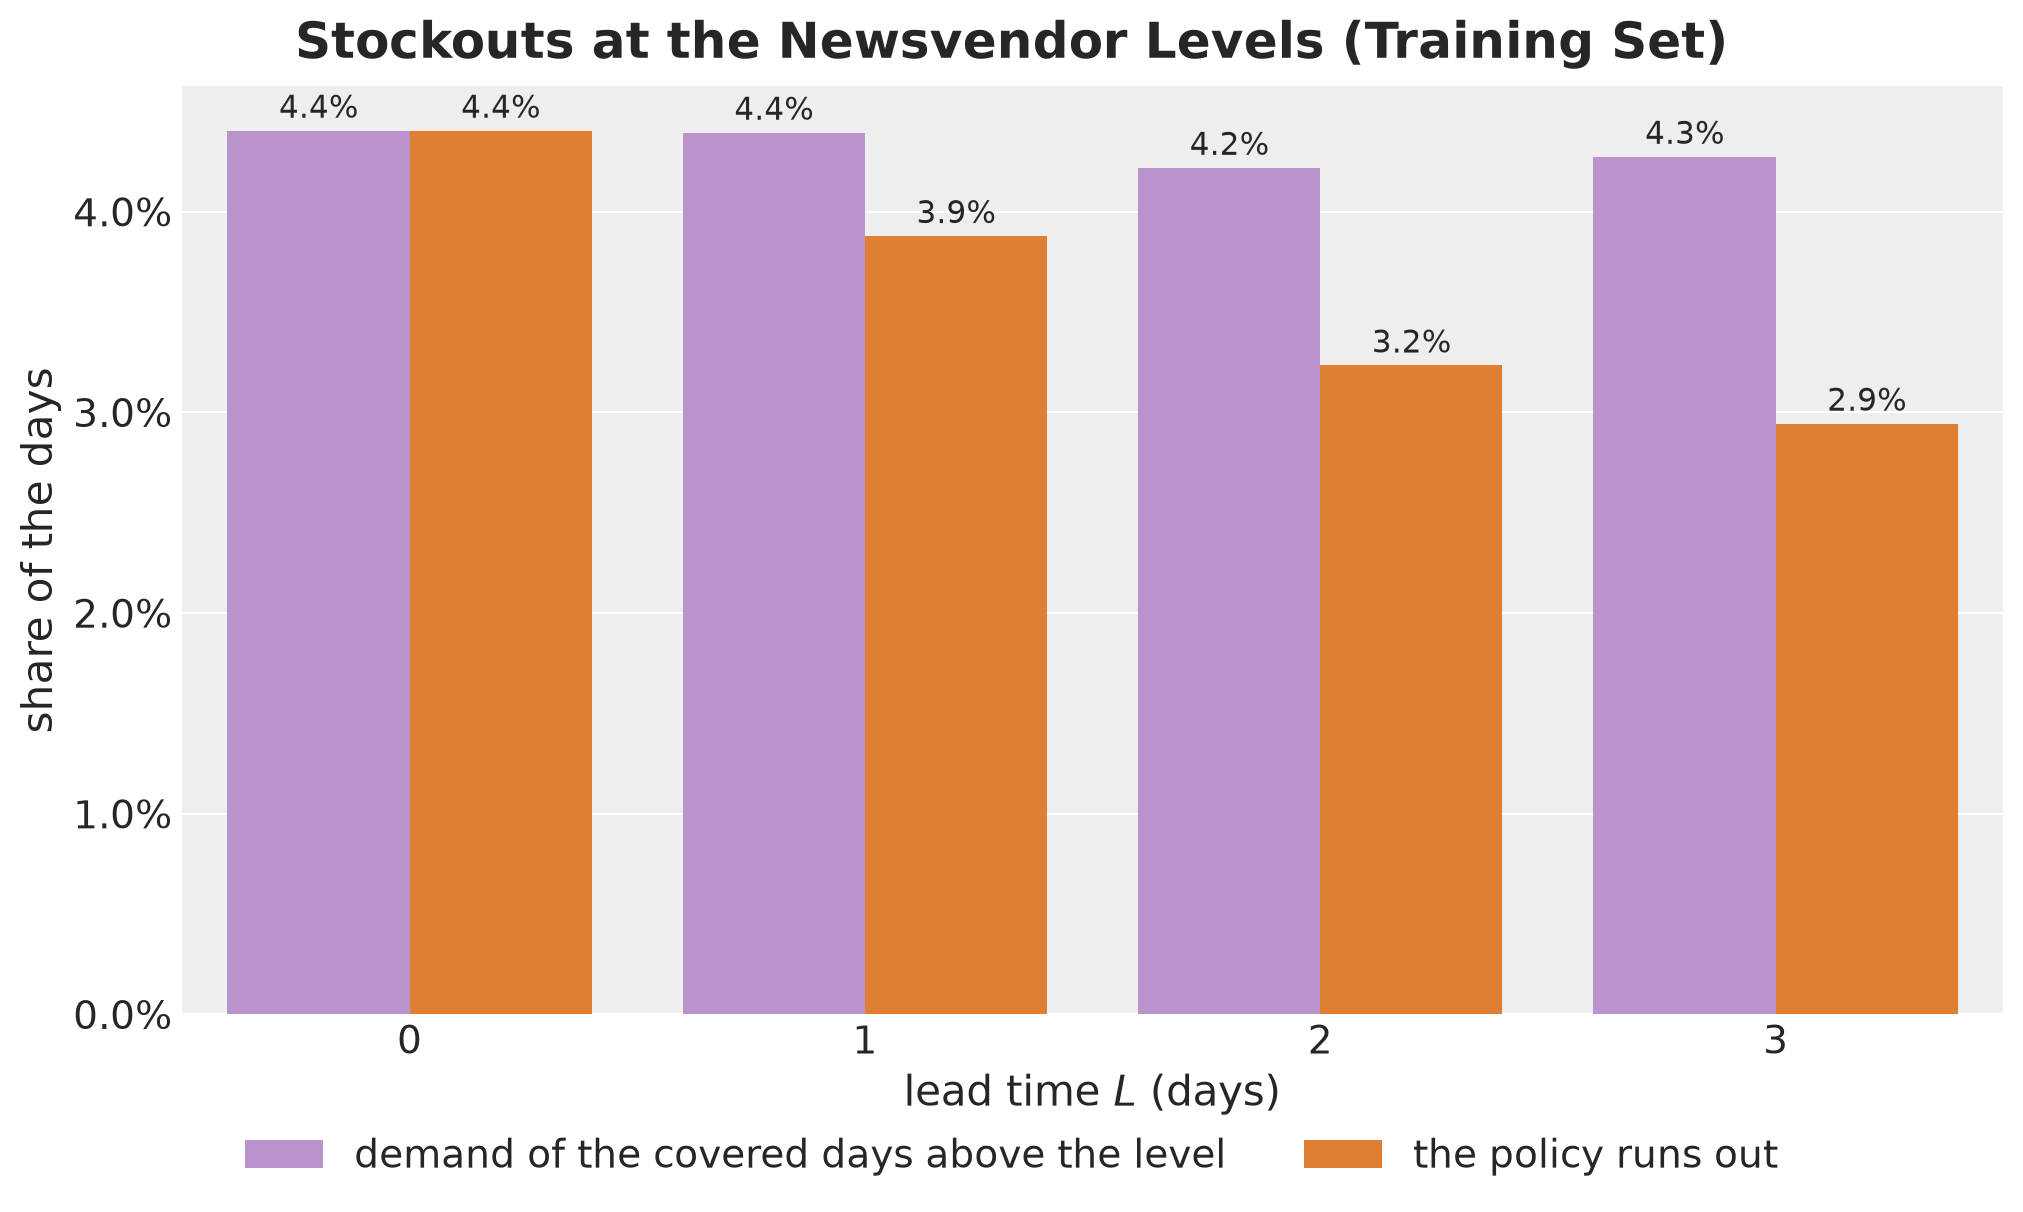

In [37]:
STOCKOUT_TOL = 1e-3  # lost sales below this are rounding noise of the solver


def stockouts(simulation: Simulation, lead_time: int) -> Bool[Array, "scenarios days"]:
    """The days of the cost window with lost sales above the tolerance."""
    return simulation.lost_sales[:, lead_time:] > STOCKOUT_TOL


def demand_above_level(
    scenarios: Scenarios, lead_time: int
) -> Bool[Array, "scenarios horizon"]:
    """Whether the demand of the days t, ..., t + L is above the level of day t."""
    cumulative = jnp.cumsum(jnp.pad(scenarios.demand, ((0, 0), (1, 0))), axis=1)
    first = jnp.arange(setup.horizon)
    totals = cumulative[:, first + lead_time + 1] - cumulative[:, first]
    return totals > scenarios.forecast.level[:, : setup.horizon]


class Event(StrEnum):
    """Names of the two events of a day whose shares we compare."""

    DEMAND_ABOVE = "demand of the covered days above the level"
    RUNS_OUT = "the policy runs out"


rows = []

for lead_time in setup.lead_times:
    demand_above = demand_above_level(
        scenarios_for(ScenarioSet.TRAINING, lead_time, ForecastSource.DAY_ONE),
        lead_time,
    )
    runs_out = stockouts(
        evaluate(
            policies[lead_time, PolicyName.DAY_ONE], ScenarioSet.TRAINING, lead_time
        ),
        lead_time,
    )
    # the policy runs out on day t + L only if the demand of the days t, ..., t + L
    # is above the level of day t
    assert (demand_above | ~runs_out).all()
    rows += [
        {
            "lead time": lead_time,
            "event": str(Event.DEMAND_ABOVE),
            "share": float(demand_above.mean()),
        },
        {
            "lead time": lead_time,
            "event": str(Event.RUNS_OUT),
            "share": float(runs_out.mean()),
        },
    ]

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=pl.DataFrame(rows),
    x="lead time",
    y="share",
    hue="event",
    hue_order=list(Event),
    palette={
        Event.DEMAND_ABOVE: "C8",
        Event.RUNS_OUT: POLICY_COLORS[PolicyName.DAY_ONE],
    },
    errorbar=None,
    ax=ax,
)

for container in ax.containers:
    ax.bar_label(container, fmt="{:.1%}", fontsize=11, padding=2)

ax.get_legend().remove()
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
ax.set(xlabel="lead time $L$ (days)", ylabel="share of the days")
fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=2)
fig.suptitle(
    f"Stockouts at the Newsvendor Levels ({ScenarioSet.TRAINING.title()})",
    fontsize=18,
    fontweight="bold",
);

For $L = 0$ the two shares are the same, $4.4\%$ of the days. This is a little below $h / (p + h) = 4.8\%$, the share of the days that the fractile leaves above the level. The level is a quantile of $4{,}000$ forecast paths and the training scenarios are another sample, so the coverage is not exact.

With a lead time the demand is above the level about as often, on $4.2\%$ to $4.4\%$ of the days, but the policy runs out less and less: on $3.9\%$, $3.2\%$ and $2.9\%$ of the days for $L = 1, 2, 3$. The assertion checks the direction on every day: the policy never runs out on a day whose covered demand stays at or below the level. So with a lead time the policy has more stock on day $t + L$ than its level assumes, and we can lower the level.

Here is a second observation. The lost sales $U_{t+L}$ of day $t + L$ are in the sum of each of the next $L$ days. In other words, a unit that we sell on day $t + L$ is missing on those days, until the order that replaces it arrives. A missing unit saves the holding cost $h$ on a day with stock left over, and it costs the margin $p$ on a day on which we run out again. When the margin that it costs is larger than the holding cost that it saves, the net cost of a lost sale is below $p$, and the best level runs out more often than $h / (p + h)$. We see in the *Stock and Stockouts* section that the trained policies do. Both effects can lower the best level below the newsvendor level, as in the experiments of Huh et al. (2009) that we recalled in the *Evidence From the Literature* section.

Next, we train one offset per day for the levels of each forecast. Before each training, the assertion checks that with zero offsets every ordering day has a positive order in more than half of the training scenarios, so every offset has a gradient at the start.

In [38]:
def train_base_stock(
    lead_time: int,
    config: InventoryConfig,
    source: ForecastSource,
    tail_weight: float = 0.0,
    day_one: Forecast = forecast_day_one,
) -> TrainedPolicy:
    """Train the offsets of the base-stock policy from zero."""
    scenarios = scenarios_for(ScenarioSet.TRAINING, lead_time, source, day_one)
    result = train_jit(
        NO_KEY,
        base_stock,
        jnp.zeros(setup.horizon),
        scenarios,
        scenarios,  # 15 parameters: we keep the best iterate on the training set
        initial_state(lead_time),
        config,
        lead_time=lead_time,
        tail_weight=tail_weight,
        train_config=FULL_BATCH,
    )
    return TrainedPolicy(base_stock, result.params, source)


# the forecast that each trained base-stock policy reads
TRAINED_BASE_STOCK = {
    PolicyName.DAY_ONE_TRAINED: ForecastSource.DAY_ONE,
    PolicyName.WEEKLY_TRAINED: ForecastSource.WEEKLY,
}

for lead_time in setup.lead_times:
    for name, source in TRAINED_BASE_STOCK.items():
        # with zero offsets every ordering day has a positive order in more than half
        # of the training scenarios, so every offset has a gradient at the start
        orders_start = evaluate(
            TrainedPolicy(base_stock, no_offsets, source),
            ScenarioSet.TRAINING,
            lead_time,
        ).orders[:, : setup.horizon]
        assert float((orders_start > 0).mean(axis=0).min()) > 0.5
        policies[lead_time, name] = train_base_stock(lead_time, config, source)

Next, we look at the trained offsets. The figure shows the offset of every ordering day for the two trained base-stock policies, with one line per lead time. The lines go from dark to light as the lead time grows.

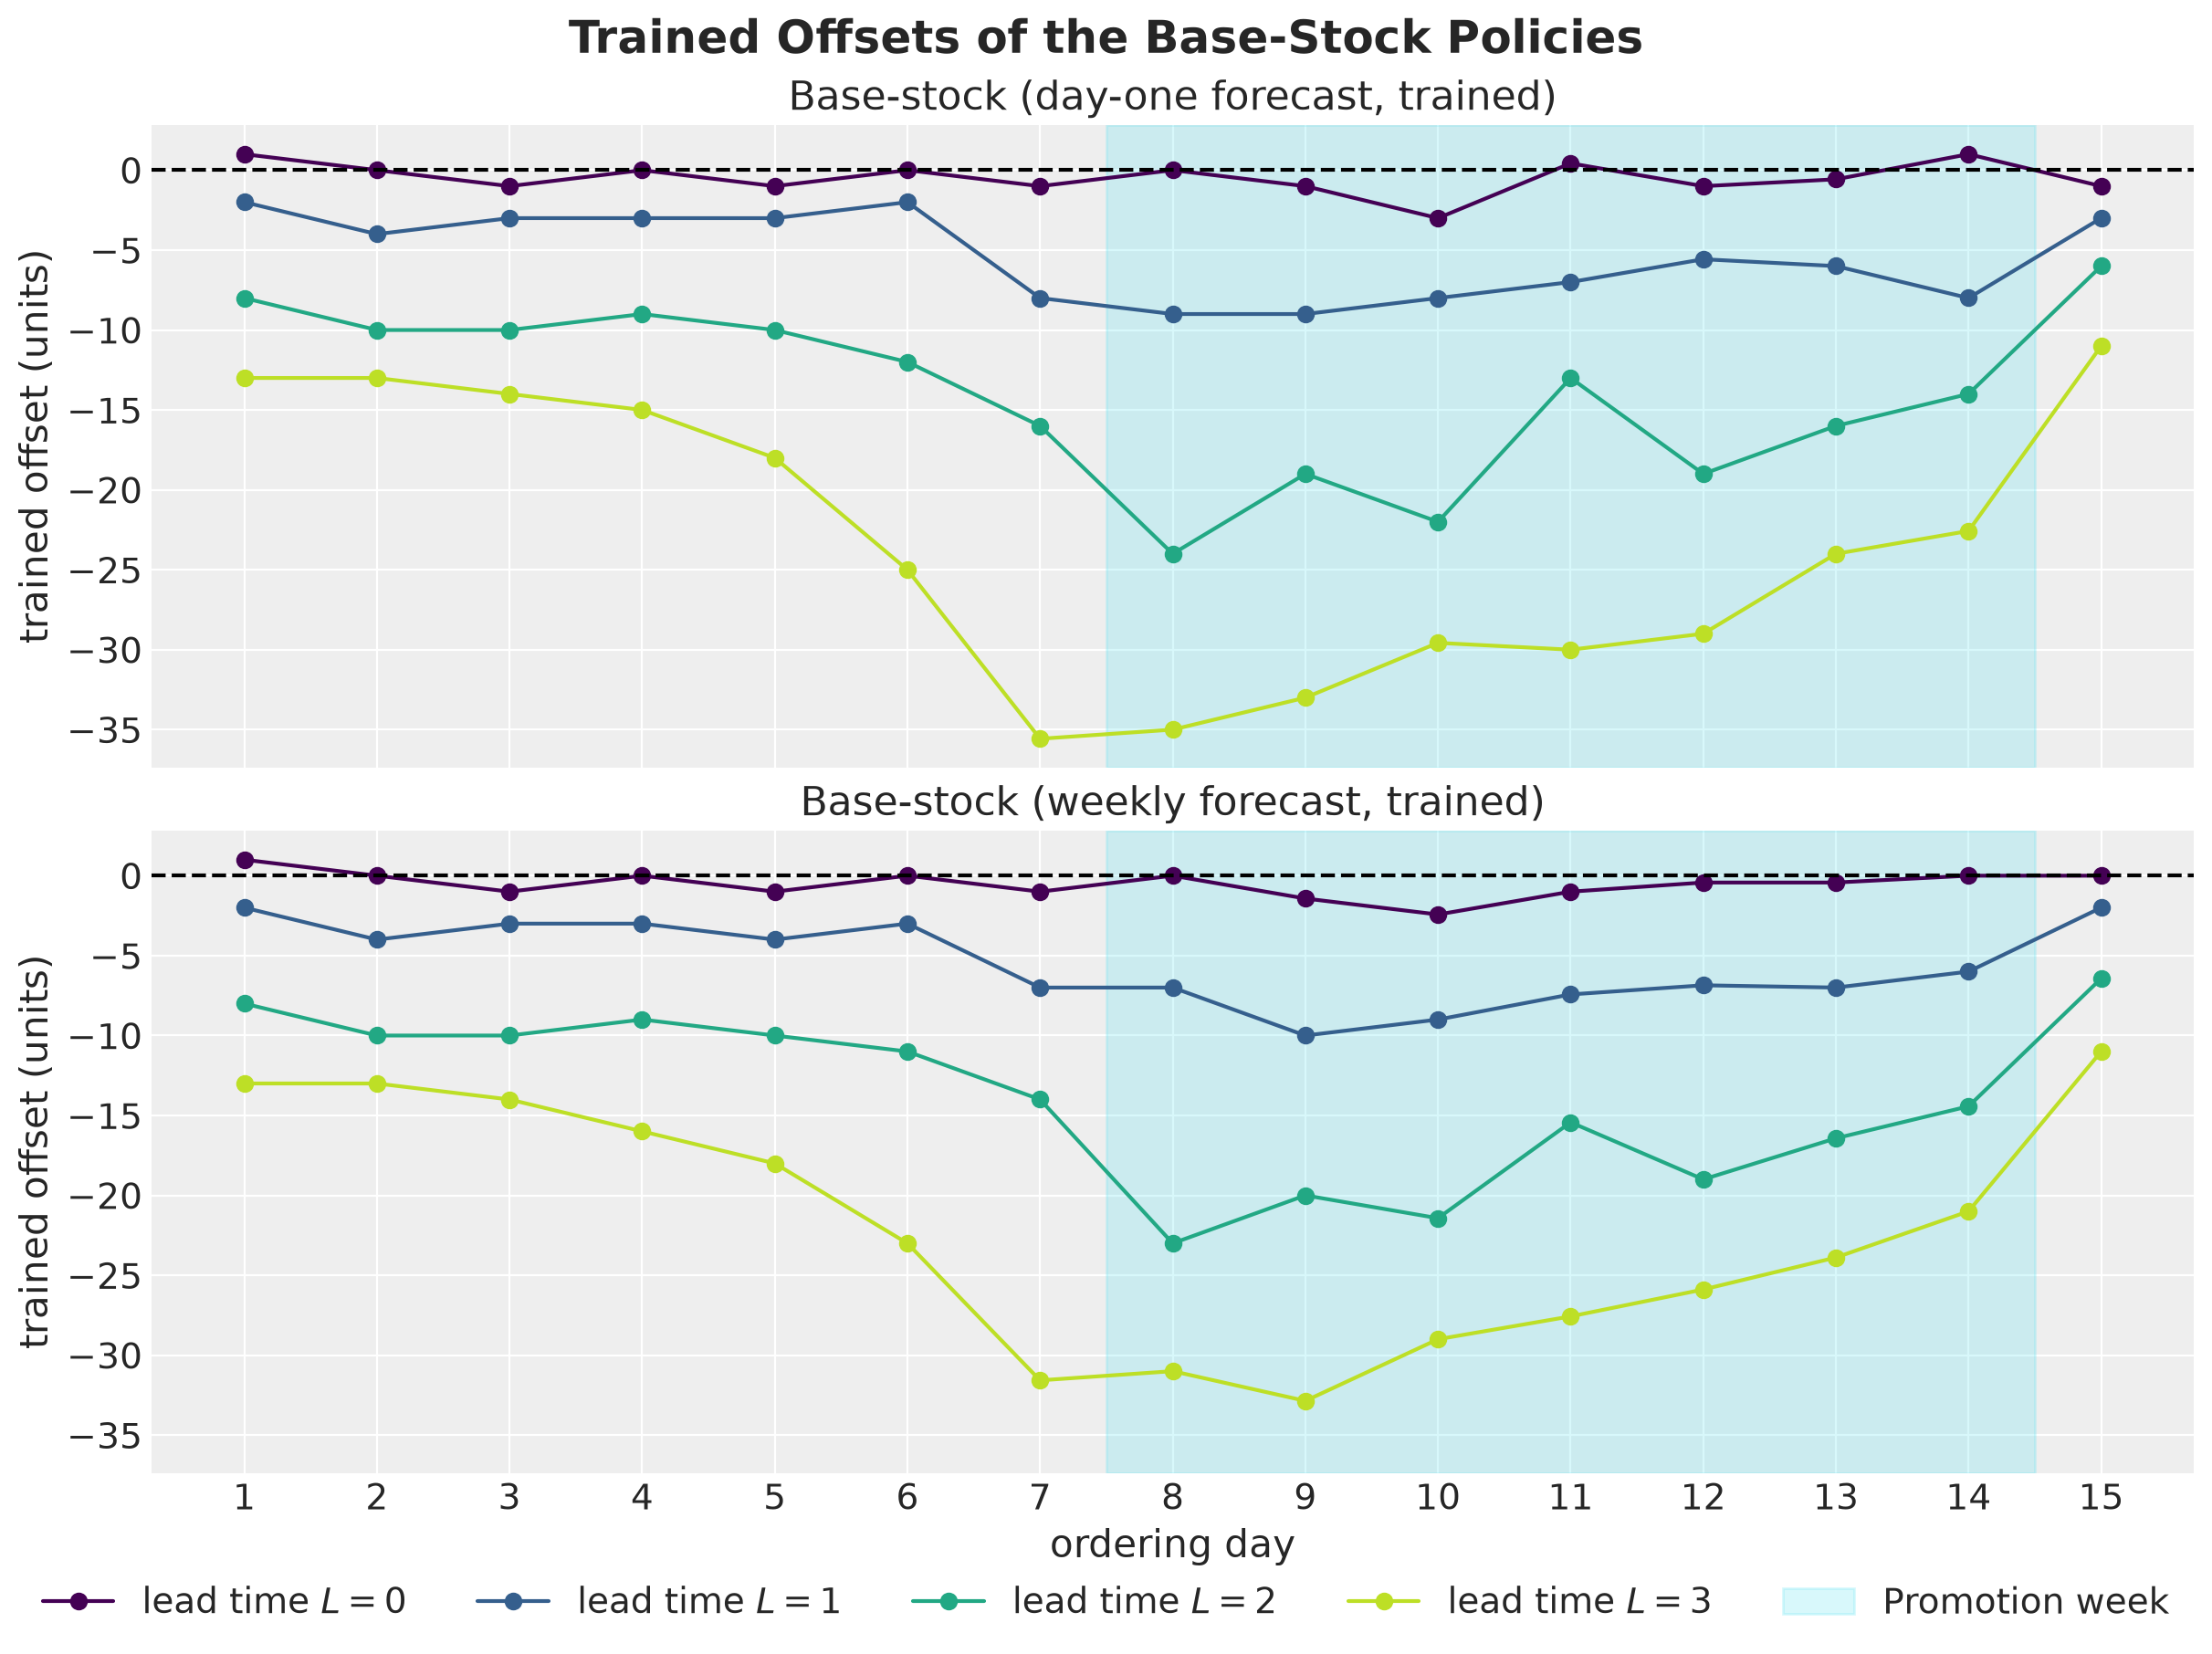

In [39]:
def sequential_colors(num: int) -> list[tuple[float, ...]]:
    """`num` colors of the viridis palette for an ordered variable, dark to light."""
    return [plt.colormaps["viridis"](0.9 * k / max(num - 1, 1)) for k in range(num)]


fig, axes = plt.subplots(
    nrows=2, figsize=(12, 9), sharex=True, sharey=True, layout="constrained"
)

for ax, name in zip(axes, TRAINED_BASE_STOCK, strict=True):
    for lead_time, color in zip(
        setup.lead_times, sequential_colors(len(setup.lead_times)), strict=True
    ):
        ax.plot(
            ordering_days,
            policies[lead_time, name].params,
            "o-",
            color=color,
            label=f"lead time $L = {lead_time}$",
        )

    ax.axhline(0.0, color="black", linestyle="--")
    shade_promotion(ax)
    ax.set(title=name, ylabel="trained offset (units)", xticks=ordering_days)

axes[-1].set(xlabel="ordering day")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=5)
fig.suptitle(
    "Trained Offsets of the Base-Stock Policies", fontsize=18, fontweight="bold"
);

The offsets stay near zero without a lead time and are negative with one, for both forecasts.

- **No lead time.** For $L = 0$ the offsets stay within $3$ units of zero. Without a lead time we can order up to the level of the day on every day. As long as the stock left over is below that level, the days are separate single-day problems, and the newsvendor levels already solve them. Recall that in the first post the myopic newsvendor *plan* cost $11\%$ more than the expected cost plan. A plan cannot react to the stock left over and a policy can, which is why the same rule works here.
- **Positive lead time.** For $L \geq 1$ the offsets are negative on every ordering day, and their size grows with the lead time. With the day-one levels the lowest offsets are $-9$, $-24$ and $-36$ units for $L = 1, 2, 3$, on days whose orders cover promotion days.
- **Weekly forecast.** The two trained policies share the levels of the first week, and up to day $3$ they have the same offsets. From day $8$ on the offsets of the weekly levels are smaller in size for $L = 3$ on most days, while for $L = 1, 2$ they are larger on some days and smaller on others. Their lowest values are $-10$, $-23$ and $-33$ units, on days $8$ and $9$.

This supports the observation of the *Offset Definition* section. The levels cover the demand about as often as the forecast says at every lead time, the offsets stay near zero without a lead time, and they are negative with one. So the offsets correct the base-stock rule under lost sales, and they do not repair the forecast.

### Neural Training

Recall from the *Neural* section why we add a network to the base-stock policy. The policy sees the stock on hand and the pipeline only through their sum, while with lost sales it matters when each order arrives. In addition, the forecast is updated only on day $8$, and the demand since the last forecast tells us whether the path runs above or below it.

The neural policy adds a correction to the level of `Base-stock (weekly forecast, trained)`. The correction is a multilayer perceptron with two hidden layers of $32$ units, which we build with [Flax NNX](https://flax.readthedocs.io/en/latest/nnx_basics.html) as the module `MLP`. Its last layer starts with zero weights and a zero bias, so a new network returns a correction of zero. Let's check this on a network with five inputs.

In [40]:
DEMAND_SCALE = float(data.mean())  # mean daily demand of the history
HIDDEN_UNITS = 32


class MLP(nnx.Module):
    """Multilayer perceptron with two hidden layers and GELU activations."""

    def __init__(self, num_features: int, rngs: nnx.Rngs) -> None:
        self.hidden_1 = nnx.Linear(num_features, HIDDEN_UNITS, rngs=rngs)
        self.hidden_2 = nnx.Linear(HIDDEN_UNITS, HIDDEN_UNITS, rngs=rngs)
        # zero weights and bias: the network starts with no correction
        self.output = nnx.Linear(
            HIDDEN_UNITS, 1, kernel_init=nnx.initializers.zeros, rngs=rngs
        )

    def __call__(self, x: Float[Array, " features"]) -> Float[Array, "1"]:
        x = nnx.gelu(self.hidden_1(x))
        x = nnx.gelu(self.hidden_2(x))
        return self.output(x)


network_example = MLP(5, nnx.Rngs(0))
rng_key, key_example = random.split(rng_key)
{
    "parameters": sum(
        leaf.size for leaf in jax.tree.leaves(nnx.state(network_example, nnx.Param))
    ),
    "output": float(network_example(random.normal(key_example, (5,)))[0]),
}

{'parameters': 1281, 'output': 0.0}

A network with $5$ inputs has $1{,}281$ weights and biases, and it returns zero, as it should. The network of the policy reads the following features of the observation:

- **Stock.** The stock on hand and each order in the pipeline, divided by the mean daily demand $\bar{d}$ of the history. Recall that $\bar{d}$ brings the inputs and the output of the network to numbers of order one.
- **Promotion.** The promotion flags of the days $t, \dots, t + L$.
- **Day.** The day index $t - 1$ divided by $H$.
- **Forecast.** The newsvendor level and the mean of the total demand of the days $t, \dots, t + L$ under the latest weekly forecast, divided by $\bar{d}$.
- **Demand history.** The demand of the last $K = 7$ days, divided by $\bar{d}$. On days $1$ and $8$ all of these days are in the forecast, and on the other days some of them are not.

The policy keeps its own copy of the offsets, in units of $\bar{d}$, and trains them together with the network. The function `nnx.split` separates a network into its graph definition, the structure of the layers, and its state, the weights and the biases. The state is a PyTree, so the trainer updates it like the offsets, and the policy puts it back into the network with `nnx.merge`. The function `make_neural_policy` returns the policy, the correction, and a function `init` that returns the state of a new network for a random key. Let's build the policy for $L = 2$ and check that the correction of a new network is zero on the first day of a test scenario.

In [41]:
class NeuralPolicy(NamedTuple):
    """A neural base-stock policy for one lead time."""

    policy: Policy
    # what the network adds to the base-stock level of the day, in units
    correction: Callable[[PyTree, Observation], Float[Array, ""]]
    # the state of a new network, its weights and biases, for a random key
    init: Callable[[PRNGKeyArray], nnx.State]
    num_features: int


def make_neural_policy(lead_time: int) -> NeuralPolicy:
    """Trained base-stock levels plus a network that reads the observation."""

    def features(obs: Observation) -> Float[Array, " features"]:
        return jnp.concatenate(
            [
                obs.inventory[None] / DEMAND_SCALE,
                obs.pipeline / DEMAND_SCALE,
                # promotion flags of the days t, ..., t + lead_time
                jax.lax.dynamic_slice(promo_future, (obs.day,), (lead_time + 1,)),
                (obs.day / setup.horizon)[None],
                jnp.stack([obs.forecast.level, obs.forecast.mean]) / DEMAND_SCALE,
                obs.demand_history / DEMAND_SCALE,
            ]
        )

    # the number of features, from the observation of day one with any forecast
    forecast_shape = Forecast(jnp.asarray(0.0), jnp.asarray(0.0))
    observation = observe(
        initial_state(lead_time), jnp.asarray(0), forecast_shape, lead_time
    )
    num_features = features(observation).shape[0]
    # the structure of the network, without its weights and biases
    graphdef, _ = nnx.split(MLP(num_features, nnx.Rngs(0)))

    def init(key: PRNGKeyArray) -> nnx.State:
        _, state = nnx.split(MLP(num_features, nnx.Rngs(key)))
        return state

    def correction(params: PyTree, obs: Observation) -> Float[Array, ""]:
        network = nnx.merge(graphdef, params["net"])
        return DEMAND_SCALE * network(features(obs))[0]

    def policy(params: PyTree, obs: Observation) -> Float[Array, ""]:
        offset = DEMAND_SCALE * params["offsets"][obs.day]
        level = obs.forecast.level + offset + correction(params, obs)
        return jax.nn.relu(level - obs.position)

    return NeuralPolicy(policy, correction, init, num_features)


neural_example = make_neural_policy(LEAD_TIME_DETAIL)
scenarios_example = scenarios_for(
    ScenarioSet.FORECAST, LEAD_TIME_DETAIL, ForecastSource.WEEKLY
)
observation_example = observe(
    initial_state(LEAD_TIME_DETAIL),
    jnp.asarray(0),
    jax.tree.map(lambda leaf: leaf[0, 0], scenarios_example.forecast),
    LEAD_TIME_DETAIL,
)
rng_key, key_example = random.split(rng_key)
params_example = {
    "offsets": jnp.zeros(setup.horizon),
    "net": neural_example.init(key_example),
}
{
    "features": neural_example.num_features,
    "correction": float(neural_example.correction(params_example, observation_example)),
}

{'features': 15, 'correction': 0.0}

For $L = 2$ the network reads $15$ features, $1 + 1 + 3 + 1 + 2 + 7$ in the order of the list above, and a new network adds nothing to the level.

The function `train_neural` trains the neural policy of one lead time from three seeds at once, with `jax.vmap` over the seeds. Every seed starts from the trained offsets of `Base-stock (weekly forecast, trained)` and from a new network. It trains on random batches and keeps the seed with the lowest validation loss.

In [42]:
MINIBATCH = TrainConfig(num_steps=3_000, batch_size=256, learning_rate=3e-3)
NUM_SEEDS = 3


class NeuralTraining(NamedTuple):
    """The neural policy of the best seed and the validation loss of every seed."""

    trained: TrainedPolicy
    validation: Float[Array, "seeds evaluations"]


def train_neural(
    key: PRNGKeyArray,
    lead_time: int,
    config: InventoryConfig,
    offsets: Float[Array, " horizon"],
) -> NeuralTraining:
    """Train the neural policy from several seeds and keep the best on validation."""
    neural = make_neural_policy(lead_time)
    scenarios = (
        scenarios_for(ScenarioSet.TRAINING, lead_time, ForecastSource.WEEKLY),
        scenarios_for(ScenarioSet.VALIDATION, lead_time, ForecastSource.WEEKLY),
    )
    state = initial_state(lead_time)
    key_init, key_train = random.split(key)
    # one new network per seed, all with the same offsets
    params = jax.vmap(
        lambda key_seed: {
            "offsets": offsets / DEMAND_SCALE,
            "net": neural.init(key_seed),
        }
    )(random.split(key_init, NUM_SEEDS))
    train_seeds = jax.jit(
        jax.vmap(
            lambda key_seed, params_seed: train(
                key_seed,
                neural.policy,
                params_seed,
                *scenarios,
                state,
                config,
                lead_time,
                0.0,  # tail weight: we train the network for the expected loss
                MINIBATCH,
            )
        )
    )
    result = train_seeds(random.split(key_train, NUM_SEEDS), params)
    best_seed = int(result.validation.min(axis=1).argmin())
    best_params = jax.tree.map(lambda leaf: leaf[best_seed], result.params)
    return NeuralTraining(
        TrainedPolicy(neural.policy, best_params, ForecastSource.WEEKLY),
        result.validation,
    )

We train the neural policy for every lead time. The assertions check that before the first step every seed is `Base-stock (weekly forecast, trained)`: its validation loss is the validation loss of that policy.

In [43]:
%%time

validation: dict[int, Float[Array, "seeds evaluations"]] = {}

for lead_time in setup.lead_times:
    rng_key, key_neural = random.split(rng_key)
    policies[lead_time, PolicyName.NEURAL], validation[lead_time] = train_neural(
        key_neural,
        lead_time,
        config,
        policies[lead_time, PolicyName.WEEKLY_TRAINED].params,
    )
    loss_base_stock = evaluate(
        policies[lead_time, PolicyName.WEEKLY_TRAINED],
        ScenarioSet.VALIDATION,
        lead_time,
    ).loss.mean()
    assert jnp.allclose(validation[lead_time][:, 0], loss_base_stock, atol=0.01)

CPU times: user 7min 6s, sys: 1min 29s, total: 8min 35s
Wall time: 2min 27s


Let's look at the expected loss on the validation set during the training. Every line is one seed, and the dashed line is the validation loss of `Base-stock (weekly forecast, trained)`, where every seed starts.

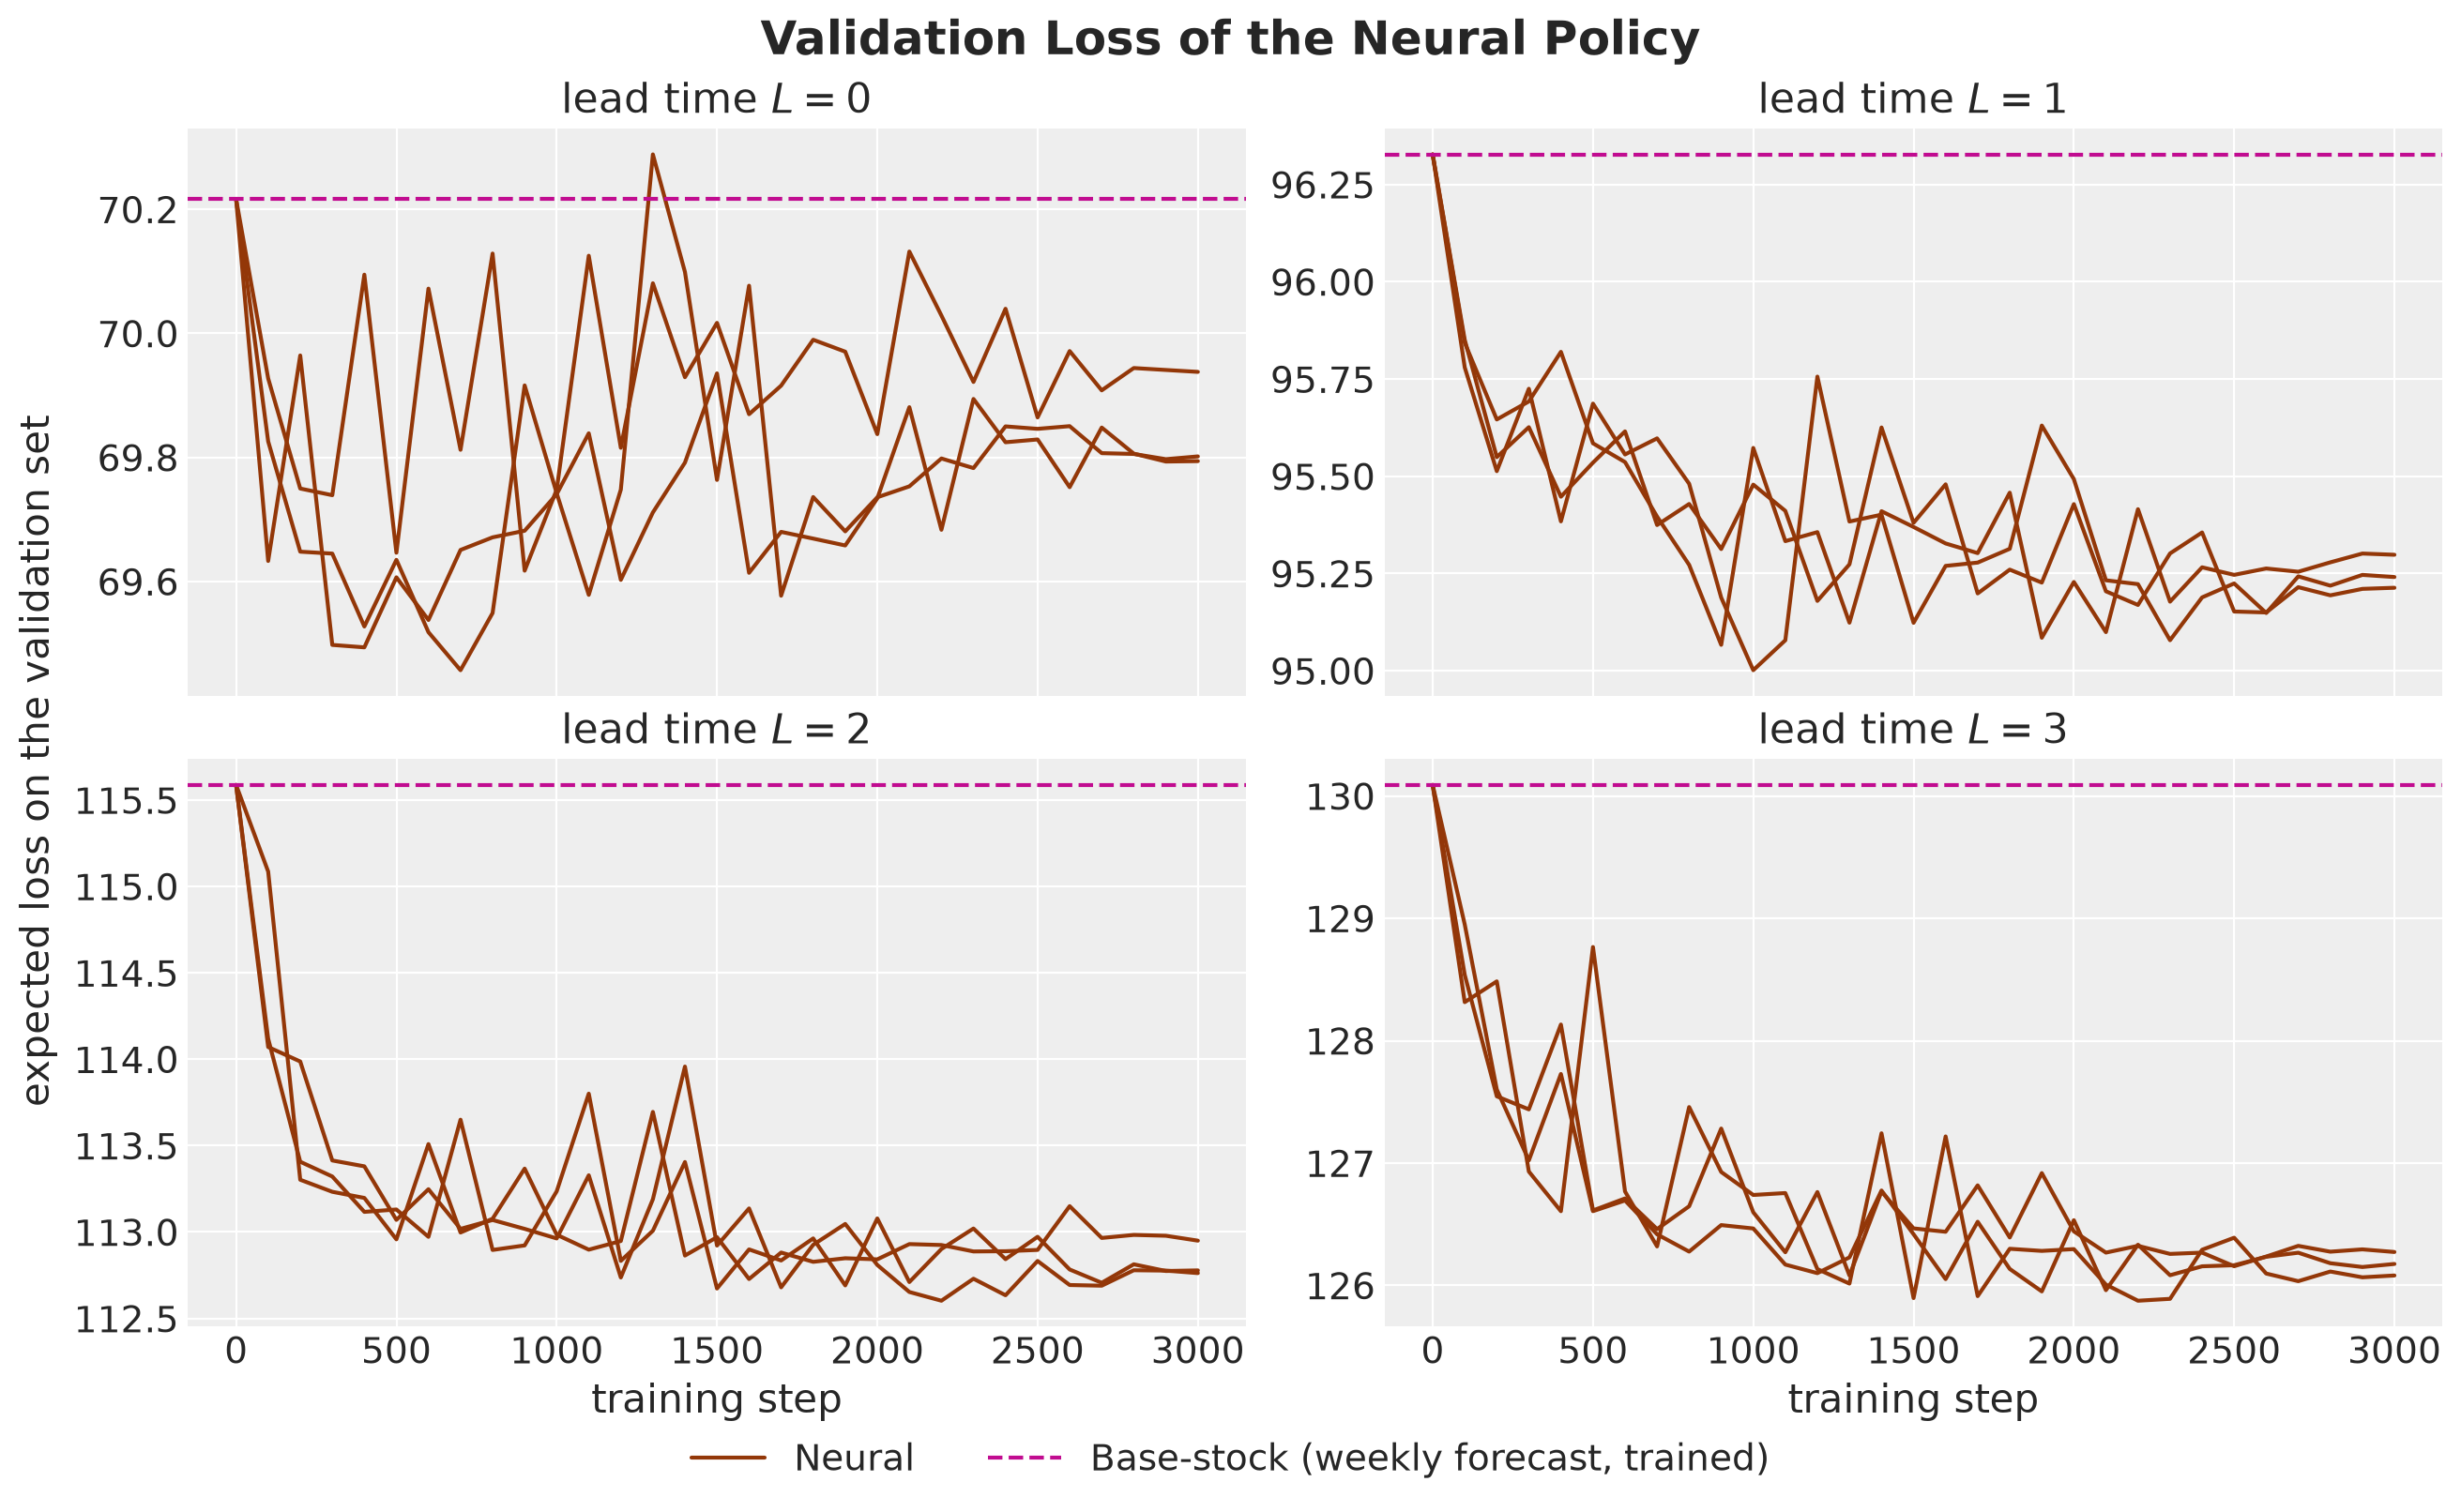

In [44]:
evaluation_steps = MINIBATCH.eval_every * jnp.arange(
    MINIBATCH.num_steps // MINIBATCH.eval_every + 1
)

fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(13, 8), sharex=True, layout="constrained"
)

for ax, lead_time in zip(axes.flat, setup.lead_times, strict=True):
    lines = ax.plot(
        evaluation_steps,
        validation[lead_time].T,
        color=POLICY_COLORS[PolicyName.NEURAL],
    )
    lines[0].set_label(PolicyName.NEURAL)
    ax.axhline(
        float(validation[lead_time][0, 0]),
        color=POLICY_COLORS[PolicyName.WEEKLY_TRAINED],
        linestyle="--",
        label=PolicyName.WEEKLY_TRAINED,
    )
    ax.set(title=f"lead time $L = {lead_time}$")

for ax in axes[-1]:
    ax.set(xlabel="training step")

fig.supylabel(
    "expected loss on the validation set", fontsize=plt.rcParams["axes.labelsize"]
)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
fig.suptitle("Validation Loss of the Neural Policy", fontsize=18, fontweight="bold");

Let's look at the curves by lead time.

- **No lead time.** For $L = 0$ the validation loss stays within $0.8$ of its start, and the three seeds end a little below it. The base-stock policy leaves little to correct here.
- **Positive lead time.** For $L \geq 1$ about half or more of the fall comes in the first $500$ steps, and the curves are noisy after that. For example, one seed for $L = 3$ jumps up by about $2$ at step $500$ and is back down at step $600$. The best values are about $1.3$, $3.0$ and $4.2$ below the start for $L = 1, 2, 3$, and the three seeds end within $0.2$ of each other.

These gains are small next to the losses themselves, which are between $69$ and $130$. We measure them on the test sets in the *Out of Sample Evaluation* section.

Before we move on, we check on a trained policy that it does not use the demand of the day on which it orders. Recall the validation scenarios of the forecast check, with $50$ more units of demand from day $8$ on, and their weekly forecast, which is the same as before. The orders of the neural policy for $L = 2$ must be the same up to and including day $8$, and differ on day $9$.

In [45]:
num_days_detail = setup.horizon + LEAD_TIME_DETAIL
scenarios_changed = Scenarios(
    demand_val.at[:, CHANGED_FROM:num_days_detail].add(50.0)[:, :num_days_detail],
    jax.tree.map(
        lambda leaf: leaf[:, :num_days_detail, lead_index_detail], forecast_changed
    ),
)
orders_original = evaluate(
    policies[LEAD_TIME_DETAIL, PolicyName.NEURAL],
    ScenarioSet.VALIDATION,
    LEAD_TIME_DETAIL,
).orders
orders_changed = simulate_scenarios_jit(
    *policies[LEAD_TIME_DETAIL, PolicyName.NEURAL][:2],
    scenarios_changed,
    initial_state(LEAD_TIME_DETAIL),
    config,
    LEAD_TIME_DETAIL,
).orders
assert jnp.array_equal(
    orders_original[:, : CHANGED_FROM + 1], orders_changed[:, : CHANGED_FROM + 1]
)
assert not jnp.array_equal(
    orders_original[:, CHANGED_FROM + 1], orders_changed[:, CHANGED_FROM + 1]
)

The orders are the same up to the day of the change and differ on the day after it, as expected.

Now that we have trained all the policies, let's score them on the test sets.

## Out of Sample Evaluation

We score every policy on the two test sets, on all $3{,}000$ scenarios of each. We also simulate the policies on the training set, to see how much of a gain is left on new scenarios. We record five scores. The stockout scores count only the days of the cost window, with the tolerance of the *Base-Stock Training* section.

- **Expected loss.** The mean of the loss over the scenarios.
- **CVaR of the loss.** The mean of the worst $5\%$ of the scenario losses. We look at it in the *Tail Risk* section.
- **Stockout probability per day.** The fraction of scenario and day pairs with a lost sale.
- **Probability of a stockout in the cost window.** The fraction of scenarios with at least one lost sale.
- **Units ordered.** The mean over the scenarios of the sum of the orders.

The function `summarize` computes them for one policy on one scenario set. We run every policy on the three sets and collect the scores in one table.

In [46]:
class Metric(StrEnum):
    """Names of the scores."""

    EXPECTED_LOSS = "expected loss"
    CVAR = f"CVaR of loss (worst {ALPHA:.0%})"
    STOCKOUT = "stockout probability per day"
    WINDOW = "probability of a stockout in the cost window"
    ORDERED = "units ordered"


def summarize(simulation: Simulation, lead_time: int) -> dict[Metric, float]:
    """Scores of one policy over a set of scenarios."""
    stockout = stockouts(simulation, lead_time)
    return {
        Metric.EXPECTED_LOSS: float(simulation.loss.mean()),
        Metric.CVAR: float(cvar(simulation.loss)),
        Metric.STOCKOUT: float(stockout.mean()),
        Metric.WINDOW: float(stockout.any(axis=1).mean()),
        Metric.ORDERED: float(simulation.orders.sum(axis=1).mean()),
    }


EVALUATION_SETS = [ScenarioSet.TRAINING, *TEST_SETS]
simulations: dict[tuple[ScenarioSet, int, PolicyName], Simulation] = {
    (scenario_set, lead_time, name): evaluate(trained, scenario_set, lead_time)
    for scenario_set in EVALUATION_SETS
    for (lead_time, name), trained in policies.items()
}

results = pl.DataFrame(
    [
        {
            "scenario set": str(scenario_set),
            "lead time": lead_time,
            "policy": str(name),
            **summarize(simulation, lead_time),
        }
        for (scenario_set, lead_time, name), simulation in simulations.items()
    ]
)
results.filter(pl.col("scenario set") == ScenarioSet.FORECAST).pivot(
    on="lead time", index="policy", values=Metric.EXPECTED_LOSS
)

policy,0,1,2,3
str,f64,f64,f64,f64
"""Fixed plan""",144.0,154.5,163.2,170.6
"""Base-stock (day-one forecast)""",70.6,97.8,119.5,138.4
"""Base-stock (day-one forecast, …",70.7,97.5,116.5,131.1
"""Base-stock (weekly forecast, t…",70.3,96.5,115.3,129.9
"""Neural""",69.6,95.4,112.9,126.6


The table shows the expected loss on the forecast test set, one column per lead time. In every column the loss falls, or stays about the same, from one policy to the next, in the order in which we introduced them.

### Expected Loss

Let's start with the first question: how much of the expected loss of the fixed plan do we remove when the order of each day depends on the stock? The next figure shows the expected loss of the five policies on each test set, by lead time.

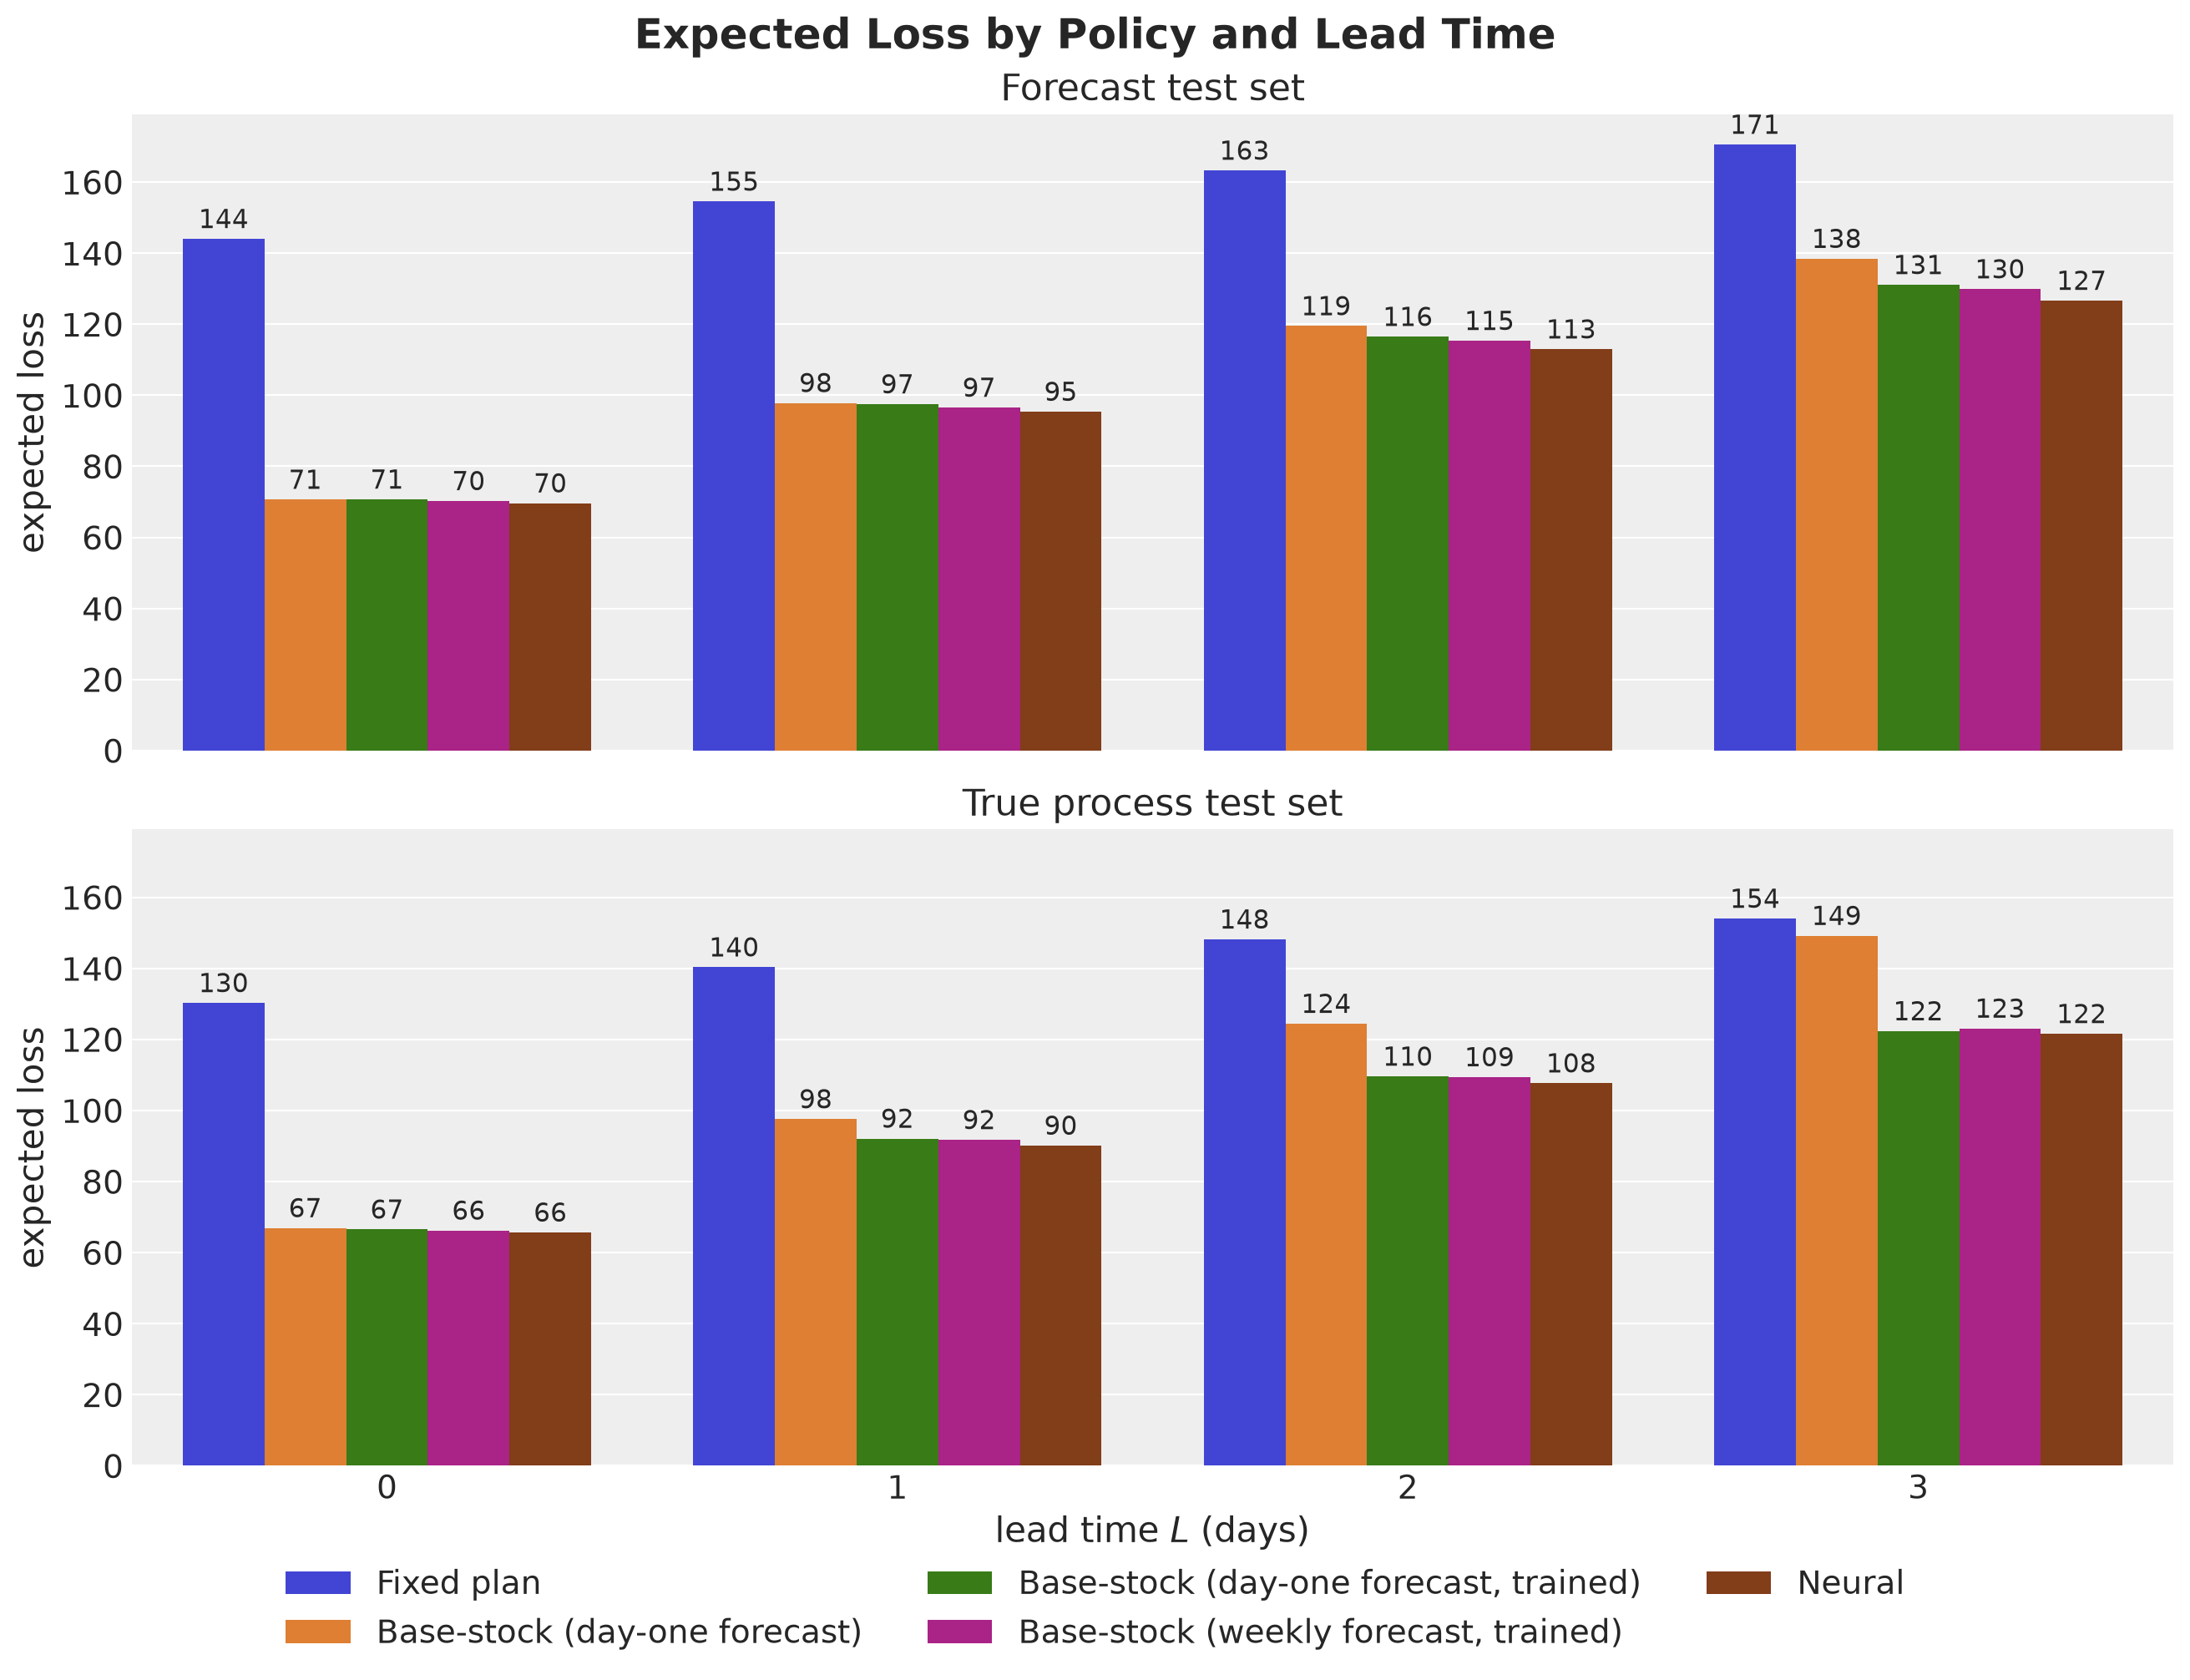

In [47]:
fig, axes = plt.subplots(
    nrows=2, figsize=(13, 10), sharex=True, sharey=True, layout="constrained"
)

for ax, test_set in zip(axes, TEST_SETS, strict=True):
    sns.barplot(
        data=results.filter(pl.col("scenario set") == test_set),
        x="lead time",
        y=Metric.EXPECTED_LOSS,
        hue="policy",
        hue_order=list(PolicyName),
        palette=POLICY_COLORS,
        ax=ax,
    )

    for container in ax.containers:
        ax.bar_label(container, fmt="{:.0f}", fontsize=11, padding=2)

    ax.get_legend().remove()
    ax.set(title=test_set.capitalize(), xlabel="", ylabel=Metric.EXPECTED_LOSS)

axes[-1].set(xlabel="lead time $L$ (days)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle("Expected Loss by Policy and Lead Time", fontsize=18, fontweight="bold");

Let's read the upper panel, the forecast test set, first.

- **Fixed plan.** The expected loss is $144$ for $L = 0$ and $171$ for $L = 3$. For $L = 0$ this is the expected cost plan of the first post.
- **Base-stock (day-one forecast).** With no lead time the expected loss is $71$, about half of the loss of the fixed plan, and we did not need an optimizer. For $L = 3$ it is $138$, about $19\%$ below the fixed plan.
- **Base-stock (day-one forecast, trained).** Training the offsets changes nothing for $L = 0$, and for $L = 1$ its gain of $0.4$ is within its Monte Carlo error. It lowers the expected loss by $3$ for $L = 2$ and by $7$ for $L = 3$.
- **Base-stock (weekly forecast, trained).** The update of day $8$ lowers the expected loss by $0.4$ for $L = 0$ and by about $1$ for $L \geq 1$.
- **Neural.** The network lowers the expected loss by a further $0.6$ to $3.2$.

On the true process test set the five policies keep the same order, except for $L = 3$, where `Base-stock (weekly forecast, trained)` is $0.7$ above `Base-stock (day-one forecast, trained)`, a difference larger than two Monte Carlo standard errors. The fixed plan and the trained policies have a lower loss there, and `Base-stock (day-one forecast)` a higher one for $L \geq 2$. For $L = 3$ its loss is only $3\%$ below the fixed plan, and training the offsets lowers it by $27$.

So here is the answer to the first question. With no lead time a policy that looks only at the stock removes about half of the expected loss of the fixed plan, on both test sets. The reduction is smaller for every extra day of lead time. Both policies below use only the forecast of day one:

- **Base-stock (day-one forecast).** The reductions are $51\%$, $37\%$, $27\%$ and $19\%$ for $L = 0, 1, 2, 3$ on the forecast test set, and about $49\%$, $30\%$, $16\%$ and $3\%$ on the true process test set.
- **Base-stock (day-one forecast, trained).** The reductions are $51\%$, $37\%$, $29\%$ and $23\%$ on the forecast test set, and about $49\%$, $34\%$, $26\%$ and $21\%$ on the true process test set.

The reductions differ because with a lead time `Base-stock (day-one forecast)` has more stock than its levels assume, as we saw in the *Base-Stock Training* section. On the true process test set the difference is larger, because the true process has less demand than the center of the forecast and the training lowers the levels. So the reductions of the trained policy on the forecast test set are the better measure of what the lead time costs.

The lead time matters because an order answers to what we observe today and arrives $L$ days later. The longer the lead time, the more days of demand an order has to cover without seeing them. [Goldberg et al. (2016)](https://arxiv.org/abs/1211.4063) study the limit of a very long lead time with stationary demand, and show that a constant order is then close to optimal:

> The main insight of our work is that when the lead time is very large, such a significant amount of randomness is injected into the system between when an order for more inventory is placed and when that order is received, that "being smart" algorithmically provides almost no benefit.

Our lead times are short and our demand has a promotion, so we are far from that limit. Still, the reduction moves in the same direction.

### Paired Differences

The three trained policies have expected losses within a few percent of each other, and each loss is an average over $3{,}000$ scenarios with its own Monte Carlo error. The policies run on the same scenarios, so for each pair of policies we take the difference of the two losses in every scenario. The mean of these differences equals the difference of the two means. But its standard error, which we compute from the differences, is much smaller than if the policies ran on separate scenarios, because the two losses of a scenario move together. We report the mean with two Monte Carlo standard errors.

Note that these error bars are about the mean. The spread of the difference across the scenarios is much wider, and we are interested in the expected loss. The training set has $5$ scenarios per posterior draw, which are not independent, so there we average the scenarios of a draw before we compute the standard error.

The function `plot_differences` draws such differences, one panel per pair of policies. Each panel shows the loss of one policy minus the loss of the next policy of our list, so a positive value means that the step lowers the loss:

- **Trained offsets.** We compare `Base-stock (day-one forecast)` with `Base-stock (day-one forecast, trained)`.
- **Weekly forecast.** We compare `Base-stock (day-one forecast, trained)` with `Base-stock (weekly forecast, trained)`.
- **Network.** We compare `Base-stock (weekly forecast, trained)` with `Neural`.

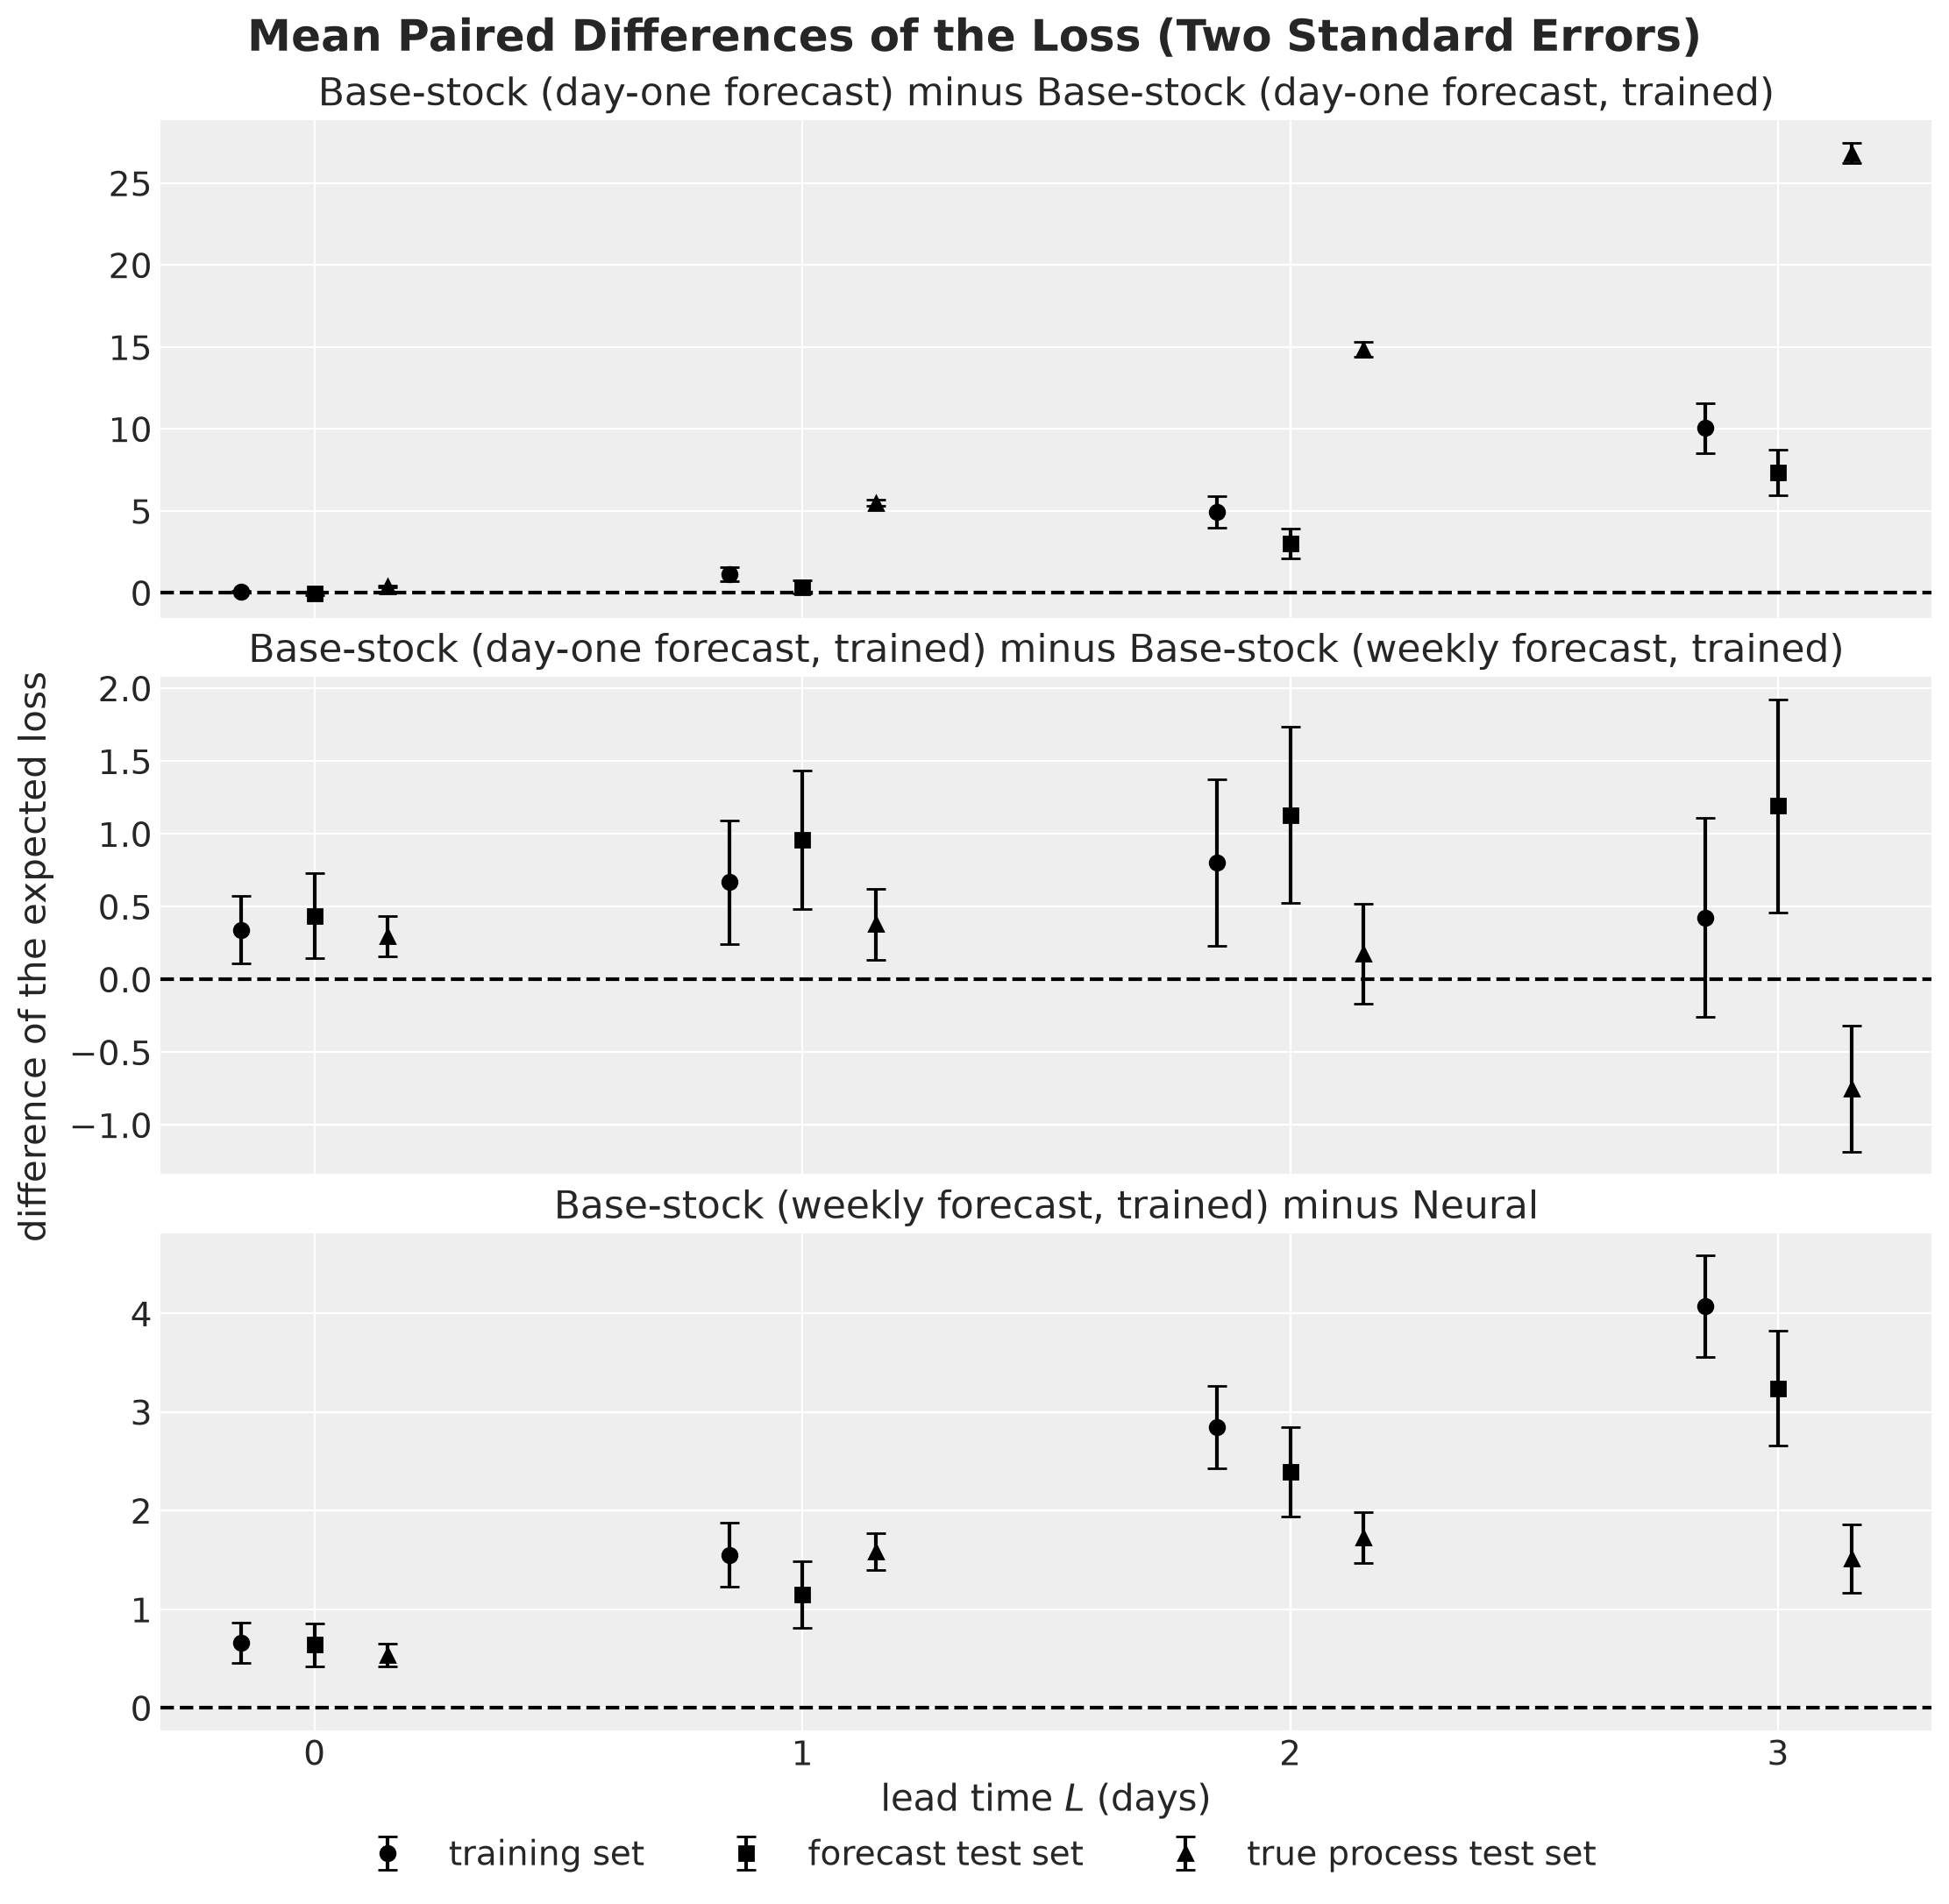

In [48]:
class Estimate(NamedTuple):
    """Mean of a paired difference with two Monte Carlo standard errors."""

    mean: float
    error: float


def mean_difference(
    difference: Float[Array, " scenarios"], num_paths: int = 1
) -> Estimate:
    """Mean and two standard errors of a difference over scenarios.

    With `num_paths` scenarios per posterior draw we average the scenarios of a
    draw first, since they are not independent.
    """
    by_draw = difference.reshape(num_paths, -1).mean(axis=0)
    return Estimate(
        float(by_draw.mean()), 2 * float(by_draw.std() / jnp.sqrt(by_draw.shape[0]))
    )


def paired_differences(
    first: PolicyName, second: PolicyName, scenario_set: ScenarioSet
) -> list[Estimate]:
    """Mean loss of `first` minus `second` on a scenario set, by lead time."""
    num_paths = PATHS_PER_DRAW if scenario_set == ScenarioSet.TRAINING else 1
    return [
        mean_difference(
            simulations[scenario_set, lead_time, first].loss
            - simulations[scenario_set, lead_time, second].loss,
            num_paths,
        )
        for lead_time in setup.lead_times
    ]


SET_MARKERS = {
    ScenarioSet.TRAINING: "o",
    ScenarioSet.FORECAST: "s",
    ScenarioSet.TRUE_PROCESS: "^",
}


def plot_differences(
    pairs: list[tuple[PolicyName, PolicyName]], scenario_sets: list[ScenarioSet]
) -> plt.Figure:
    """Mean paired difference of the loss by lead time, with two standard errors.

    One panel per pair (loss of the first policy minus loss of the second) and one
    marker per scenario set.
    """
    fig, axes = plt.subplots(
        nrows=len(pairs),
        figsize=(11, 3.6 * len(pairs)),
        sharex=True,
        layout="constrained",
    )
    offsets = jnp.linspace(-0.15, 0.15, len(scenario_sets))

    for ax, (first, second) in zip(axes, pairs, strict=True):
        for offset, scenario_set in zip(offsets, scenario_sets, strict=True):
            estimates = paired_differences(first, second, scenario_set)
            ax.errorbar(
                jnp.asarray(setup.lead_times) + offset,
                [estimate.mean for estimate in estimates],
                yerr=[estimate.error for estimate in estimates],
                fmt=SET_MARKERS[scenario_set],
                color="black",
                capsize=4,
                label=scenario_set,
            )

        ax.axhline(0.0, color="black", linestyle="--")
        ax.set(title=f"{first} minus {second}")

    axes[-1].set(xlabel="lead time $L$ (days)", xticks=setup.lead_times)
    fig.supylabel(
        "difference of the expected loss", fontsize=plt.rcParams["axes.labelsize"]
    )
    fig.legend(
        *axes[0].get_legend_handles_labels(),
        loc="outside lower center",
        ncol=len(scenario_sets),
    )
    return fig


class Step(StrEnum):
    """Names of the steps from one policy of our list to the next."""

    OFFSETS = "Trained offsets"
    WEEKLY = "Weekly forecast"
    NETWORK = "Network"


# the two policies that each step compares
STEP_PAIRS = {
    Step.OFFSETS: (PolicyName.DAY_ONE, PolicyName.DAY_ONE_TRAINED),
    Step.WEEKLY: (PolicyName.DAY_ONE_TRAINED, PolicyName.WEEKLY_TRAINED),
    Step.NETWORK: (PolicyName.WEEKLY_TRAINED, PolicyName.NEURAL),
}

fig = plot_differences(list(STEP_PAIRS.values()), EVALUATION_SETS)
fig.suptitle(
    "Mean Paired Differences of the Loss (Two Standard Errors)",
    fontsize=18,
    fontweight="bold",
);

In the first panel the gain grows with the lead time on every set. In the middle panel it stays below $2$. For $L \geq 1$ the error bars of the training set and of the forecast test set overlap, and on the true process test set the gain is below zero for $L = 3$. In the last panel the gain grows with the lead time on the training set and on the forecast test set. On the true process test set it stays between $1.5$ and $1.7$ for $L \geq 1$.

The next table shows the same means with two standard errors.

In [49]:
pl.DataFrame(
    [
        {
            "step": str(step),
            "scenario set": str(scenario_set),
            **{
                f"L = {lead_time}": f"{estimate.mean:.1f} ± {estimate.error:.1f}"
                for lead_time, estimate in zip(
                    setup.lead_times,
                    paired_differences(first, second, scenario_set),
                    strict=True,
                )
            },
        }
        for step, (first, second) in STEP_PAIRS.items()
        for scenario_set in EVALUATION_SETS
    ]
)

step,scenario set,L = 0,L = 1,L = 2,L = 3
str,str,str,str,str,str
"""Trained offsets""","""training set""","""0.1 ± 0.1""","""1.1 ± 0.4""","""4.9 ± 1.0""","""10.1 ± 1.5"""
"""Trained offsets""","""forecast test set""","""-0.1 ± 0.1""","""0.4 ± 0.4""","""3.0 ± 0.9""","""7.4 ± 1.4"""
"""Trained offsets""","""true process test set""","""0.4 ± 0.0""","""5.5 ± 0.2""","""14.9 ± 0.4""","""26.8 ± 0.6"""
"""Weekly forecast""","""training set""","""0.3 ± 0.2""","""0.7 ± 0.4""","""0.8 ± 0.6""","""0.4 ± 0.7"""
"""Weekly forecast""","""forecast test set""","""0.4 ± 0.3""","""1.0 ± 0.5""","""1.1 ± 0.6""","""1.2 ± 0.7"""
"""Weekly forecast""","""true process test set""","""0.3 ± 0.1""","""0.4 ± 0.2""","""0.2 ± 0.3""","""-0.7 ± 0.4"""
"""Network""","""training set""","""0.7 ± 0.2""","""1.6 ± 0.3""","""2.8 ± 0.4""","""4.1 ± 0.5"""
"""Network""","""forecast test set""","""0.6 ± 0.2""","""1.2 ± 0.3""","""2.4 ± 0.5""","""3.2 ± 0.6"""
"""Network""","""true process test set""","""0.5 ± 0.1""","""1.6 ± 0.2""","""1.7 ± 0.3""","""1.5 ± 0.3"""


The three steps behave differently:

- **Trained offsets.** The gain of the training is at most $0.4$ for $L = 0$ and grows with the lead time. On the forecast test set it is $0.4$, $3.0$ and $7.4$ for $L = 1, 2, 3$, and on the training set $1.1$, $4.9$ and $10.1$. For $L \geq 2$ about $60\%$ to $75\%$ of it carries over to new scenarios from the forecast. For $L = 1$ the gain on the forecast test set, $0.4 \pm 0.4$, is within two standard errors of zero. On the true process test set it is much larger: $5.5$, $14.9$ and $26.8$.
- **Weekly forecast.** With trained offsets on both sides, the update of day $8$ lowers the expected loss by $0.4$, $1.0$, $1.1$ and $1.2$ for $L = 0, 1, 2, 3$ on the forecast test set, and by $0.3$ to $0.8$ on the training set. On the forecast test set two standard errors are $0.5$ to $0.7$ for $L \geq 1$, so we cannot say that the gain changes from one of these lead times to the next. On the true process test set it is $0.2$ to $0.4$ for $L \leq 2$, and $-0.7 \pm 0.4$ for $L = 3$. For $L = 2$ the gain there, $0.2 \pm 0.3$, is within two standard errors of zero.
- **Network.** On the forecast test set the network lowers the expected loss by $0.6$, $1.2$, $2.4$ and $3.2$. On the training set the gains are between $0.7$ and $4.1$, larger than on the forecast test set for $L \geq 1$, so part of them does not carry over to new scenarios from the forecast. On the true process test set the gains are between $0.5$ and $1.7$, smaller than on the forecast test set for $L \geq 2$.

Recall that the training lowers the levels, and that the true process has less demand than the center of the forecast. So the true process test set is a favorable case for the trained offsets. In the *Gain by Expected Demand* section we see that they cost when the demand is high.

Now we can answer the remaining questions on the forecast test set:

- **Trained levels.** Training the offsets lowers the expected loss by $3.0$ for $L = 2$ and by $7.4$ for $L = 3$. For $L = 1$ its gain of $0.4 \pm 0.4$ is within two standard errors of zero, and it changes nothing for $L = 0$.
- **Weekly forecast.** With trained levels, the update after the first week lowers the expected loss by $1.0$ to $1.2$ for $L \geq 1$. This is much less than what the stock gives, and for $L \geq 2$ less than what the training gives. Another policy could gain more from the same update, since this one only adds one trained offset per day to the weekly levels. We train the offsets first, so that we compare the two forecasts between policies with trained levels. With the other order the two gains can be different, and only their sum is the same.
- **Network.** The network adds $0.6$ to $3.2$. It also reads the demand of the last $7$ days, which the weekly forecast has not seen on most days, so part of this gain can come from the more recent demand. We look at this in the *Demand Since the Update* section.

Finally, recall the experiments of Huh et al. (2009) from the *Evidence From the Literature* section. Their demand is stationary and ours has a promotion, so we only compare the sizes on the forecast test set:

- **Newsvendor level against trained level.** With the newsvendor levels, the base-stock policy costs about $0.4\%$, $3\%$ and $6\%$ more than with the trained levels for $L = 1, 2, 3$ (for example $7.4 / 131.1$ for $L = 3$). In their tables the newsvendor level of the margin $p + L h$, which is at least as high as ours, costs $2.1\%$ to $12.7\%$ more than the best level, and the difference also grows with the lead time.
- **Trained level against a more flexible rule.** The network gains about $1\%$ to $2.5\%$ of the loss of `Base-stock (weekly forecast, trained)` (for example $3.2 / 129.9$ for $L = 3$). In their tables the best base-stock policy costs $0.7\%$ to $3.0\%$ more than the optimal policy. The network is not the optimal policy, and it also reads the recent demand, so this comparison is loose.

So the direction of our gains agrees with their experiments, and the sizes are of the same order.

### Gain by Expected Demand

Where does each of the three steps lower the loss? We take the lead time $L = 2$ and group the scenarios of the forecast test set by the **expected demand** behind them: the expected total demand of the ordering days under the parameters and the level of the scenario, with the level held at its value on the last day of the history. We read it from the deterministic site `mean` of the demand model, with the increments of the days after the history fixed at zero. The function `log_expected_demand` sums this site over the ordering days.

We write it on the log scale and in standard deviations from its mean over the test draws, so zero is the center of the forecast. The output shows where the true process is on this scale. It also shows how far the posterior means of the `elasticity` and of the level on the last day of the history are from their true values, in posterior standard deviations.

In [50]:
def log_expected_demand(mean: Float[Array, "draws days 1"]) -> Float[Array, " draws"]:
    """Log of the expected total demand of the ordering days, from the `mean` site."""
    return jnp.log(mean[:, setup.t_obs :].sum(axis=(1, 2)))


covariates_horizon = covariates[: setup.t_obs + setup.horizon]
# no increments after the history: the level stays at its value on the last day
no_increments = jnp.zeros((setup.horizon, 1))
rng_key, key_mean_test, key_mean_true = random.split(rng_key, 3)
mean_test = Predictive(
    demand_model,
    posterior_samples={
        **posterior_of(draws_test),
        Site.DRIFT_FUTURE: jnp.broadcast_to(
            no_increments, (draws_test.shape[0], *no_increments.shape)
        ),
    },
    return_sites=[Site.MEAN],
    parallel=True,
)(key_mean_test, covariates_horizon, data)[Site.MEAN]
mean_true = Predictive(
    do(true_process, data={Site.DRIFT_FUTURE: no_increments}),
    num_samples=1,
    return_sites=[Site.MEAN],
)(key_mean_true, covariates_horizon, data)[Site.MEAN]
log_demand_test = log_expected_demand(mean_test)
log_demand_true = log_expected_demand(mean_true)

# in standard deviations from the center of the forecast
center, spread = log_demand_test.mean(), log_demand_test.std()
expected_demand_test = (log_demand_test - center) / spread
expected_demand_true = float((log_demand_true[0] - center) / spread)
# the log level on the last day of the history: the posterior draws and the true value
level_last = last_level(posterior)
level_true = true_params[Site.INTERCEPT] + true_increments.sum()


def distance_from_truth(draws: Float[Array, " draws"], true_value: ScalarLike) -> float:
    """Posterior mean minus the true value, in posterior standard deviations."""
    return float((draws.mean() - true_value) / draws.std())


{
    "expected demand of the true process (standard deviations)": expected_demand_true,
    f"{Site.ELASTICITY}: posterior mean minus true value (standard deviations)": (
        distance_from_truth(posterior[Site.ELASTICITY], true_params[Site.ELASTICITY])
    ),
    "level on the last day: posterior mean minus true value (standard deviations)": (
        distance_from_truth(level_last, level_true)
    ),
}

{'expected demand of the true process (standard deviations)': -1.041343092918396,
 'elasticity: posterior mean minus true value (standard deviations)': -1.890365481376648,
 'level on the last day: posterior mean minus true value (standard deviations)': 0.24644090235233307}

The true process is about one standard deviation below the center of the forecast, so it has less demand than the typical test scenario. The main reason is the `elasticity`. Its posterior mean is about two standard deviations below the true value, while the level on the last day of the history is within a third of a standard deviation of its true value. A more negative `elasticity` means a larger effect of the promotion, so the forecast expects more demand in the promotion week than the true process has. Recall from the *Weekly Forecast* section that the update cannot correct this.

Next, we cut the test scenarios into $8$ groups of equal size by their expected demand. For each group the function `gain_by_group` computes the mean gain of a step, the loss of the first policy of a pair minus the loss of the second one, with two standard errors. The table shows the mean gain of the three steps of the *Paired Differences* section.

In [51]:
NUM_GROUPS = 8
EXPECTED_DEMAND = "expected demand (standard deviations)"
# rank of every scenario by its expected demand, cut into groups of equal size
group = (
    jnp.argsort(jnp.argsort(expected_demand_test))
    * NUM_GROUPS
    // expected_demand_test.shape[0]
)


def gain_by_group(first: PolicyName, second: PolicyName) -> pl.DataFrame:
    """Mean paired difference of the loss by group of expected demand.

    The loss of `first` minus the loss of `second` on the forecast test set, at the
    lead time that we look at in detail.
    """
    gain = (
        simulations[ScenarioSet.FORECAST, LEAD_TIME_DETAIL, first].loss
        - simulations[ScenarioSet.FORECAST, LEAD_TIME_DETAIL, second].loss
    )
    estimates = [mean_difference(gain[group == g]) for g in range(NUM_GROUPS)]
    return pl.DataFrame(
        {
            EXPECTED_DEMAND: [
                float(expected_demand_test[group == g].mean())
                for g in range(NUM_GROUPS)
            ],
            "mean gain": [estimate.mean for estimate in estimates],
            "two standard errors": [estimate.error for estimate in estimates],
        }
    )


gains = {step: gain_by_group(*pair) for step, pair in STEP_PAIRS.items()}
pl.DataFrame(
    {
        EXPECTED_DEMAND: gains[Step.OFFSETS][EXPECTED_DEMAND],
        **{str(step): frame["mean gain"] for step, frame in gains.items()},
    }
)

expected demand (standard deviations),Trained offsets,Weekly forecast,Network
f64,f64,f64,f64
-1.6,15.8,3.5,2.2
-0.9,13.1,0.8,1.6
-0.5,12.1,-1.0,1.5
-0.2,7.8,-1.4,0.6
0.1,4.2,-1.6,1.1
0.5,-0.4,-1.7,2.5
0.9,-7.6,1.5,4.1
1.7,-20.8,8.9,5.5


The gain of the trained offsets falls from the lowest group to the highest one. The gain of the weekly forecast is largest in the two extreme groups, and the gain of the network is largest in the two highest groups. The next figure shows the same gains with two standard errors, one panel per step, in the color of the policy that the step leads to. The vertical line is the position of the true process.

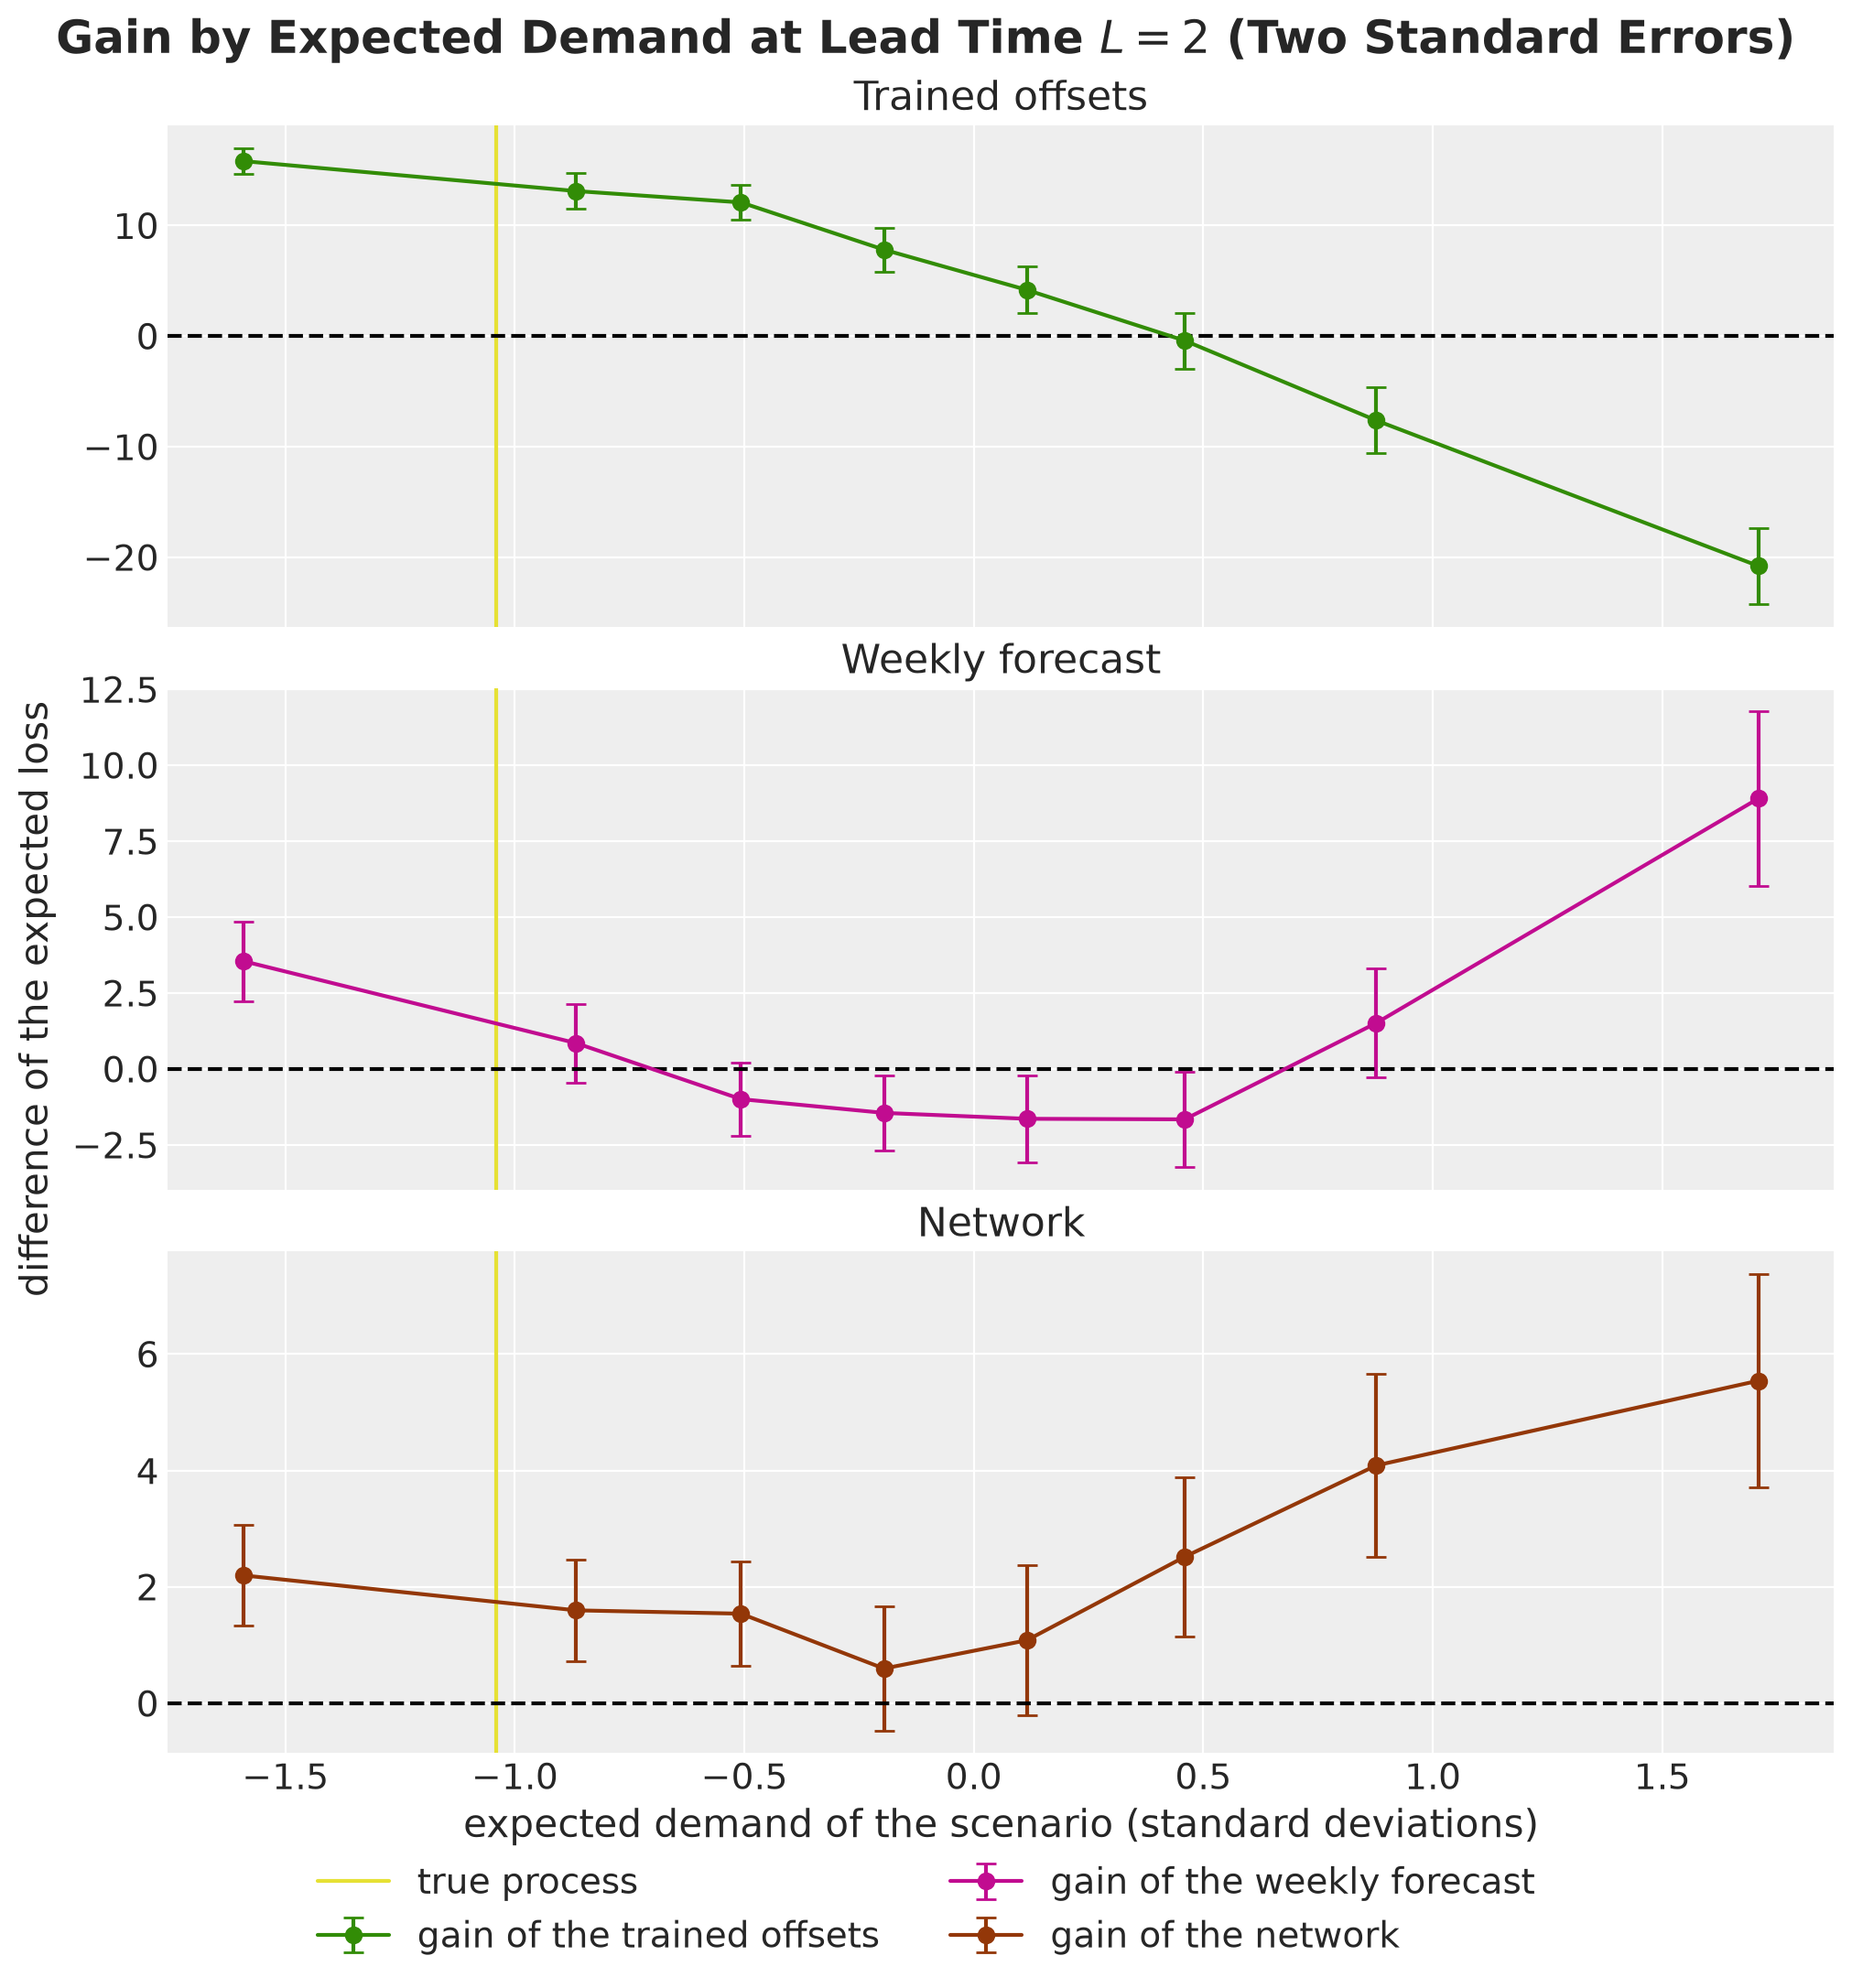

In [52]:
fig, axes = plt.subplots(
    nrows=len(gains), figsize=(10, 3.6 * len(gains)), sharex=True, layout="constrained"
)

for ax, (step, frame) in zip(axes, gains.items(), strict=True):
    ax.errorbar(
        frame[EXPECTED_DEMAND],
        frame["mean gain"],
        yerr=frame["two standard errors"],
        fmt="o-",
        color=POLICY_COLORS[STEP_PAIRS[step][1]],
        capsize=4,
        label=f"gain of the {step.lower()}",
    )
    ax.axvline(
        expected_demand_true,
        color="C6",
        label="true process" if ax is axes[0] else None,
    )
    ax.axhline(0.0, color="black", linestyle="--")
    ax.set(title=step)

axes[-1].set(xlabel="expected demand of the scenario (standard deviations)")
fig.supylabel(
    "difference of the expected loss", fontsize=plt.rcParams["axes.labelsize"]
)
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle(
    f"Gain by Expected Demand at Lead Time $L = {LEAD_TIME_DETAIL}$ "
    "(Two Standard Errors)",
    fontsize=18,
    fontweight="bold",
);

The three panels have different shapes:

- **Trained offsets.** The gain falls from about $16$ in the lowest group to about $-21$ in the highest one. The trained offsets lower the levels in every scenario. This saves holding cost when the demand is at or below the center of the forecast, and it costs lost sales in the top quarter of the scenarios.
- **Weekly forecast.** The gain is about $3.5$ in the lowest group and about $9$ in the highest one. Between them it is between $-1.7$ and $1.5$, and in three of the groups near the center the interval lies below zero. The update gains when the demand of a path is far from the center of the forecast, on either side, and near the center it gains nothing or costs a little. At the two ends the demand of a path is far from what the day-one levels assume, and the update moves the levels toward it. Near the center the day-one levels are already about right, and the weekly levels add the Monte Carlo error of their $1{,}000$ paths, which is consistent with the small cost there.
- **Network.** The mean gain is positive in every group, between about $0.6$ and $5.5$. It is lowest near the center, where the interval of two groups includes zero, and it grows from there to the highest group, where it is largest.

In the first panel the true process lies where the trained offsets gain $13$ to $16$, close to their gain of $15$ on the true process test set at $L = 2$. For a truth in the top quarter of the scenarios the same offsets would raise the loss. In the second panel the position of the true process tells us little. The expected demand mixes the level and the `elasticity`, and the true process is low mostly through its `elasticity`, which the first week does not inform. So a scenario can have a low expected demand that the first week does not show.

### Demand Since the Update

The network also sees the demand of the last week, which the forecast has not seen yet on most days. We want to know whether the network uses this demand. We look at ordering day $15$, when the forecast of day $8$ is $7$ days old and the last $7$ days, days $8$ to $14$, all come after the update. The function `observe_day` runs the neural policy up to a day in every scenario of the forecast test set and returns what the policy observes at the start of that day.

In [53]:
def observe_day(day: int) -> Observation:
    """What the neural policy observes on a day, in every forecast test scenario."""
    trained = policies[LEAD_TIME_DETAIL, PolicyName.NEURAL]
    scenarios = scenarios_for(ScenarioSet.FORECAST, LEAD_TIME_DETAIL, trained.source)

    def observe_path(scenario: Scenarios) -> Observation:
        def step(
            state: InventoryState,
            inputs: tuple[Float[Array, ""], Forecast, Int[Array, ""]],
        ) -> tuple[InventoryState, None]:
            demand_t, forecast_t, day_t = inputs
            day_result = inventory_step(
                trained.policy,
                trained.params,
                state,
                demand_t,
                forecast_t,
                day_t,
                config,
                LEAD_TIME_DETAIL,
            )
            return day_result.state, None

        # run the days before `day`, then observe the start of `day`
        head = jax.tree.map(lambda leaf: leaf[:day], scenario)
        state, _ = jax.lax.scan(
            step,
            initial_state(LEAD_TIME_DETAIL),
            (head.demand, head.forecast, jnp.arange(day)),
        )
        forecast_day = jax.tree.map(lambda leaf: leaf[day], scenario.forecast)
        return observe(state, jnp.asarray(day), forecast_day, LEAD_TIME_DETAIL)

    return jax.vmap(observe_path)(scenarios)


ORDERING_DAY = 15  # the last 7 days are the days 8 to 14, after the update
# what the policy sees on the ordering day (the simulator counts days from zero)
observation = observe_day(ORDERING_DAY - 1)
observation.demand_history.shape

(3000, 7)

We have the observation of every scenario. The correction of the network depends on the demand history, but also on the stock and the forecast, which move with the same demand. To isolate the demand history, we raise the demand of each of the last $7$ days by $10\%$ and keep the rest of the observation fixed. The figure shows the change of the correction in every scenario, against the demand since the update relative to its mean over the scenarios.

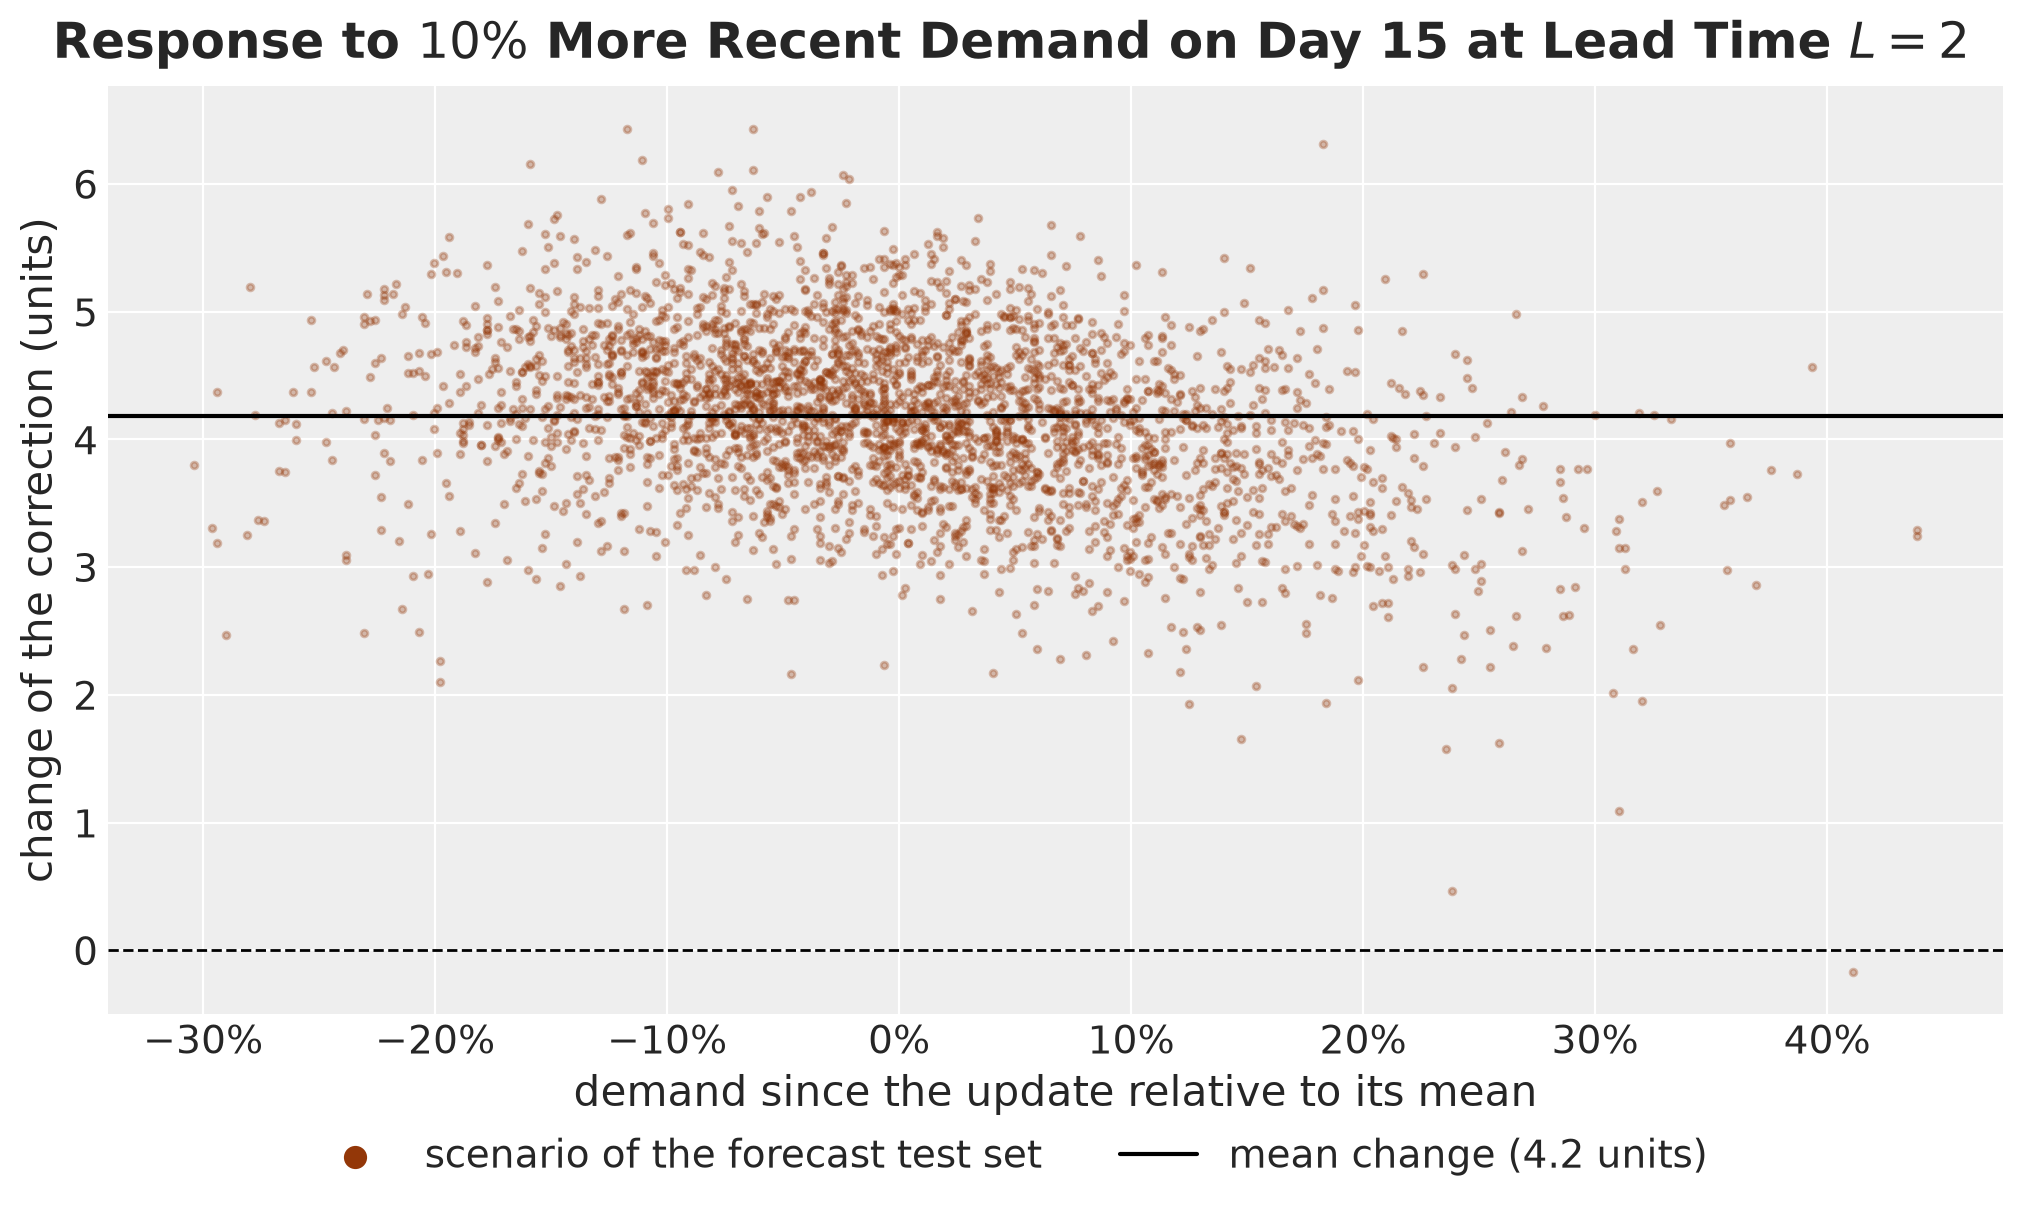

In [54]:
neural_detail = make_neural_policy(LEAD_TIME_DETAIL)
params_detail = policies[LEAD_TIME_DETAIL, PolicyName.NEURAL].params
correction_of = jax.vmap(neural_detail.correction, in_axes=(None, 0))

# the same observations with 10% more demand on each of the last 7 days
observation_up = observation._replace(demand_history=1.1 * observation.demand_history)
response = correction_of(params_detail, observation_up) - correction_of(
    params_detail, observation
)

# the demand of the days since the update, relative to its mean over the scenarios
since_update = observation.demand_history.sum(axis=1)
relative_demand = since_update / since_update.mean() - 1

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(
    relative_demand,
    response,
    s=6,
    alpha=0.3,
    color=POLICY_COLORS[PolicyName.NEURAL],
    label=f"scenario of the {ScenarioSet.FORECAST}",
)
ax.axhline(
    float(response.mean()),
    color="black",
    label=f"mean change ({float(response.mean()):.1f} units)",
)
ax.axhline(0.0, color="black", linestyle="--", linewidth=1)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(
    xlabel="demand since the update relative to its mean",
    ylabel="change of the correction (units)",
)
legend = fig.legend(loc="outside lower center", ncol=2, markerscale=3)
legend.legend_handles[0].set_alpha(1.0)
fig.suptitle(
    f"Response to $10\\%$ More Recent Demand on Day {ORDERING_DAY} "
    f"at Lead Time $L = {LEAD_TIME_DETAIL}$",
    fontsize=18,
    fontweight="bold",
);

The change is positive in all but one of the $3{,}000$ scenarios. On average, $10\%$ more demand on each of the last $7$ days raises the correction by $4.2$ units, and in half of the scenarios by $3.8$ to $4.6$ units. So with the stock and the forecast held fixed, the network uses the demand that the forecast has not seen yet.

### Stock and Stockouts

To see why the policies beat the fixed plan, we look at what each of them does with the stock. We stay with the lead time $L = 2$ and the forecast test set. The next figure shows four of the scores.

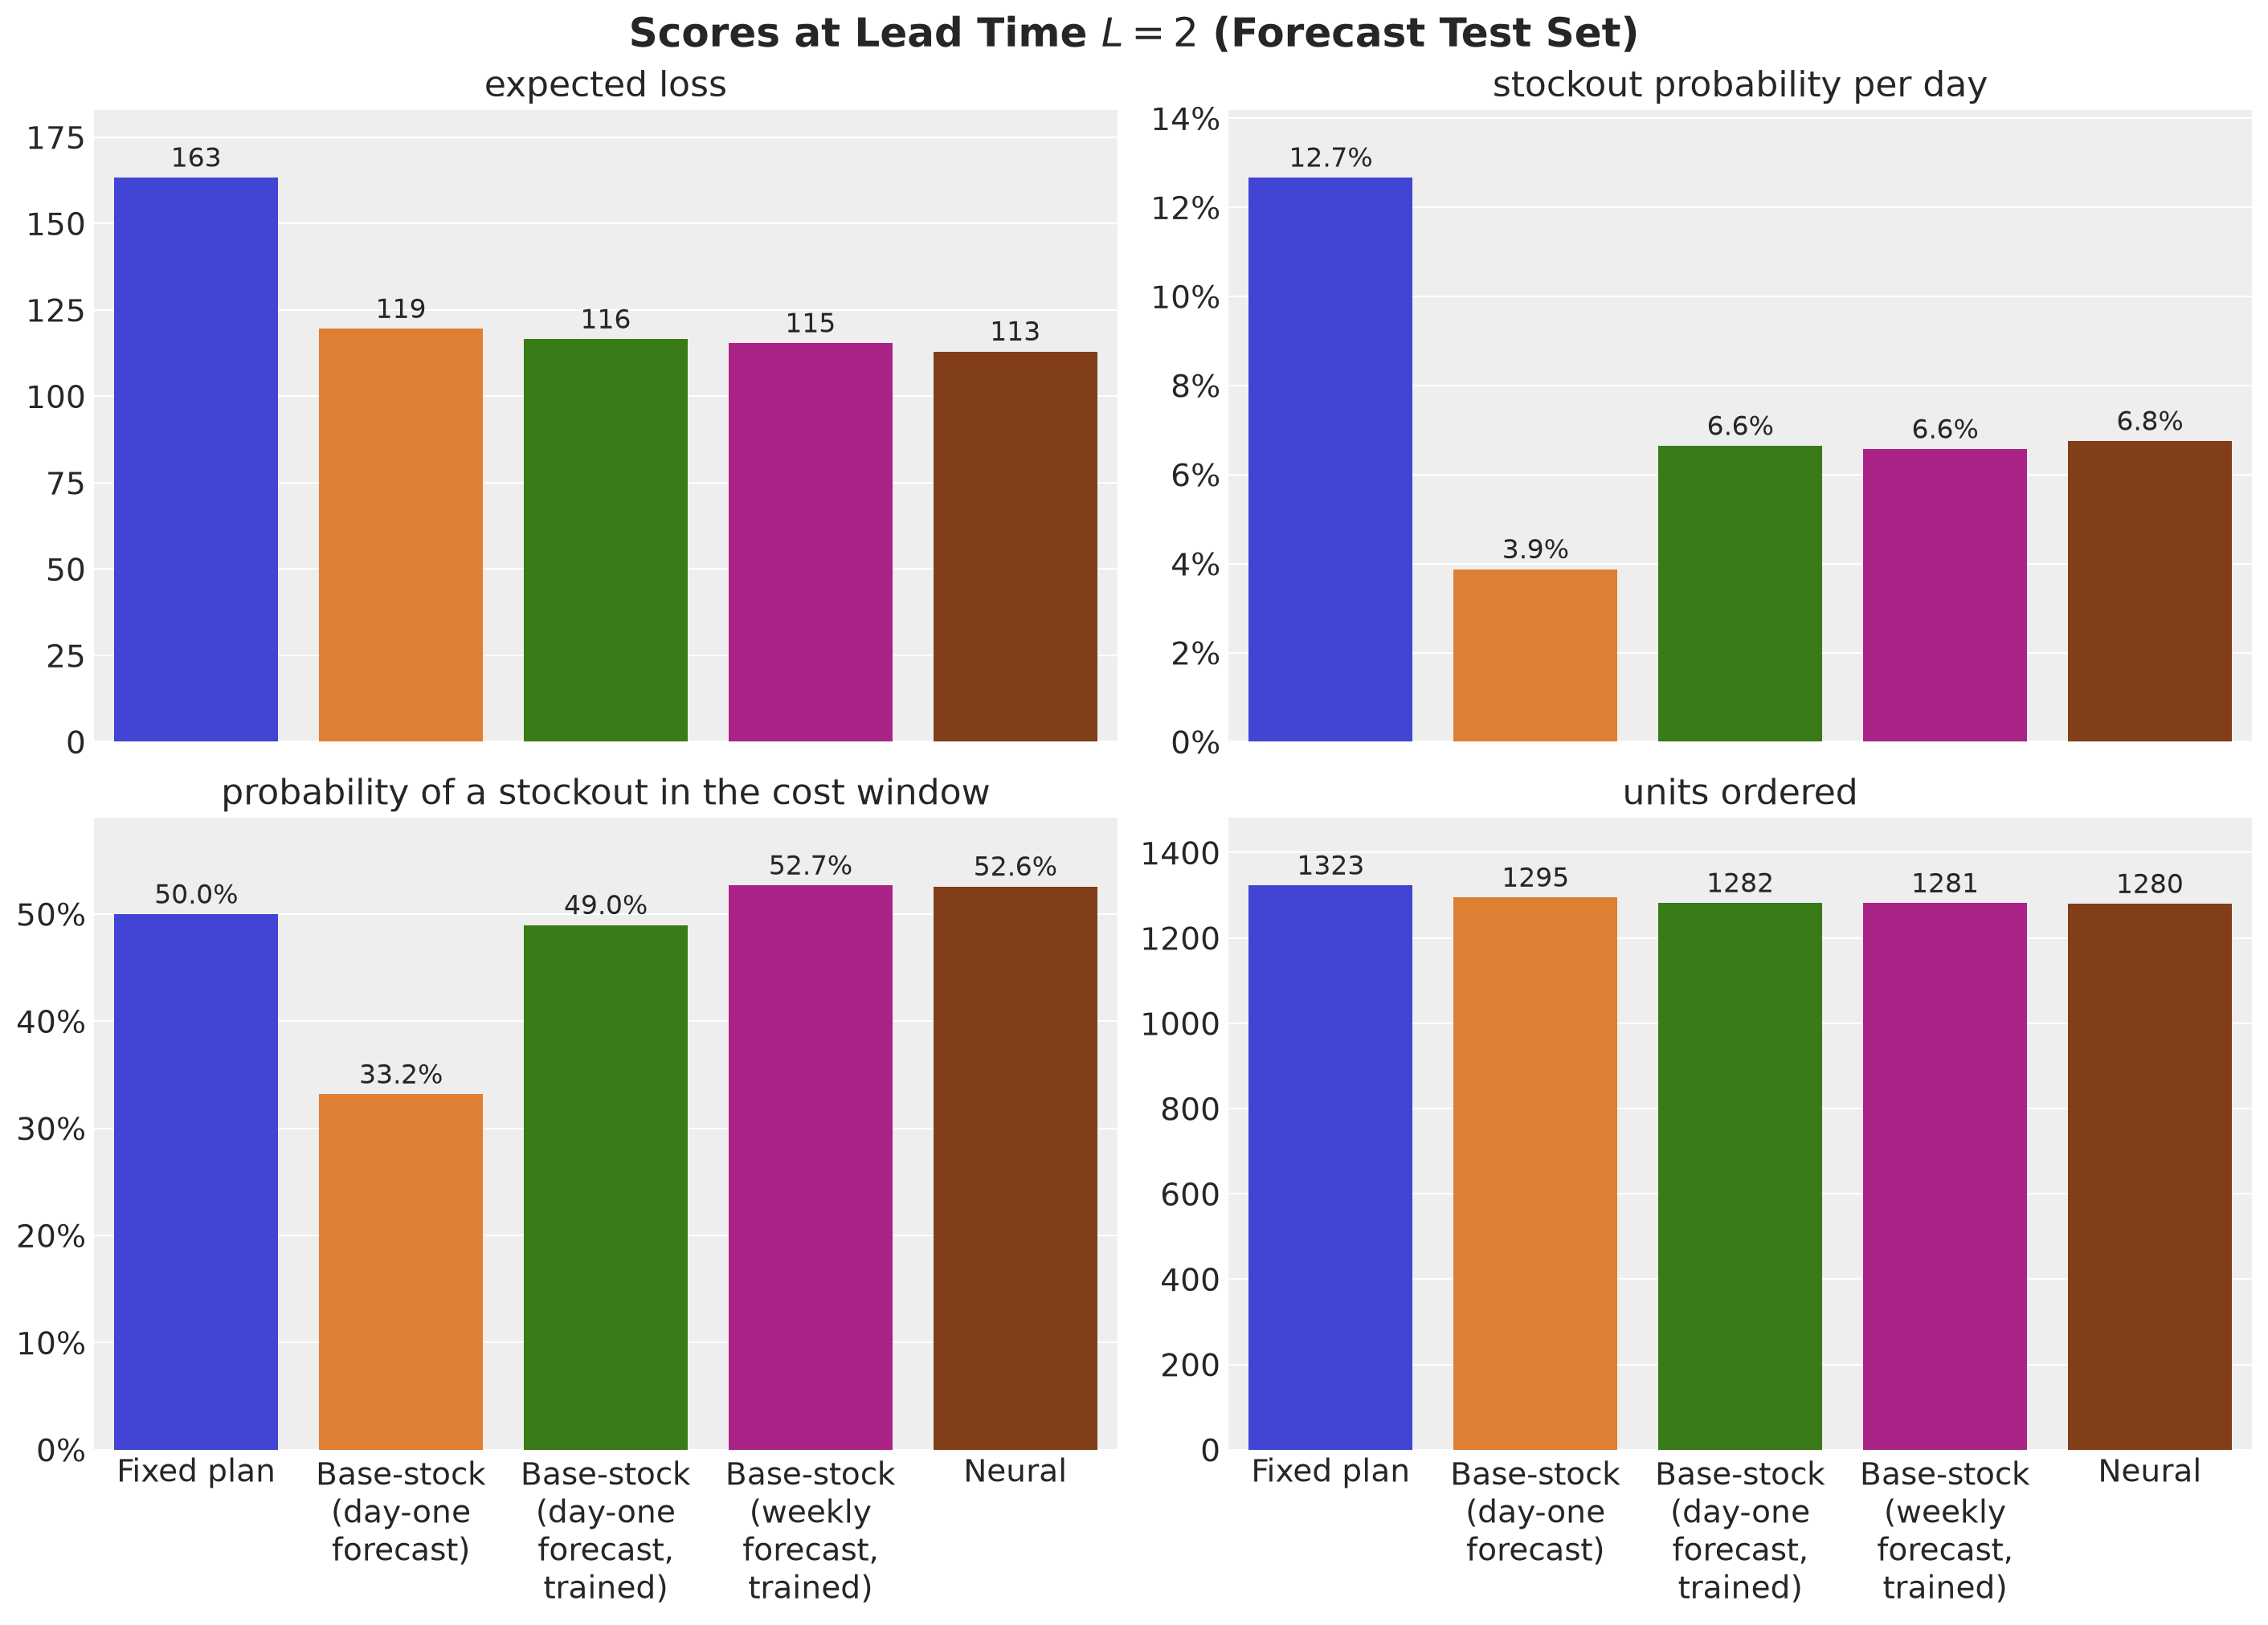

In [55]:
simulations_detail = {
    name: simulations[ScenarioSet.FORECAST, LEAD_TIME_DETAIL, name]
    for name in PolicyName
}
results_detail = pl.DataFrame(
    [
        {"policy": str(name), **summarize(simulation, LEAD_TIME_DETAIL)}
        for name, simulation in simulations_detail.items()
    ]
)

fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(14, 10), sharex=True, layout="constrained"
)

for ax, metric in zip(
    axes.flat,
    [Metric.EXPECTED_LOSS, Metric.STOCKOUT, Metric.WINDOW, Metric.ORDERED],
    strict=True,
):
    is_probability = metric in {Metric.STOCKOUT, Metric.WINDOW}
    sns.barplot(
        data=results_detail,
        x="policy",
        y=metric,
        hue="policy",
        palette=POLICY_COLORS,
        legend=False,
        ax=ax,
    )

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="{:.1%}" if is_probability else "{:.0f}",
            fontsize=12,
            padding=2,
        )

    if is_probability:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

    ax.margins(y=0.12)
    ax.set(title=metric, xlabel="", ylabel="")

for ax in axes[-1]:
    # the names of the policies on three lines
    ax.set_xticks(
        range(len(PolicyName)),
        [
            name.replace(" (", "\n(")
            .replace(" forecast", "\nforecast")
            .replace(", ", ",\n")
            for name in PolicyName
        ],
    )

fig.suptitle(
    f"Scores at Lead Time $L = {LEAD_TIME_DETAIL}$ ({ScenarioSet.FORECAST.title()})",
    fontsize=18,
    fontweight="bold",
);

Let's go through the five policies.

- **Fixed plan.** It has the highest expected loss, $163$. It runs out on $12.7\%$ of the days, and it also orders the most, $1{,}323$ units on average.
- **Base-stock (day-one forecast).** The expected loss is $119$. It runs out on $3.9\%$ of the days and orders $1{,}295$ units. It runs out at least once in the cost window in about $33\%$ of the scenarios.
- **Trained base-stock policies and neural.** The expected loss is $116$, $115$ and $113$. They run out on $6.6\%$ to $6.8\%$ of the days, about $1.7$ times as often as `Base-stock (day-one forecast)`, and order $1{,}280$ to $1{,}282$ units. They run out at least once in the cost window in about half of the scenarios, about as often as the fixed plan.

The fixed plan orders more than every policy and still runs out on more days. Its orders are the same in every scenario. So in the scenarios with low demand the units stay on the shelf, and in the scenarios with high demand they are missing.

The trained offsets lower the levels: the trained policies hold less stock and run out more often, and this is cheaper under our costs. Recall the two observations of the *Base-Stock Training* section. With a lead time `Base-stock (day-one forecast)` runs out less often than $h / (p + h) = 4.8\%$, and a unit that we sell is missing on the next days. The trained policies end up above $4.8\%$, which is consistent with the second observation.

The next figure shows the same five policies day by day: the mean order, the mean stock on hand at the end of the day and the stockout probability. The black lines mark the cost window, and the shaded days are the promotion week.

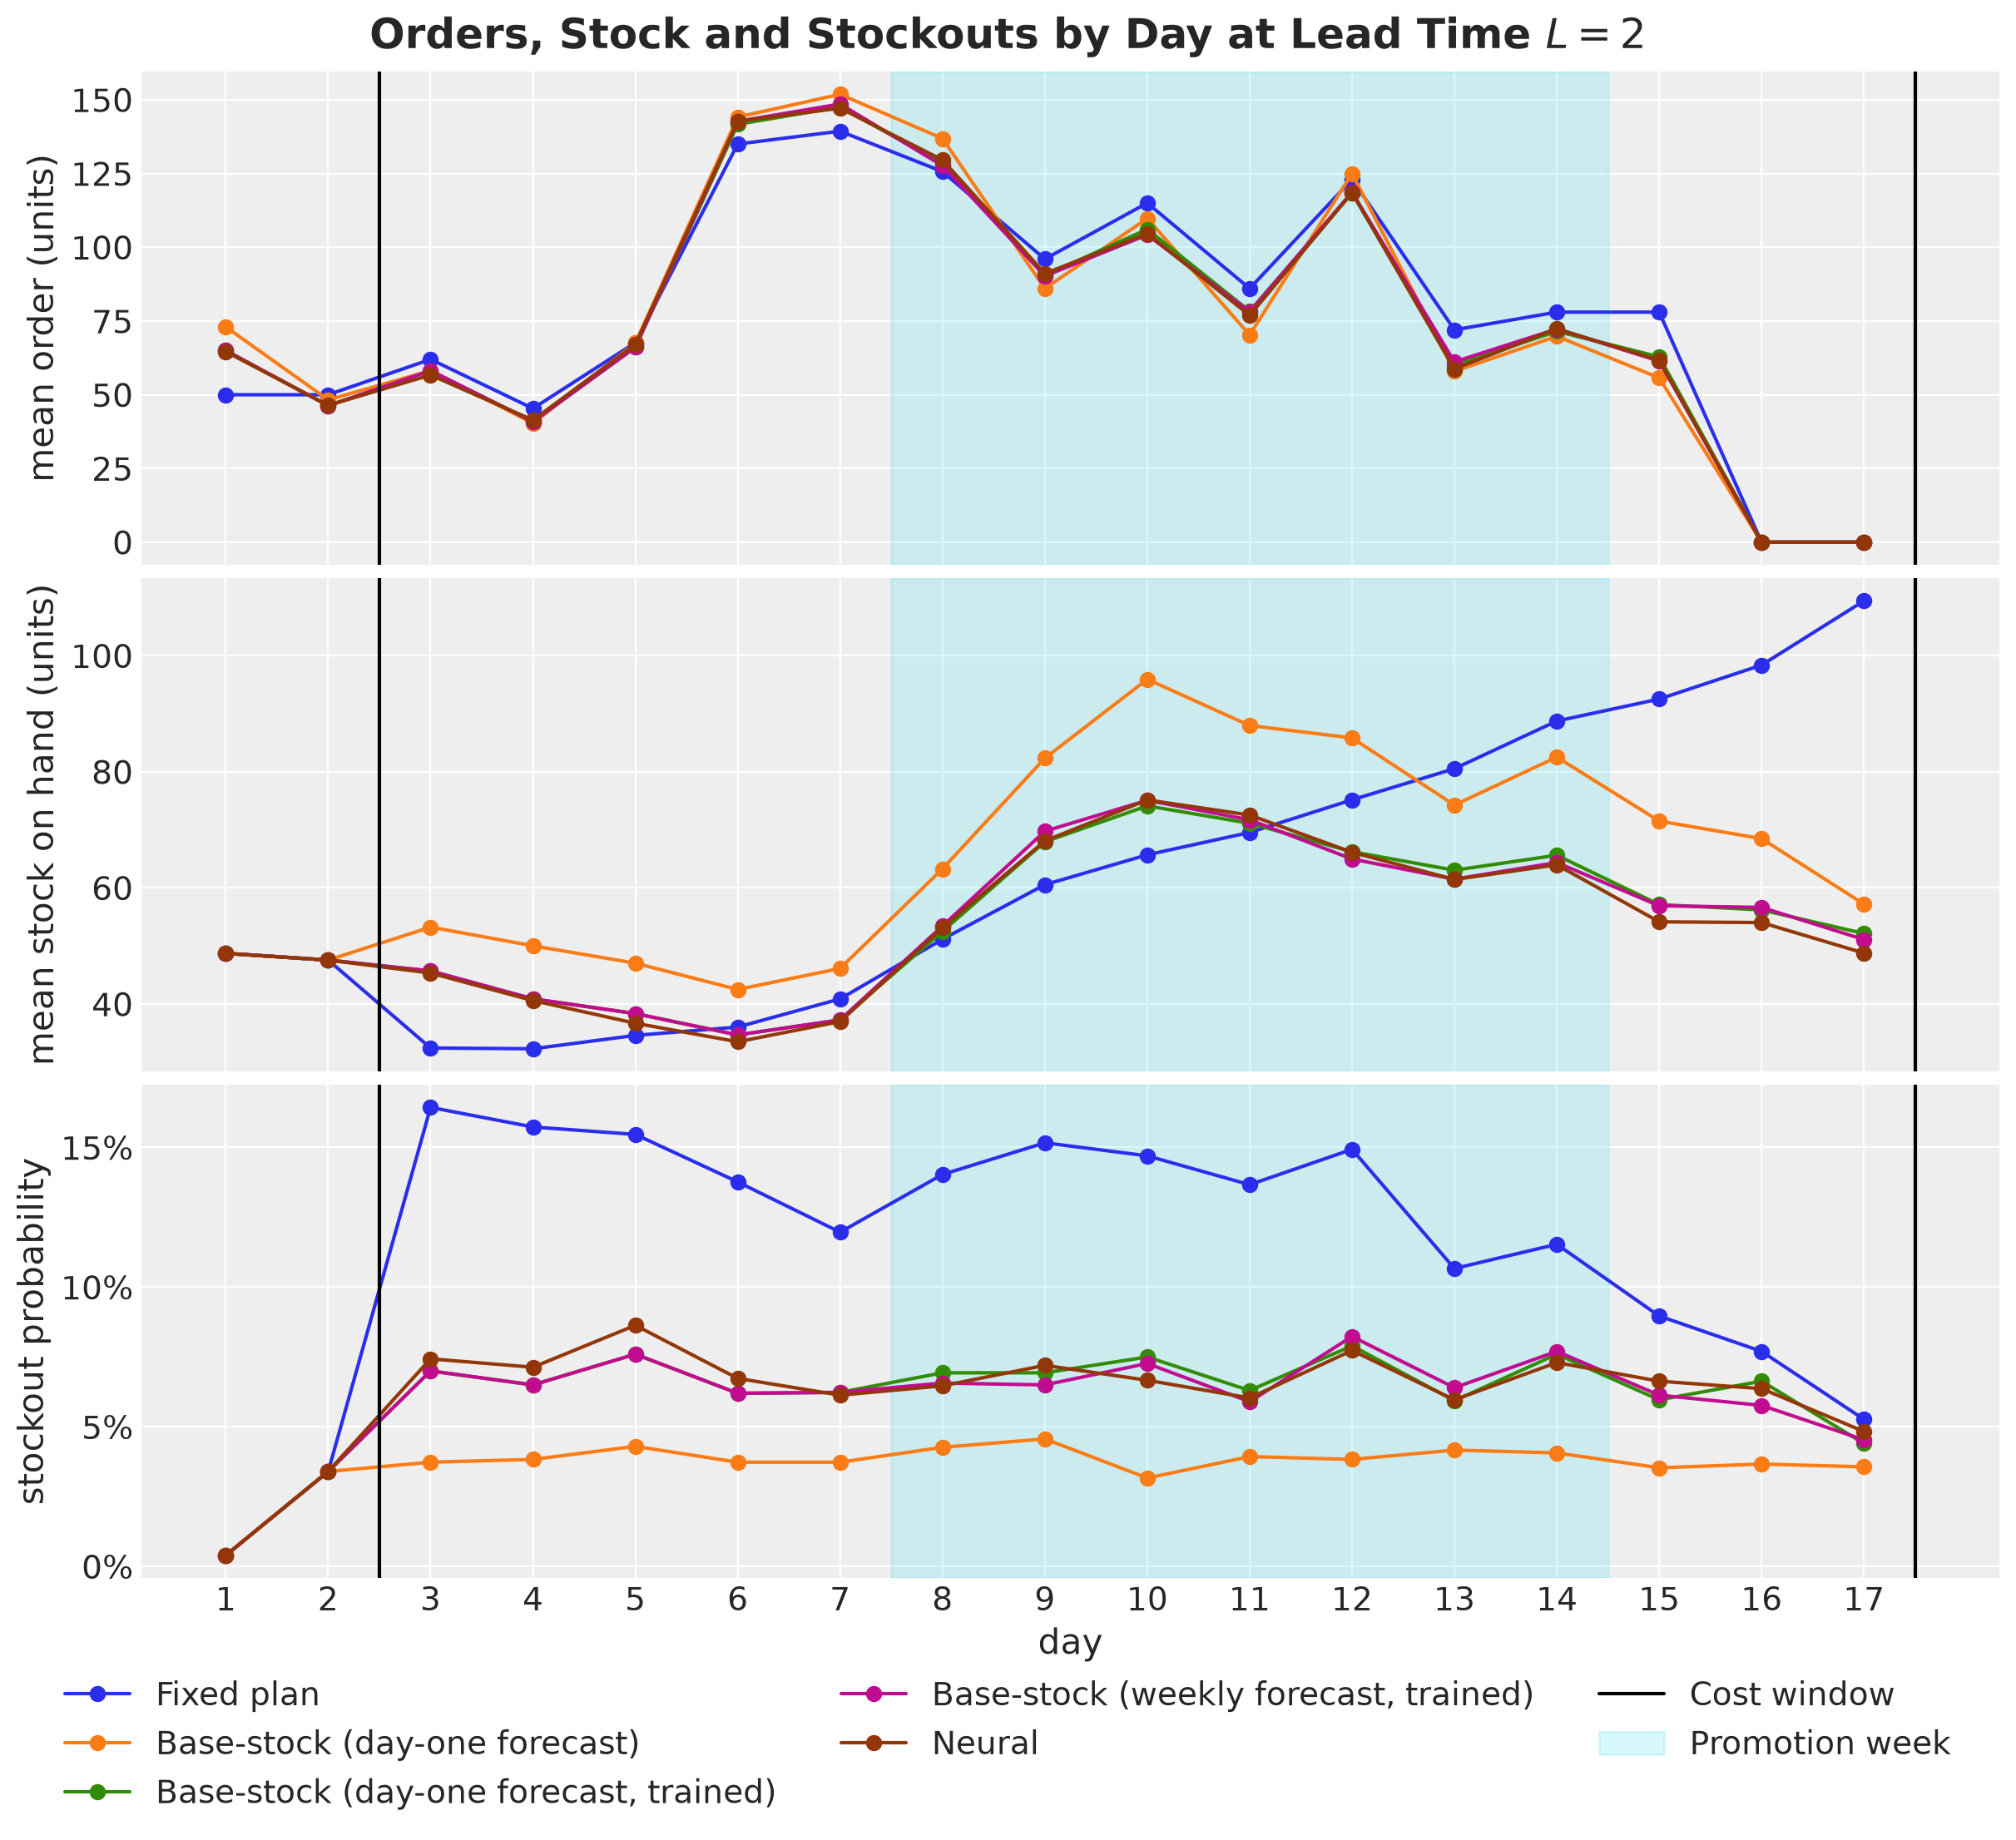

In [56]:
days_detail = jnp.arange(1, setup.horizon + LEAD_TIME_DETAIL + 1)

fig, axes = plt.subplots(nrows=3, figsize=(12, 11), sharex=True, layout="constrained")

for name, simulation in simulations_detail.items():
    for ax, values in zip(
        axes,
        [
            simulation.orders.mean(axis=0),
            simulation.inventory.mean(axis=0),
            (simulation.lost_sales > STOCKOUT_TOL).mean(axis=0),
        ],
        strict=True,
    ):
        ax.plot(days_detail, values, "o-", color=POLICY_COLORS[name], label=name)

for ax in axes:
    ax.axvline(LEAD_TIME_DETAIL + 0.5, color="black", label="Cost window")
    ax.axvline(days_detail[-1] + 0.5, color="black")
    shade_promotion(ax)

axes[0].set(ylabel="mean order (units)")
axes[1].set(ylabel="mean stock on hand (units)")
axes[2].yaxis.set_major_locator(MultipleLocator(0.05))
axes[2].yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
axes[2].set(xlabel="day", ylabel="stockout probability", xticks=days_detail)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle(
    f"Orders, Stock and Stockouts by Day at Lead Time $L = {LEAD_TIME_DETAIL}$",
    fontsize=18,
    fontweight="bold",
);

We go policy by policy again.

- **Fixed plan.** The mean stock grows through the cost window and ends at $109$ units, more than three times its value on day $3$. From day $3$ to day $14$ the stockout probability stays between $11\%$ and $16\%$. The leftovers of the scenarios with low demand pile up, and the plan cannot lower a later order to use them.
- **Base-stock (day-one forecast).** It orders $73$ units on day one, against $50$ for the fixed plan. Its mean stock rises in the promotion week to about $96$ units and comes back to $57$. Its stockout probability stays between about $3\%$ and $4.5\%$ on every day of the cost window.
- **Trained base-stock policies and neural.** They order about $65$ units on day one. Their mean stock is up to $22$ units below the stock of `Base-stock (day-one forecast)`, and their stockout probability is between $4\%$ and $9\%$. The two trained base-stock policies hold about the same stock and run out about as often on every day.

So the fixed plan ends with the most stock and still runs out most often, while the trained policies hold less stock than `Base-stock (day-one forecast)` and accept more stockouts.

### Cost Ratio

Next, we check how much the answer to the first question depends on the costs. The lost margin $p = 2$ is $20$ times the holding cost. We also take a lost margin of $0.5$ and of $8$, so the cost ratios are $p / h = 5$, $20$ and $80$. For each ratio we train the fixed plan again, compute the newsvendor levels of the forecast of day one at the critical fractile of that ratio from the same paths as before, and train the offsets of these levels. The comparison isolates the first question, since the plan and the two policies use only the forecast of day one. The assertion checks that for $p / h = 20$ the sweep gives the two base-stock policies of the main results.

In [57]:
LOST_SALES_COSTS = [0.5, 2.0, 8.0]
SWEEP_POLICIES = [PolicyName.DAY_ONE, PolicyName.DAY_ONE_TRAINED]


def ratio_label(config: InventoryConfig) -> str:
    """The cost ratio p / h of a configuration, as a label."""
    return f"$p / h = {config.lost_sales_cost / config.holding_cost:g}$"


rows = []

for lost_sales_cost in LOST_SALES_COSTS:
    config_sweep = config._replace(lost_sales_cost=lost_sales_cost)
    # the day-one forecast at the critical fractile of this cost ratio
    day_one_sweep = summarize_forecast(
        paths_day_one, setup.max_days, critical_fractile(config_sweep)
    )

    for lead_time in setup.lead_times:
        loss_plan = evaluate(
            train_fixed_plan(lead_time, config_sweep),
            ScenarioSet.FORECAST,
            lead_time,
            config_sweep,
        ).loss.mean()
        # the test scenarios with the levels of this cost ratio
        scenarios_sweep = scenarios_for(
            ScenarioSet.FORECAST,
            lead_time,
            ForecastSource.DAY_ONE,
            day_one=day_one_sweep,
        )
        offsets_sweep = {
            PolicyName.DAY_ONE: no_offsets,
            PolicyName.DAY_ONE_TRAINED: train_base_stock(
                lead_time, config_sweep, ForecastSource.DAY_ONE, day_one=day_one_sweep
            ).params,
        }

        for name in SWEEP_POLICIES:
            loss_base_stock = simulate_scenarios_jit(
                base_stock,
                offsets_sweep[name],
                scenarios_sweep,
                initial_state(lead_time),
                config_sweep,
                lead_time,
            ).loss.mean()
            rows.append(
                {
                    "policy": str(name),
                    "cost ratio": ratio_label(config_sweep),
                    "lead time": lead_time,
                    Metric.EXPECTED_LOSS: float(loss_base_stock),
                    "reduction": float(1 - loss_base_stock / loss_plan),
                }
            )

cost_sweep = pl.DataFrame(rows)

# for our costs the sweep gives the two policies of the main results
main_ratio = ratio_label(config)

for name in SWEEP_POLICIES:
    loss_sweep = cost_sweep.filter(
        (pl.col("policy") == name) & (pl.col("cost ratio") == main_ratio)
    )[Metric.EXPECTED_LOSS]
    loss_main = [
        float(simulations[ScenarioSet.FORECAST, lead_time, name].loss.mean())
        for lead_time in setup.lead_times
    ]
    assert jnp.allclose(jnp.asarray(loss_sweep.to_list()), jnp.asarray(loss_main))

The next figure shows the reduction of the expected loss of the two policies relative to the fixed plan on the forecast test set, one panel per policy. The lines go from dark to light as the cost ratio grows.

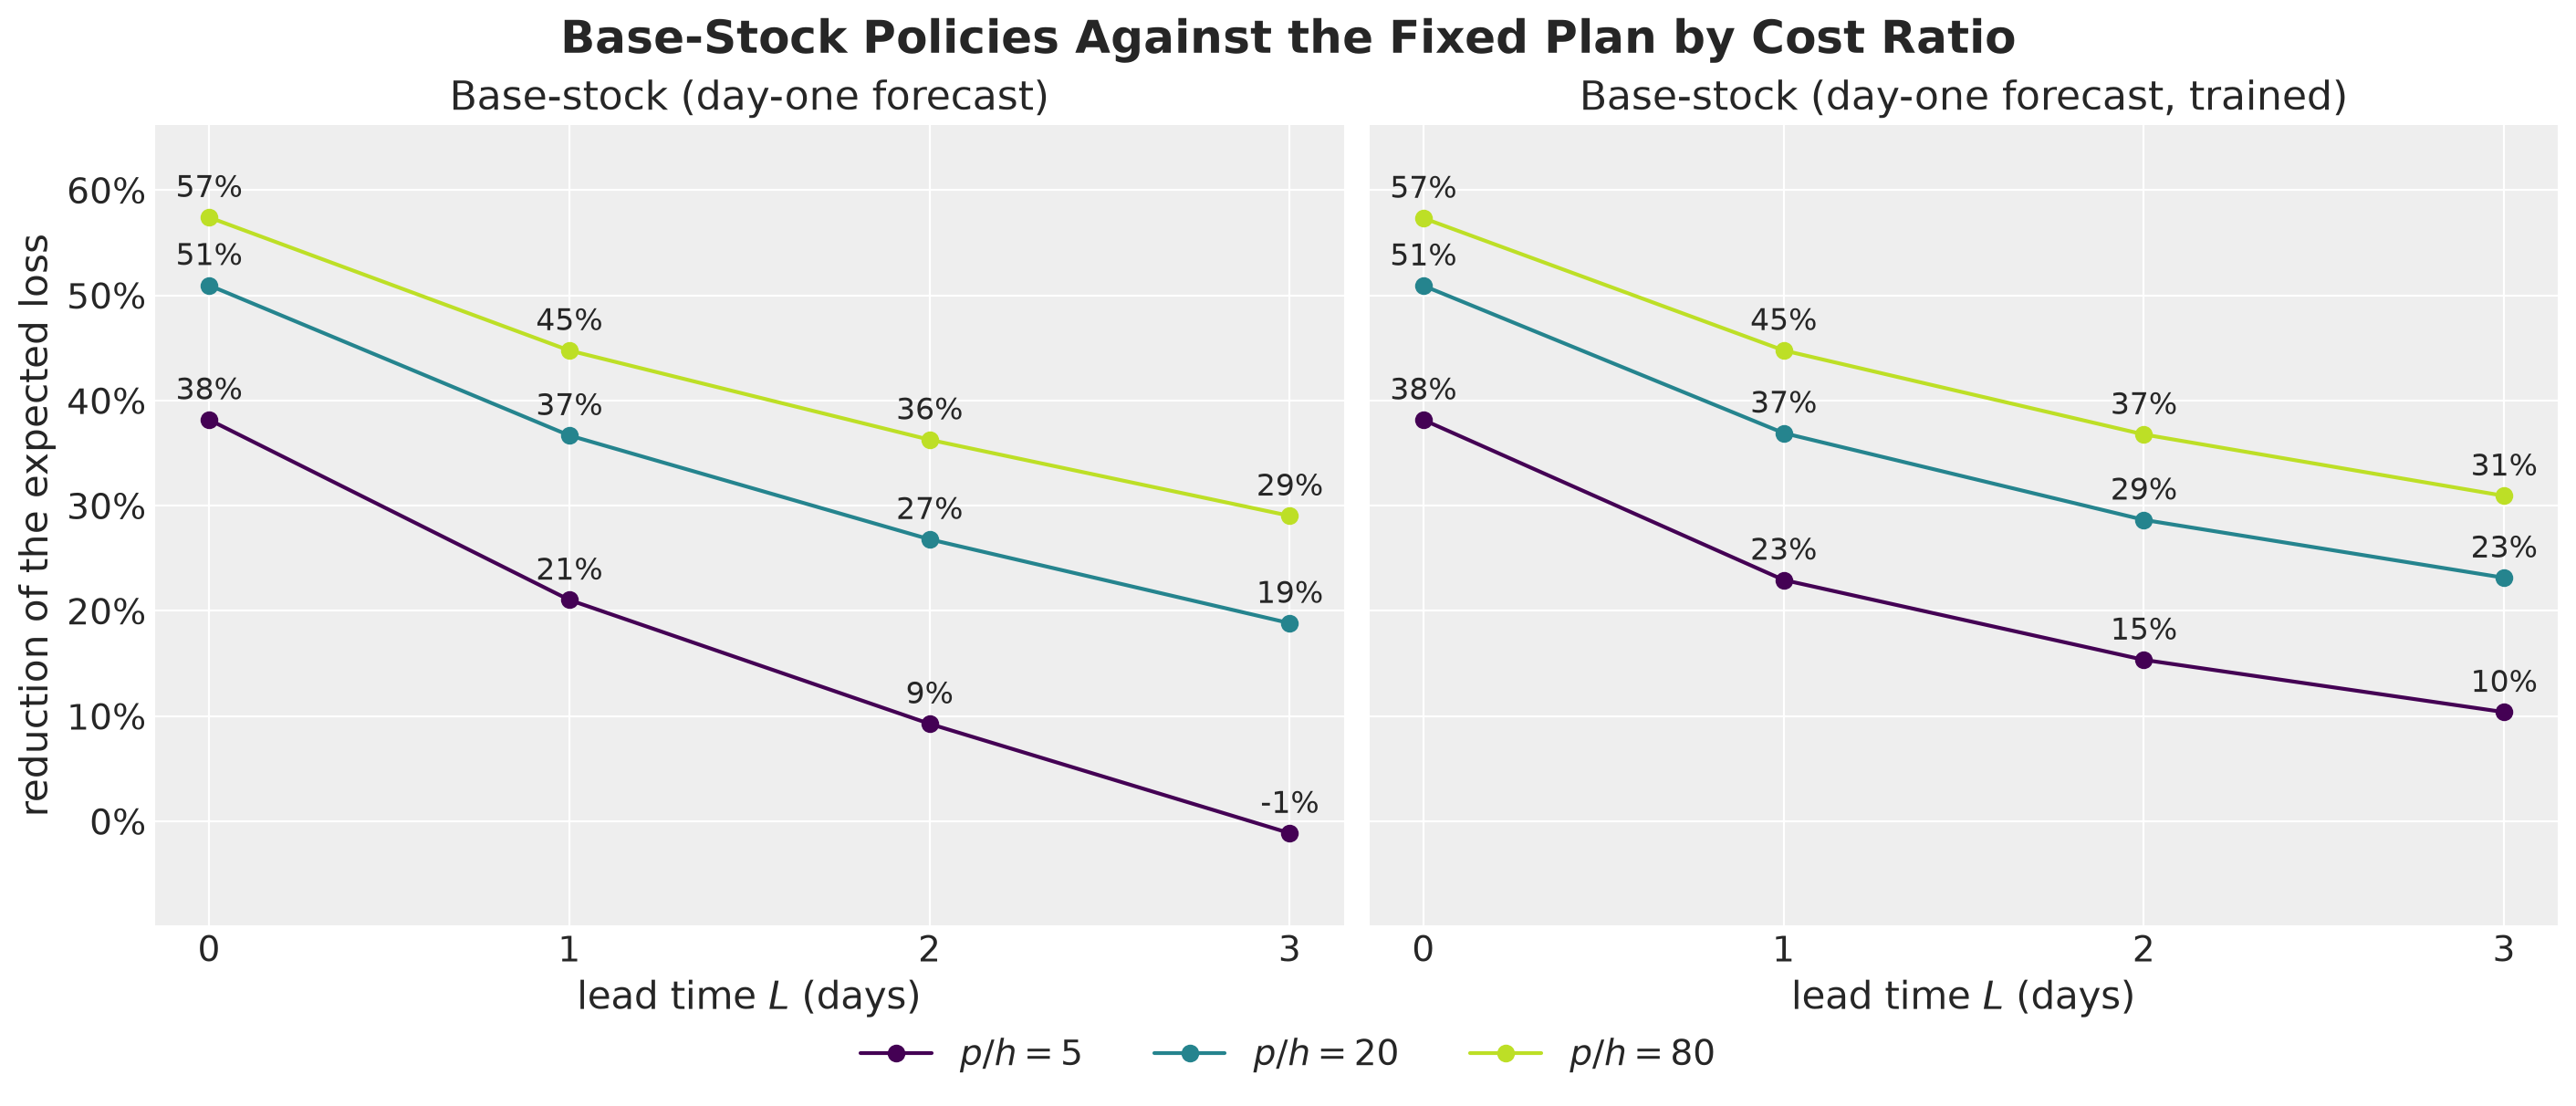

In [58]:
fig, axes = plt.subplots(
    ncols=2, figsize=(14, 6), sharex=True, sharey=True, layout="constrained"
)

for ax, name in zip(axes, SWEEP_POLICIES, strict=True):
    for ((ratio,), frame), color in zip(
        cost_sweep.filter(pl.col("policy") == name).group_by(
            "cost ratio", maintain_order=True
        ),
        sequential_colors(len(LOST_SALES_COSTS)),
        strict=True,
    ):
        ax.plot(frame["lead time"], frame["reduction"], "o-", color=color, label=ratio)

        for lead_time, reduction in zip(
            frame["lead time"], frame["reduction"], strict=True
        ):
            ax.annotate(
                f"{reduction:.0%}",
                (lead_time, reduction),
                textcoords="offset points",
                xytext=(0, 8),
                ha="center",
                fontsize=12,
            )

    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set(title=name, xlabel="lead time $L$ (days)", xticks=setup.lead_times)
    ax.margins(y=0.15)

axes[0].set(ylabel="reduction of the expected loss")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle(
    "Base-Stock Policies Against the Fixed Plan by Cost Ratio",
    fontsize=18,
    fontweight="bold",
);

With `Base-stock (day-one forecast)` the reduction is larger when a lost sale is more expensive: for $L = 0$ it is $38\%$ for the smallest ratio and $57\%$ for the largest. For every ratio it shrinks with the lead time, to between $-1\%$ and $29\%$ for $L = 3$. The trained offsets change little for $L = 0$. For $L = 3$ they move the reduction from $29\%$ to $31\%$ for the largest ratio, from $19\%$ to $23\%$ for ours and from $-1\%$ to $10\%$ for the smallest.

With a cheap lost sale the level is lower and we run out more often. More sales are lost before an order arrives, and by the identity of the *Stock After Lost Sales* section the policy then has more stock than its level assumes. This is consistent with the larger effect of the training for the smallest ratio. It is also the direction of the result of Huh et al. (2009) that we recalled in the *Evidence From the Literature* section: when the cost ratio grows, the cost of their newsvendor level, with the margin $p + L h$, comes closer to the cost of the best level, so the training has less to gain.

So the answer to the first question holds for the three ratios once we train the levels, and its size depends on the costs.

### Tail Risk

Finally, we look at the tail of the loss. Recall that the CVaR is the mean of the worst $5\%$ of the scenario losses, here $150$ of $3{,}000$. We trained four of the five policies for the expected loss, and `Base-stock (day-one forecast)` has no offsets to train. Let's first look at their CVaR by lead time on the forecast test set.

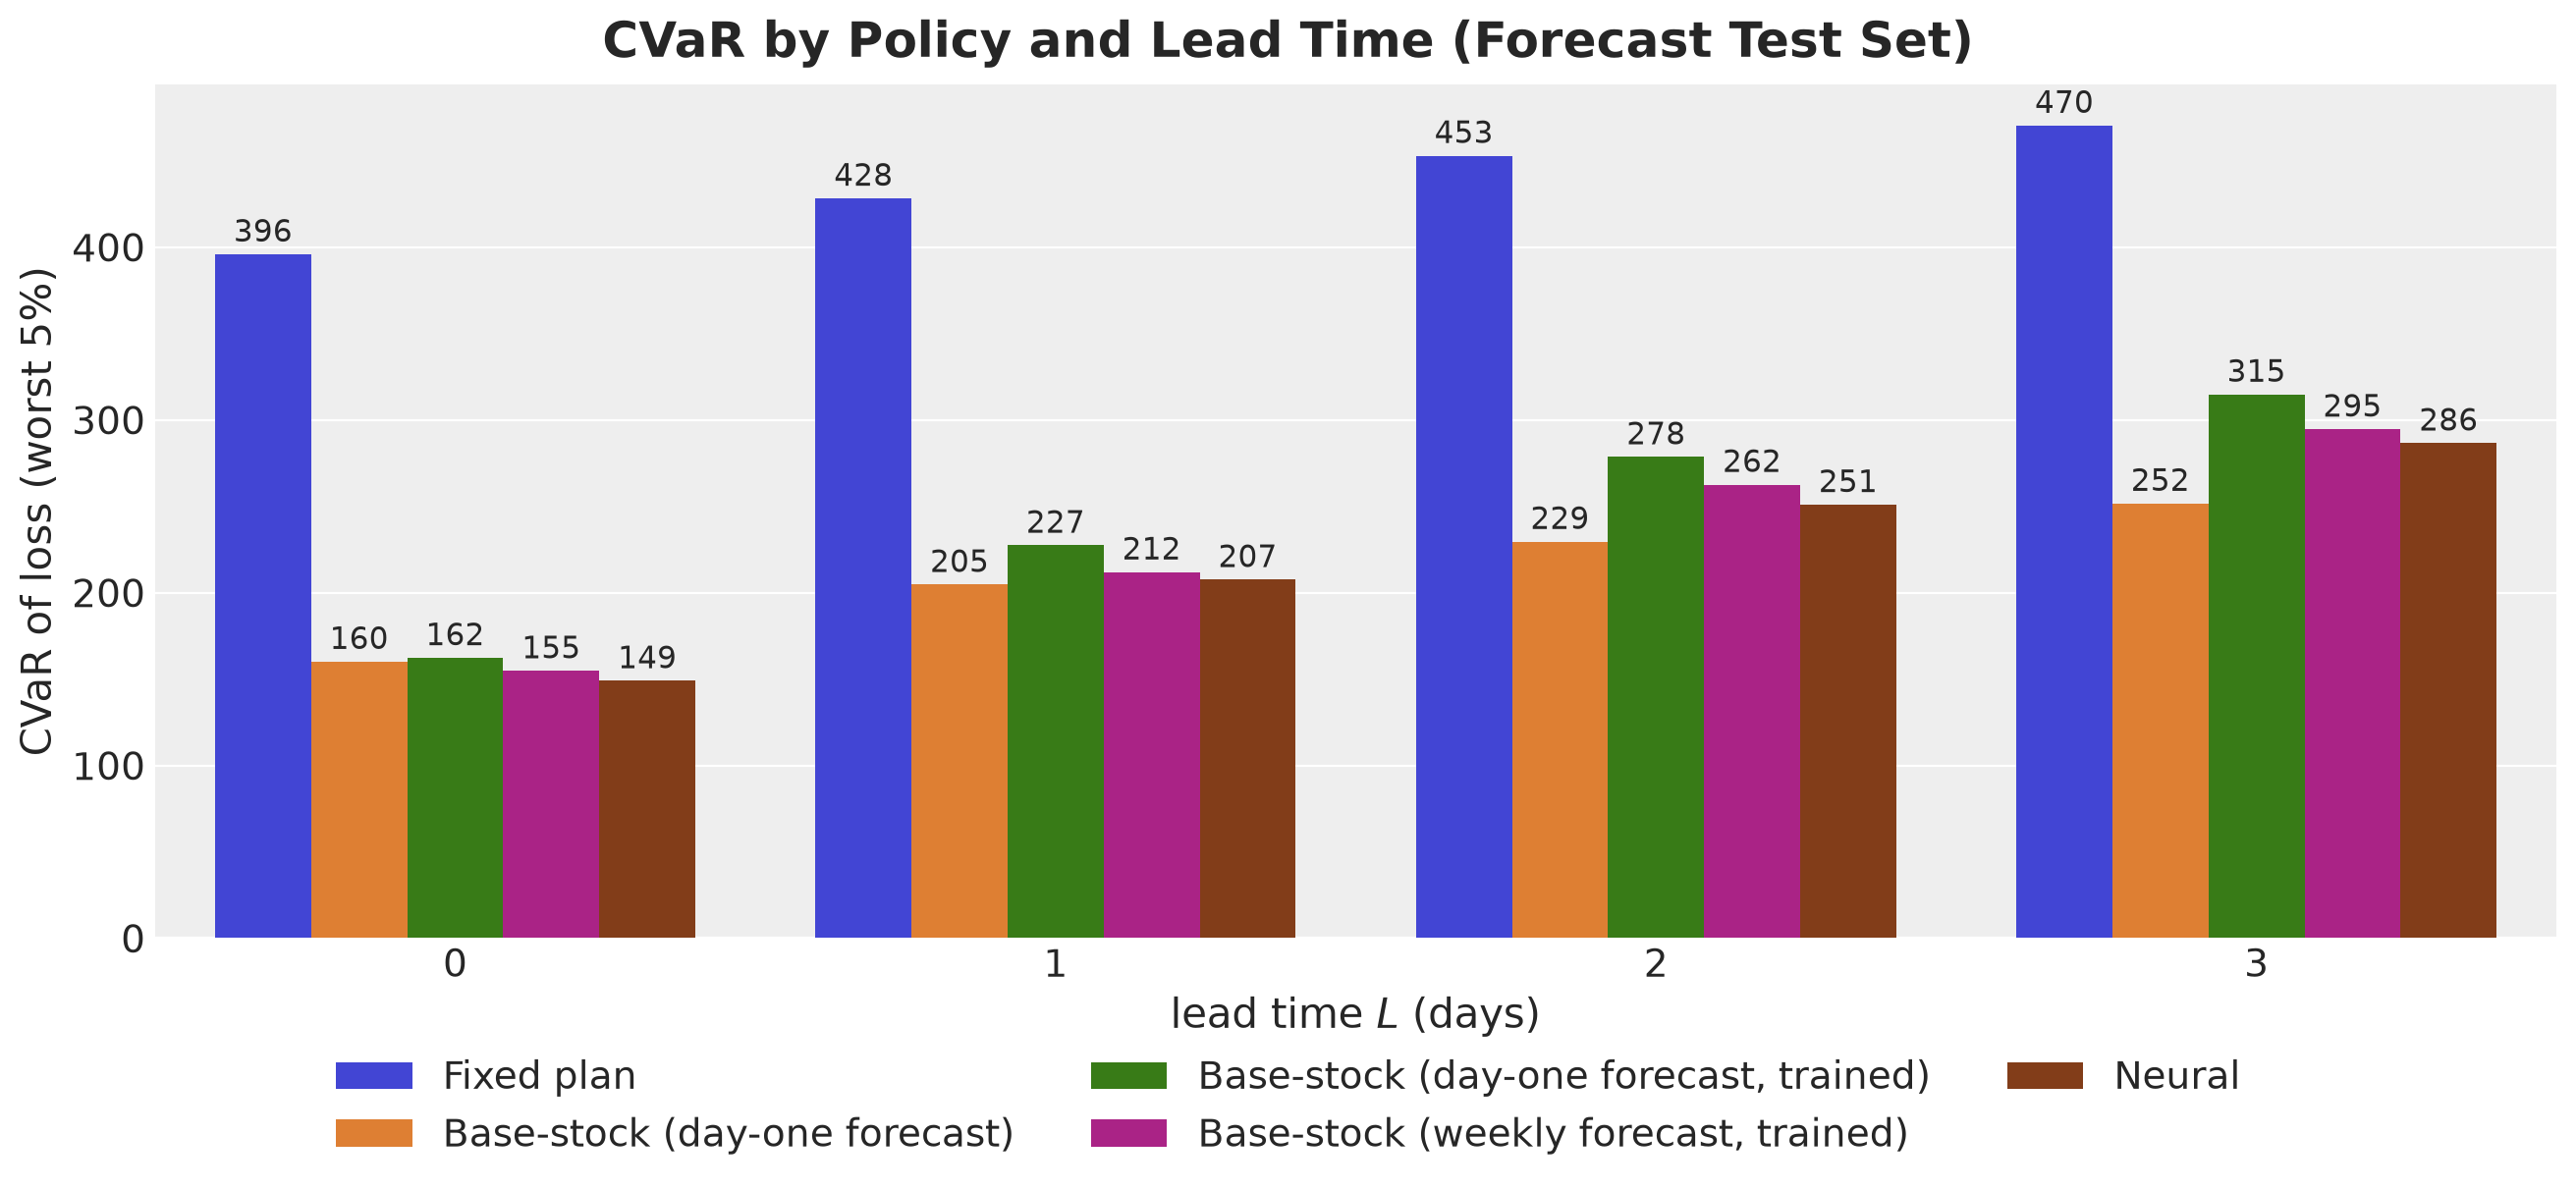

In [59]:
fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(
    data=results.filter(pl.col("scenario set") == ScenarioSet.FORECAST),
    x="lead time",
    y=Metric.CVAR,
    hue="policy",
    hue_order=list(PolicyName),
    palette=POLICY_COLORS,
    errorbar=None,
    ax=ax,
)

for container in ax.containers:
    ax.bar_label(container, fmt="{:.0f}", fontsize=11, padding=2)

ax.get_legend().remove()
ax.set(xlabel="lead time $L$ (days)", ylabel=Metric.CVAR)
fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle(
    f"CVaR by Policy and Lead Time ({ScenarioSet.FORECAST.title()})",
    fontsize=18,
    fontweight="bold",
);

The four policies that look at the stock have a much lower CVaR than the fixed plan at every lead time. Among them the order is not the order of the expected loss.

- **No lead time.** For $L = 0$ the four are within $14$ of each other.
- **Positive lead time.** For $L \geq 1$ `Base-stock (day-one forecast)` has the lowest CVaR. Training its offsets raises the CVaR by $23$, $49$ and $63$ for $L = 1, 2, 3$, about $11\%$ to $25\%$, while it lowers the expected loss by $0.4$ to $7$.
- **Weekly forecast and network.** The weekly forecast lowers the CVaR by $15$ to $20$ for $L \geq 1$. The network lowers it by $4$, $12$ and $8$ for $L = 1, 2, 3$. The CVaR is a mean of $150$ losses, so differences of this size are uncertain.

So the training lowers the expected loss and raises the loss in the worst scenarios. This is consistent with the *Gain by Expected Demand* section, where the trained offsets cost in the scenarios with high demand.

Next, we check whether we can give up some expected loss for a lower CVaR. In the first post the CVaR plan did this, and the tail weight $\lambda$ traced a **frontier**: the plans for which we cannot lower one of the two without raising the other. We can train a policy with the same objective.

We train the fixed plan and `Base-stock (day-one forecast, trained)` for $6$ tail weights at $L = 2$ and score them on the forecast test set. Both use only the forecast of day one, which keeps the comparison about the stock. We show `Base-stock (day-one forecast)`, which has no offsets, as a single point. The assertion checks that with $\lambda = 0$ we get the two policies of the main results.

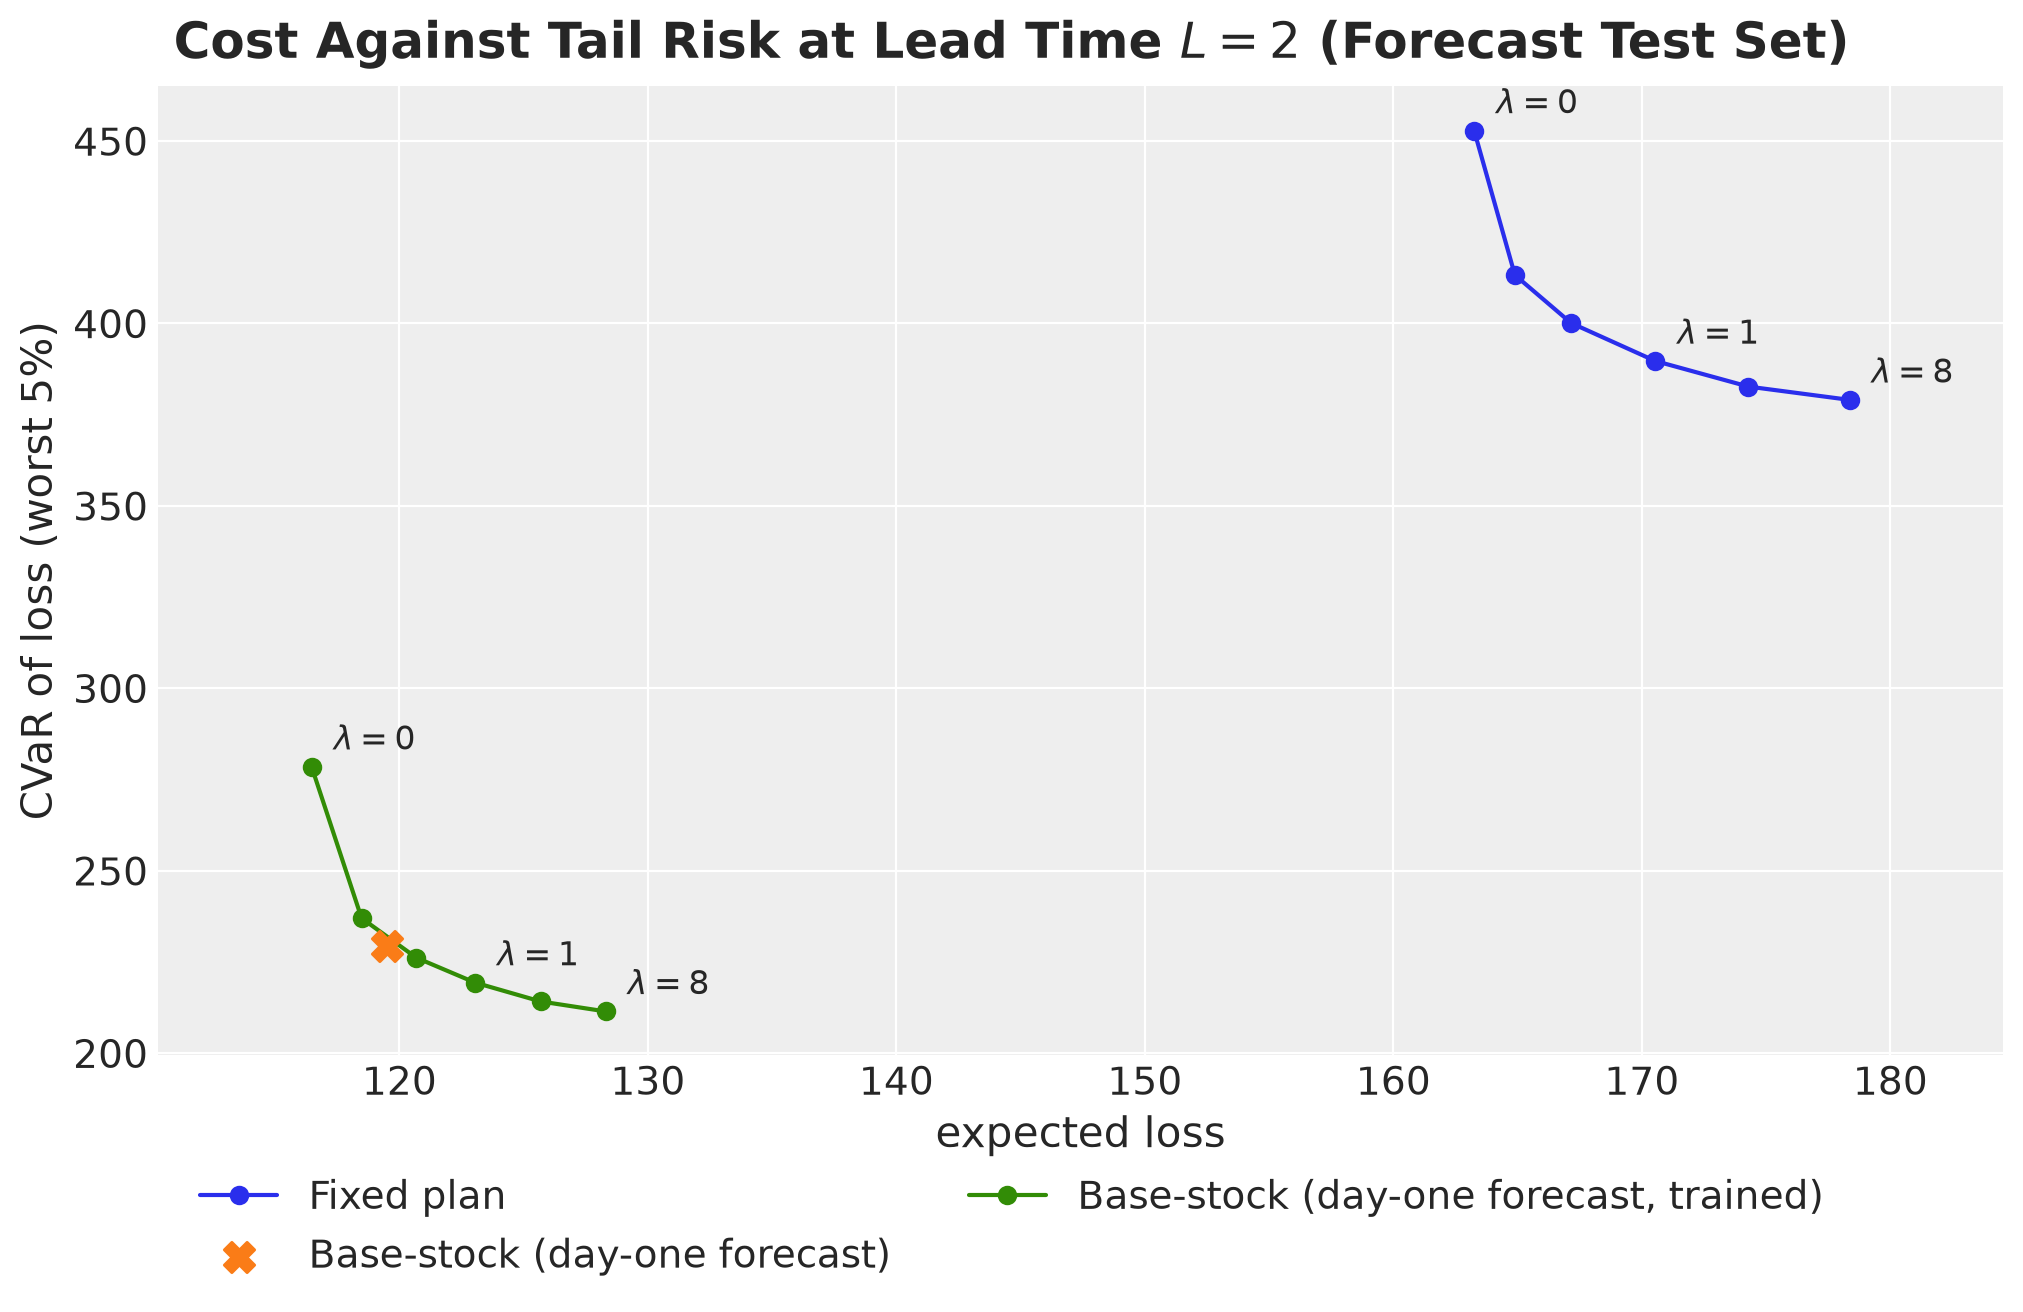

In [60]:
TAIL_WEIGHTS = [0.0, 0.25, 0.5, 1.0, 2.0, 8.0]
# the training function of each frontier
FRONTIER_POLICIES = {
    PolicyName.FIXED_PLAN: lambda tail_weight: train_fixed_plan(
        LEAD_TIME_DETAIL, config, tail_weight
    ),
    PolicyName.DAY_ONE_TRAINED: lambda tail_weight: train_base_stock(
        LEAD_TIME_DETAIL, config, ForecastSource.DAY_ONE, tail_weight
    ),
}
frontier = pl.DataFrame(
    [
        {
            "policy": str(name),
            "tail weight": tail_weight,
            **summarize(
                evaluate(
                    train_policy(tail_weight), ScenarioSet.FORECAST, LEAD_TIME_DETAIL
                ),
                LEAD_TIME_DETAIL,
            ),
        }
        for name, train_policy in FRONTIER_POLICIES.items()
        for tail_weight in TAIL_WEIGHTS
    ]
)

fig, ax = plt.subplots(figsize=(10, 6.5))

for name, frame in zip(
    FRONTIER_POLICIES, frontier.partition_by("policy", maintain_order=True), strict=True
):
    # with a tail weight of zero we get the policy of the main results
    assert math.isclose(
        frame[Metric.EXPECTED_LOSS][0],
        float(simulations[ScenarioSet.FORECAST, LEAD_TIME_DETAIL, name].loss.mean()),
        rel_tol=1e-6,
    )
    ax.plot(
        frame[Metric.EXPECTED_LOSS],
        frame[Metric.CVAR],
        "o-",
        color=POLICY_COLORS[name],
        label=name,
    )

    for row in frame.filter(pl.col("tail weight").is_in([0.0, 1.0, 8.0])).iter_rows(
        named=True
    ):
        ax.annotate(
            rf"$\lambda={row['tail weight']:g}$",
            (row[Metric.EXPECTED_LOSS], row[Metric.CVAR]),
            textcoords="offset points",
            xytext=(8, 6),
            fontsize=12,
        )

# the base-stock policy with the day-one levels and no offsets
day_one_scores = summarize(
    simulations[ScenarioSet.FORECAST, LEAD_TIME_DETAIL, PolicyName.DAY_ONE],
    LEAD_TIME_DETAIL,
)
ax.scatter(
    day_one_scores[Metric.EXPECTED_LOSS],
    day_one_scores[Metric.CVAR],
    marker="X",
    s=120,
    color=POLICY_COLORS[PolicyName.DAY_ONE],
    label=PolicyName.DAY_ONE,
    zorder=3,
)
ax.set(xlabel=Metric.EXPECTED_LOSS, ylabel=Metric.CVAR)
ax.margins(x=0.1)
# the legend in the order of the policies
handles, labels = ax.get_legend_handles_labels()
order = [labels.index(name) for name in PolicyName if name in labels]
fig.legend(
    [handles[k] for k in order],
    [labels[k] for k in order],
    loc="outside lower center",
    ncol=2,
)
fig.suptitle(
    f"Cost Against Tail Risk at Lead Time $L = {LEAD_TIME_DETAIL}$ "
    f"({ScenarioSet.FORECAST.title()})",
    fontsize=18,
    fontweight="bold",
);

Let's compare the two frontiers.

- **Fixed plan.** With $\lambda = 0$ the expected loss is about $163$ and the CVaR about $453$. With $\lambda = 8$ they are about $178$ and $379$. Most of the reduction of the CVaR comes with the first tail weights, as in the first post.
- **Base-stock (day-one forecast).** Without offsets the policy has an expected loss of about $119$ and a CVaR of about $229$.
- **Base-stock (day-one forecast, trained).** The frontier has the same shape as the frontier of the fixed plan. With $\lambda = 0$ the two values are about $116$ and $278$, and with $\lambda = 8$ about $128$ and $211$.

Trained for the expected loss alone, the offsets lower the expected loss by about $3$ and raise the CVaR by about $49$. With the first tail weight, $\lambda = 0.25$, the trained policy has an expected loss of about $118$ and a CVaR of about $237$, close to the $119$ and $229$ of `Base-stock (day-one forecast)`, whose levels are higher.

The whole frontier of `Base-stock (day-one forecast, trained)` lies below and to the left of the frontier of the fixed plan. Trained for the expected loss alone, it has a CVaR of about $278$, and the lowest CVaR of the fixed plan over the $6$ tail weights is about $379$. This is what we expect. A fixed plan loses the most when the demand moves away from the plan, and the base-stock policy changes its orders when that happens.

## Conclusion

### Key Findings

- **Orders that depend on the stock.** A base-stock policy at the newsvendor levels of the forecast needs a quantile of the scenarios and no optimizer. Without a lead time it removed about half of the expected loss of the fixed plan. The fixed plan ordered more units and still ran out on more days, since its orders are the same in every scenario.
- **Lead time.** The gain over the fixed plan is smaller for every extra day of lead time, because each order covers more demand that we have not seen.
- **Trained levels.** With lost sales and a lead time the policy has more stock than its newsvendor levels assume, so training the offsets through the simulator lowers the levels and the expected loss. The gain grows with the lead time, and with a short lead time it can be within the Monte Carlo error. The offsets correct the base-stock rule and not the forecast. The lower levels lower the loss when the demand is at or below the center of the forecast and raise it when the demand is high.
- **Weekly forecast.** Between two policies with trained levels, one update after the first week gave a small gain, which came from the scenarios far from the center of the forecast. The update moves the level of the demand and keeps the parameters of the fit, so it cannot correct a forecast that is wrong about the size of a promotion. On the true process, which differs from the forecast in this way, the gain was smaller, and at the longest lead time it turned into a loss.
- **Network.** A network on top of the trained base-stock policy lowered the expected loss a little further. It also reads the demand since the update: with the stock and the forecast held fixed, it raises its level when the recent demand is higher.
- **Tail risk.** The policies that look at the stock have a much lower CVaR than the fixed plan. Training for the expected loss alone raises the CVaR, and a small tail weight in the objective brings most of it back.
- **One model, one simulator and one trainer.** The same NumPyro model generates the data, is fitted with NUTS and draws every scenario set. One function trains the fixed plan, the offsets and the network, with the gradient from `jax.grad` through the `jax.lax.scan` of the simulator.

### Model Limitations

- **Daily orders.** We place an order every day, and an order has no fixed cost. A retailer that orders once or twice a week needs levels that cover the days until the next order arrives, and a fixed cost per order changes the policy.
- **Observed demand.** We observe the demand of a day even when the shelf was empty. In practice the history is sales, which are censored on those days, see [Caron (2023)](https://kylejcaron.github.io/posts/censored_demand/2024-02-06-censored-demand.html) and the [censored demand example](https://juanitorduz.github.io/numpyro_forecast/docs/examples/censored_demand.html) of `numpyro_forecast`. This assumption also lets us compute the weekly forecast of every scenario before the training, because the forecast then does not depend on the orders. With censored sales the forecast depends on the policy, and the observation model of the filter needs a censored likelihood.
- **One forecast origin.** Every scenario starts from the same history, the same initial stock and the same promotion calendar, so the offsets and the network are specific to these $15$ days. A policy for daily use has to be trained over many forecast origins.
- **One data set and one truth.** The results come from one synthetic series. The true process test set uses one set of true parameters, which lies one standard deviation below the center of the forecast, mostly through the `elasticity`. For a truth above the center the trained offsets would gain less or raise the loss, as the *Gain by Expected Demand* section shows.
- **Well-specified forecast.** The forecasting model has the structure of the generator. With a misspecified forecast the scenarios, the levels and the forecast update can be wrong in the same direction, and we did not study that case.
- **Forecast update.** The update keeps the parameter draws of the fit and approximates the level of each draw with a Normal distribution. After the highest first week of the test set it moves the forecast less than a refit, as the *Appendix* shows. The updated levels come from $1{,}000$ paths per scenario, and their Monte Carlo error can add a small cost to the policies that read the weekly forecast.
- **One update.** We update the forecast once, on day $8$, with a week that has no promotion. An update on day $15$ would change only the last order, and a daily update would give the policies more recent forecasts. The policy that reads the update is the $p / (p + h)$ quantile of the updated forecast plus one offset per day, and another policy could gain more from the same update.
- **Cost of a stockout.** A lost sale costs the margin $p$ and nothing else. At $L = 2$ the trained policies run out on about $7\%$ of the days, against $4\%$ for `Base-stock (day-one forecast)`, which is cheaper under this cost. If a stockout also costs future demand, the loss needs a larger $p$.
- **Small samples for small differences.** The validation set has $1{,}000$ scenarios from $200$ posterior draws, and the error bars of the paired differences are for one training run of each policy. The CVaR is a mean of $150$ losses.
- **Costs and lead time.** The lead time is known and the same for every order, the costs are linear and the orders are continuous. Order minimums, fixed ordering costs and uncertain lead times change the simulator.

### Recommendations

1. **Start with a base-stock policy.** Order up to the $p / (p + h)$ quantile of the total demand of the next $L + 1$ days under the forecast, from the stock on hand plus the pipeline. It needs the scenarios of the forecast and a quantile. Without a lead time this was all we needed, and with one it is the starting point of the training.
2. **Train the levels when there is a lead time.** With lost sales the newsvendor levels are too high, and one offset per day lowered the expected loss by about $3$ and $7$ for $L = 2$ and $L = 3$ on the forecast test set, with more stockouts and a higher CVaR. If a stockout costs more than the margin, train with a larger $p$, as in the *Cost Ratio* section. If the worst scenarios matter, train with a tail weight, as in the *Tail Risk* section.
3. **Update the forecast with the new demand.** With trained levels, one update after a week lowered the expected loss by $0.4$ to $1.2$ on the forecast test set, and it gained most in the scenarios far from the center of the forecast. In production a weekly refit of the model is enough. To train a policy that reads the update we need it on every training scenario, and there a filter makes it cheap enough.
4. **Measure before adding a network.** Compare the candidates on the same held-out scenarios, look at the paired difference with its Monte Carlo error, and check how the gain depends on where the truth can lie inside the forecast.

## Next Steps

1. **Rolling horizon.** Solve the fixed plan again every day with the latest forecast and place only its first order, the practical version of the problem of the first post. It needs a solve for every scenario and every day, so it costs much more than a trained policy, and we left it out here.
2. **Censored demand.** Train the policies on sales, with a censored likelihood in the forecasting model and in the observation model of the filter. The forecast then depends on the orders, so the filter has to run inside the simulator.
3. **Many forecast origins.** Train one policy on the scenarios of the forecast origins of a rolling backtest, with the forecast of each origin among its features, so that it can be used every day.
4. **Many products.** Share a capacity between the products of a store, and let the policy return the orders of all the products.

## Appendix

In the *Forecast Updates* section we replaced the refit of the forecasting model with a filter that keeps the parameter draws of the fit. Here we compare the two on $6$ scenarios of the forecast test set. We sort the scenarios by the total demand of their first week and take the lowest, the highest and the $5\%$, $25\%$, $75\%$ and $95\%$ quantiles, so that the comparison includes first weeks that are far from the forecast.

We suppose that we have observed the first week of each scenario, and we compute the forecast of the total demand of the remaining $11$ days, which contain the promotion week, in two ways:

- **Filter.** We update the forecast with `update_forecast`.
- **NUTS refit.** We fit the forecasting model again on the history plus the first week, with the sampler settings of the fit on the history. We keep one of every four posterior draws, so that both forecasts have $1{,}000$ paths.

We write both forecasts as the forecast minus the realized total, so that zero is a perfect forecast. We also keep the posterior mean of the `elasticity` of every refit. The table shows, for each scenario, the total demand of its first week, the mean error of the two forecasts and the `elasticity` of the refit.

In [61]:
%%time

# the lowest and the highest first week of the test set, and four quantiles between
CHECK_QUANTILES = (0.0, 0.05, 0.25, 0.75, 0.95, 1.0)
NUM_CHECK_SCENARIOS = len(CHECK_QUANTILES)

first_week_total = demand_by_set[ScenarioSet.FORECAST][:, :NUM_OBSERVED].sum(axis=1)
check_index = jnp.argsort(first_week_total)[
    (jnp.asarray(CHECK_QUANTILES) * (first_week_total.shape[0] - 1)).astype(int)
]
paths_check = demand_by_set[ScenarioSet.FORECAST][check_index]
realized_check = paths_check[:, NUM_OBSERVED:].sum(axis=1)
rng_key, key_check = random.split(rng_key)
keys_check = random.split(key_check, NUM_CHECK_SCENARIOS)

update_forecast_jit = jax.jit(update_forecast)
mcmc_refit = MCMC(
    NUTS(non_centered_model, target_accept_prob=TARGET_ACCEPT_PROB),
    num_warmup=1_000,
    num_samples=1_000,
    num_chains=4,
    thinning=4,  # one of every four draws, as many paths as the filter gives
    progress_bar=False,
)
filter_errors, refit_errors, refit_elasticity = [], [], []

for key, path, realized in zip(keys_check, paths_check, realized_check, strict=True):
    key_filter, key_refit, key_predict = random.split(key, 3)
    forecast_filter = update_forecast_jit(key_filter, path[:NUM_OBSERVED])
    filter_errors.append(forecast_filter[:, :num_remaining].sum(axis=1) - realized)
    # the history plus the observed days, as integers like the history
    data_long = jnp.concatenate([data, path[:NUM_OBSERVED, None].astype(data.dtype)])
    mcmc_refit.run(key_refit, covariates[: setup.t_obs + NUM_OBSERVED], data_long)
    posterior_refit = mcmc_refit.get_samples()
    forecast_refit = forecast(
        key_predict, demand_model, posterior_refit, data_long, covariates_sim
    )[..., 0]
    refit_errors.append(forecast_refit.sum(axis=1) - realized)
    refit_elasticity.append(float(posterior_refit[Site.ELASTICITY].mean()))

forecast_errors: dict[str, Float[Array, "draws scenarios"]] = {
    "Filter": jnp.stack(filter_errors, axis=1),
    "NUTS refit": jnp.stack(refit_errors, axis=1),
}
assert forecast_errors["Filter"].shape == forecast_errors["NUTS refit"].shape
pl.DataFrame(
    {
        "scenario": list(range(1, NUM_CHECK_SCENARIOS + 1)),
        "quantile of the first week": [f"{q:.0%}" for q in CHECK_QUANTILES],
        "total demand of the first week": first_week_total[check_index].tolist(),
        **{
            f"mean error: {name}": errors.mean(axis=0).tolist()
            for name, errors in forecast_errors.items()
        },
        "elasticity of the refit": [f"{value:.2f}" for value in refit_elasticity],
    }
)

CPU times: user 8min 39s, sys: 4min 11s, total: 12min 50s
Wall time: 2min 31s


scenario,quantile of the first week,total demand of the first week,mean error: Filter,mean error: NUTS refit,elasticity of the refit
i64,str,f64,f64,f64,str
1,"""0%""",296.0,90.1,81.9,"""-1.70"""
2,"""5%""",362.0,111.0,110.4,"""-1.70"""
3,"""25%""",403.0,9.9,17.5,"""-1.69"""
4,"""75%""",465.0,-6.2,-6.7,"""-1.68"""
5,"""95%""",512.0,-56.9,-45.2,"""-1.68"""
6,"""100%""",662.0,-19.6,57.1,"""-1.66"""


The first weeks go from $296$ to $662$ units. In the first $5$ scenarios, including the lowest first week, the mean errors of the two forecasts are at most $12$ units apart. After the highest first week the refit has the higher forecast, by $77$ units. So after the highest first week of the test set the refit moves the forecast further than the filter. This is consistent with the approximation of the filter, which keeps the parameter draws of the fit with equal weights, while a refit can also move the parameters. The `elasticity` hardly moves: its posterior mean stays between $-1.70$ and $-1.66$ in the $6$ refits, against $-1.69$ in the fit on the history.

The next figure shows the two forecasts for every scenario. We also compute the continuous ranked probability score (CRPS) of both. The CRPS generalizes the absolute error to a predictive distribution. It is in the units of the data, and lower is better.

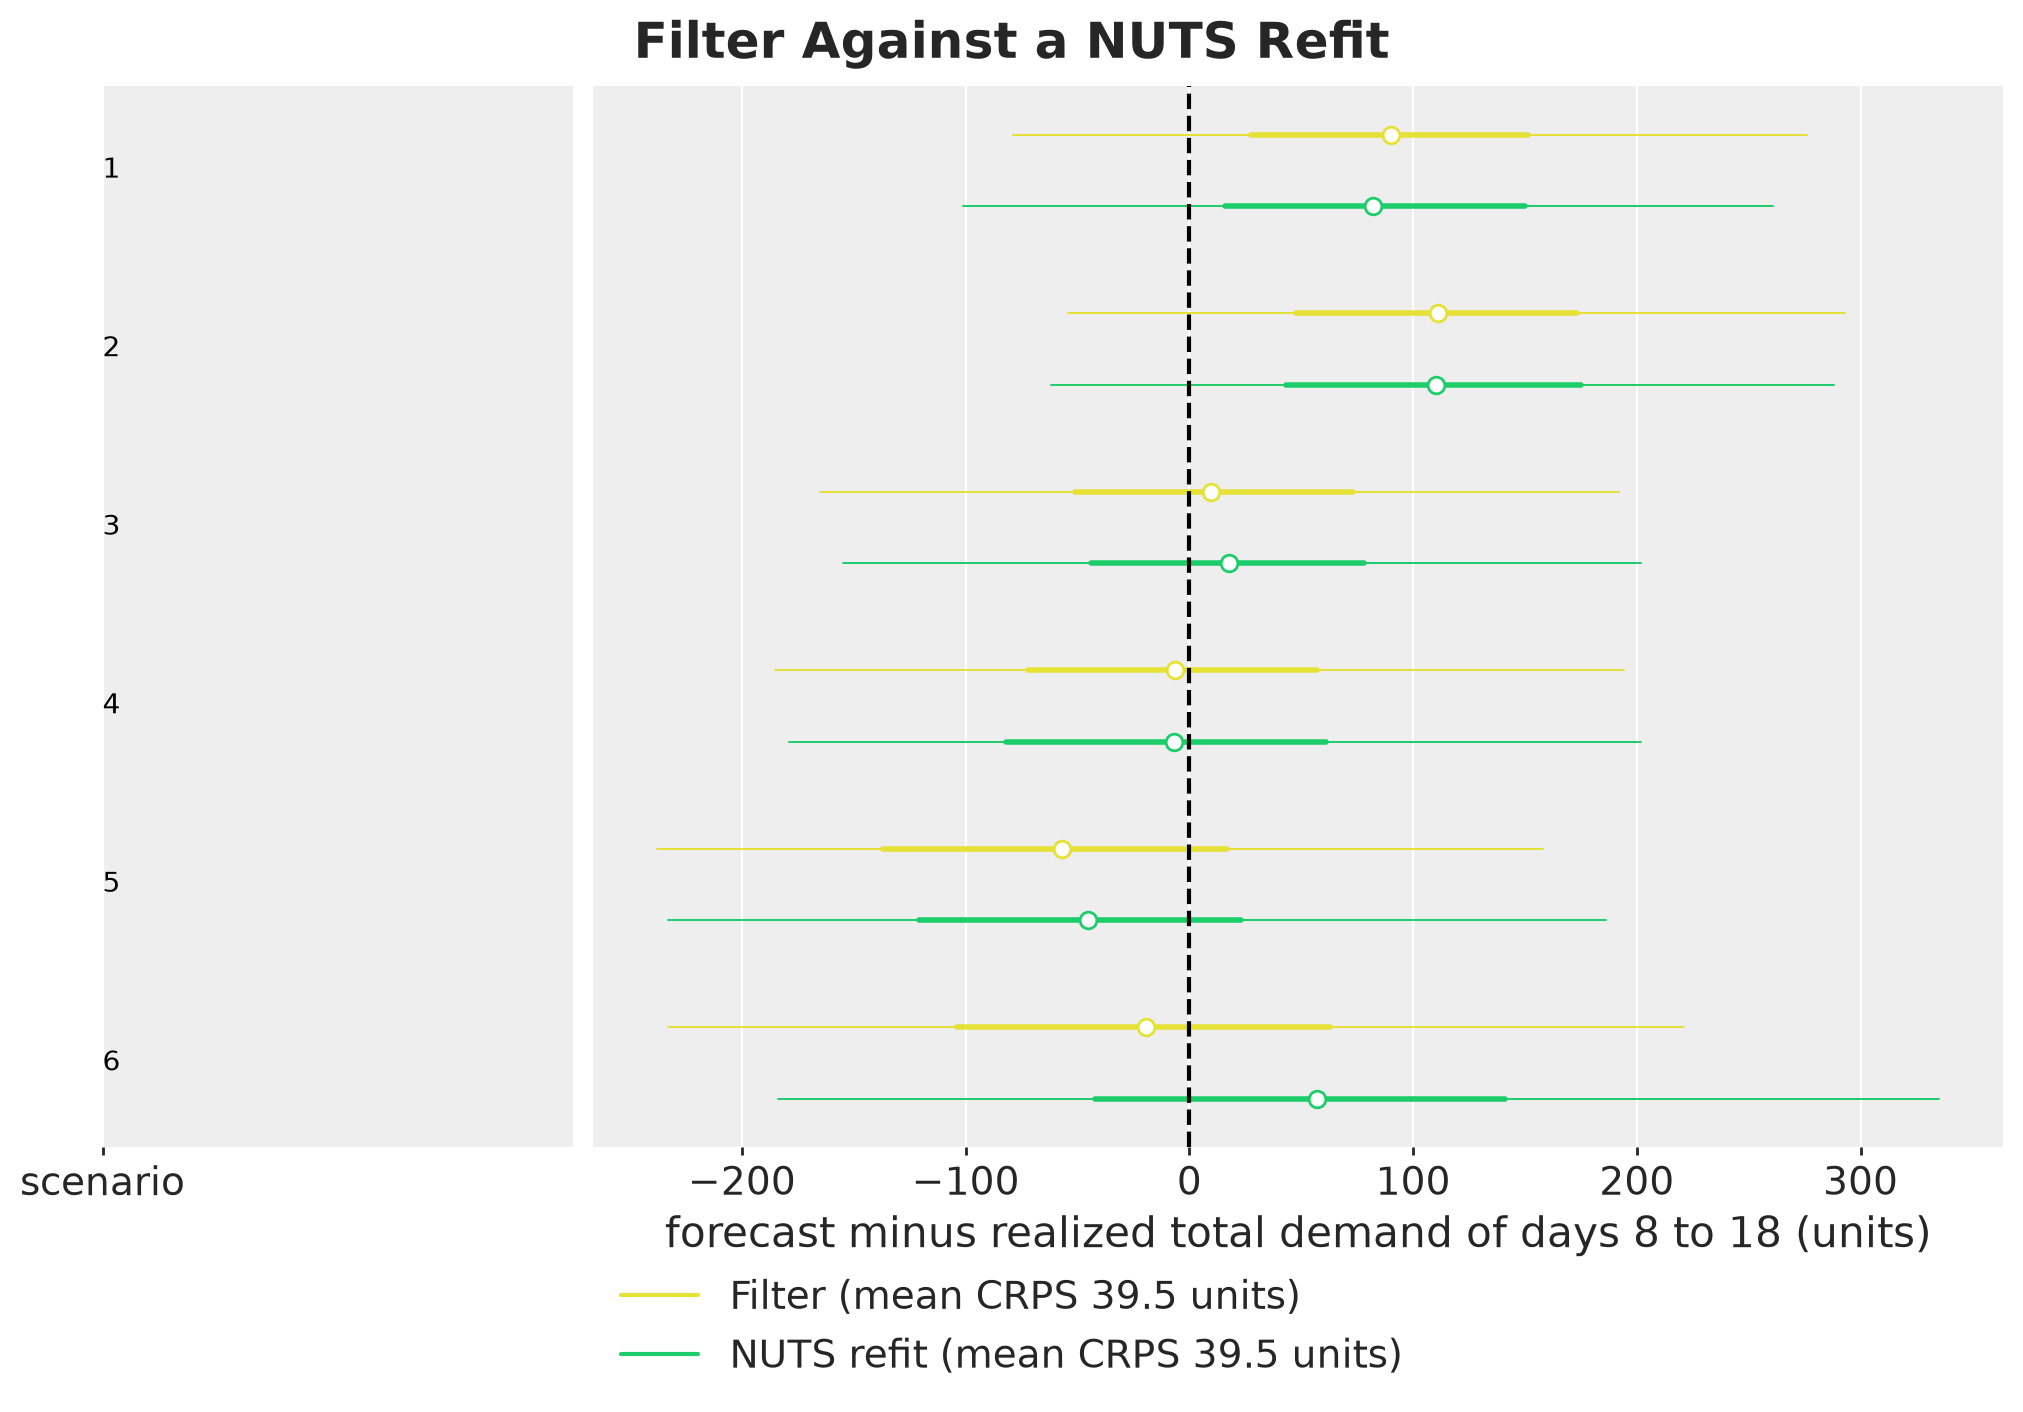

In [62]:
ERROR = "forecast minus realized demand"
error_draws = {
    name: xr.Dataset(
        {ERROR: (("sample", "scenario"), errors)},
        coords={"scenario": list(range(1, NUM_CHECK_SCENARIOS + 1))},
    )
    for name, errors in forecast_errors.items()
}
# the CRPS of the forecast error against zero, averaged over the scenarios
crps = {
    name: float(crps_empirical(errors, jnp.zeros(NUM_CHECK_SCENARIOS)).mean())
    for name, errors in forecast_errors.items()
}

pc = az.plot_forest(
    {
        f"{name} (mean CRPS {crps[name]:.1f} units)": dataset
        for name, dataset in error_draws.items()
    },
    sample_dims=["sample"],
    labels=["scenario"],
    color=["C6", "C7"],
    figure_kwargs={"figsize": (10, 7)},
)
ax = pc.viz["plot"].sel(column="forest").item()
ax.axvline(0.0, color="black", linestyle="--")
ax.set(
    xlabel=f"forecast minus realized total demand of days {NUM_OBSERVED + 1} "
    f"to {setup.max_days} (units)"
)
pc.add_legend("model", title="", loc="outside lower center", ncol=1)
pc.viz["figure"].item().suptitle(
    "Filter Against a NUTS Refit", fontsize=18, fontweight="bold"
);

The dots are the means and the thick and thin bars the $50\%$ and $94\%$ intervals. The intervals of the two forecasts are about as wide, except in scenario $6$, where the interval of the refit is wider. The mean CRPS is $39.5$ units for both forecasts. So the filter is close to a refit at a small fraction of its cost, and it reacts less than a refit to the highest first week.

## References

- Orduz, J. (2026). [From Forecasts to Decisions: Inventory Planning with Probabilistic Programming](https://juanitorduz.github.io/forecast_to_decision/). Personal blog.
- Orduz, J. (2026). [From Forecasts to Decisions: Cannibalization and Shared Capacity](https://juanitorduz.github.io/forecast_to_decision_cannibalization/). Personal blog.
- Alvo, M., Russo, D., Kanoria, Y. and Lee, M. (2023). [Deep Reinforcement Learning for Inventory Networks: Toward Reliable Policy Optimization](https://arxiv.org/abs/2306.11246). arXiv:2306.11246.
- Zipkin, P. (2008). [Old and New Methods for Lost-Sales Inventory Systems](https://ideas.repec.org/a/inm/oropre/v56y2008i5p1256-1263.html). *Operations Research*, 56(5), 1256-1263.
- Bijvank, M. and Vis, I. F. A. (2011). [Lost-sales inventory theory: A review](https://research.rug.nl/en/publications/lost-sales-inventory-theory-a-review). *European Journal of Operational Research*, 215(1), 1-13.
- Huh, W. T., Janakiraman, G., Muckstadt, J. A. and Rusmevichientong, P. (2009). [Asymptotic Optimality of Order-Up-To Policies in Lost Sales Inventory Systems](https://www.columbia.edu/~th2113/files/MS_LostSales_Asymptotic_09.pdf). *Management Science*, 55(3), 404-420.
- Goldberg, D. A., Katz-Rogozhnikov, D. A., Lu, Y., Sharma, M. and Squillante, M. S. (2016). [Asymptotic Optimality of Constant-Order Policies for Lost Sales Inventory Models with Large Lead Times](https://arxiv.org/abs/1211.4063). *Mathematics of Operations Research*, 41(3), 898-913.
- Gijsbrechts, J., Boute, R. N., Van Mieghem, J. A. and Zhang, D. J. (2022). [Can Deep Reinforcement Learning Improve Inventory Management? Performance on Lost Sales, Dual-Sourcing, and Multi-Echelon Problems](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=3302881). *Manufacturing & Service Operations Management*, 24(3), 1349-1368.
- Särkkä, S. and Svensson, L. (2023). [Bayesian Filtering and Smoothing](https://users.aalto.fi/~ssarkka/pub/bfs_book_2023_online.pdf). Second edition. Cambridge University Press.
- Szabłowski, B. (2026). [One Global Model, Many Behaviors: Stockout-Aware Feature Engineering and Dynamic Scaling for Multi-Horizon Retail Demand Forecasting with a Cost-Aware Ordering Policy (VN2 Winner Report)](https://arxiv.org/abs/2601.18919). arXiv:2601.18919.
- Caron, K. (2023). [Modeling Anything With First Principles: Demand under extreme stockouts](https://kylejcaron.github.io/posts/censored_demand/2024-02-06-censored-demand.html). Personal blog.
- Orduz, J. [NumPyro Forecast documentation](https://juanitorduz.github.io/numpyro_forecast/).
- Orduz, J. [Getting Started with `dynestyx` State Space Models](https://juanitorduz.github.io/numpyro_forecast/v/dev/docs/examples/dynestyx_getting_started.html). NumPyro Forecast documentation, development version.
- Orduz, J. [State Space Models with `dynestyx` and `numpyro_forecast`](https://juanitorduz.github.io/numpyro_forecast/v/dev/docs/examples/dynestyx_integration.html). NumPyro Forecast documentation, development version.
- Basis Research. [`dynestyx` documentation](https://basisresearch.github.io/dynestyx/stable/).
- NumPyro team. [Effect Handlers in NumPyro: A Practical Guide](https://num.pyro.ai/en/stable/tutorials/effect_handlers.html). NumPyro documentation.
- DeepMind. [Optax documentation](https://optax.readthedocs.io/).
- Flax team. [Flax NNX basics](https://flax.readthedocs.io/en/latest/nnx_basics.html).